# Stage 2: Bivariate analysis (two variables at a time)

**Status (2026-10-28): Stage 2 is complete**, begun and finished on the owner's word (A14): every lens and companion
table screened, and every planned pair worked, in sections 1 (`rights`, B1 to B19), 2 (`firms`, B20 to B26), 3
(`regions`, B27 to B31), 4 (`national`, B32 to B35), 5 (`timeline`, B36 to B39), 6 (`industries`, B40 to B43) and 7
(`institutions`, B44 to B46), summarised in section 8 and `docs/stage-2-summary.md`. The method is in ADR 0030. The
evidence atlas (the website) is updated only when the owner says, now that Stage 2 is finished.

**Purpose.** Test how pairs of variables relate: whether they move together, in what shape, how strongly, and for
whom. This turns Stage 1's descriptions into early signals, and sorts the signals worth carrying into Stage 3 from
the ones that are mechanics of the IP system, quirks of the records, or chance.

**Two cautions.** With hundreds of thousands of rows almost any difference is "statistically significant", so the
size of an association matters more than its p-value, and every finding here leads with a size and an interval. And
two things moving together does not mean one causes the other: a third factor (the applicant's origin, the
technology, the period) often drives both. Each lead names its candidate third factors; Stage 3 tests them.

## How to read this notebook

- **Every observation is evidenced.** Observations are numbered (**B1**, **B2**, ...) and quote the numbers from the
  output cells directly above them. If a number is not on the page, it is not a finding.
- **Each observation is labelled with its strength of evidence**, as the research goal requires: *descriptive* (what
  the data shows), *observational* (an association that may have other explanations), *causal* (an effect, which needs
  a design this EDA does not have) or *projected* (an estimate of the future). Nearly everything in Stage 2 is
  observational.
- **Plain English first.** Technical terms are explained where they first appear and in
  [`GLOSSARY.md`](../../GLOSSARY.md).
- **Every chart names its source** underneath it.
- **Unit of analysis.** Each section works on one *lens*, a table with one row per thing being described, defined in
  [`analysis/eda/build.py`](../eda/build.py) and described column by column in
  [`analysis/eda/variables.yaml`](../eda/variables.yaml). Stage 1 (`01_univariate.ipynb`) profiled every column; its
  rules for using each one (`docs/stage-1-summary.md`, section 6) apply here.

## How each lens is worked through

Each lens section has two parts.

**1. The screen: every pair.** Every pair of the lens's variables is measured on one scale, its **strength**, from 0
(no association) to 1 (one variable fully determines the other), whatever the kinds of variable:

| Pair | Measure | What it says |
|---|---|---|
| two numbers | Spearman's rho (its size) | whether the two rise or fall together, in any shape, from their ranks |
| a number and a category | the rank correlation ratio | how much of the number's spread (in ranks) the categories account for |
| two categories | Cramér's V (corrected for many categories) | how far the categories go together beyond chance |

For two yes/no variables, or a yes/no and a number, the three measures give the same value, so the scale is shared.
By convention 0.1 is a small association, 0.3 a moderate one and 0.5 a strong one. Which columns are screened, and
why the others are not (identifiers, and dates whose content is in another column), is set in
[`analysis/eda/screens.yaml`](../eda/screens.yaml); a test checks that it names every column of the lens.

A pair becomes a **lead** only if it passes four tests:
1. its strength is at least 0.1 in the **discovery sample**;
2. it survives the **correction for the number of pairs tested** (the Benjamini-Hochberg false discovery rate below
   5%), because among hundreds of pairs some pass by chance;
3. it holds again, at 0.1 or more and in the same direction, in a **replication sample** that played no part in finding
   it (a second period, or the other random half of the lens);
4. it is not **by construction**: two versions of one measure, or a total and its parts, are screened but never
   counted as leads (`screens.yaml` lists them).

Leads that are versions of one finding (the origin of the filer and of the current holder, say) are reported once,
with the strongest version. Each lead gets a 95% **bootstrap interval** for its strength, its direction in words and
its **candidate third factors**: other variables tied to both members by at least 0.1.

**2. The planned pairs.** Stage 1 named the pairs worth a proper look (`docs/stage-1-summary.md`, section 7). Each is
measured in the units that mean something (a difference in grant rates in percentage points, a median in years),
with a 95% interval, in two periods, and with its third factors named.

A lead is a signal for Stage 3 to test, not a conclusion.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import bivariate as bi
from eda import sql, style
from eda import univariate as uni

style.setup()
pd.set_option("display.max_colwidth", 90)

## 1. Lens: IP rights (one row per right)

**Rules carried from Stage 1** (`docs/stage-1-summary.md`, section 6): rights are always compared within one type,
with standard patents, provisionals and second-tier patents apart; "who files" is the founding applicant
(`founding_australian`, `founder_type`); grant rates and times only for decided years; representation is
`representation` (an attorney is an agent of five or more applicants); lifetimes come from survival curves with
rights still in force kept as unfinished; trade mark expedite shares only on one side of November 2018; gender
estimates only for inventors in Australia.

**The two samples.** The screen's discovery sample is rights filed FY2010 to FY2019, old enough for most to be decided;
the replication sample is rights filed FY2000 to FY2009. A pair that holds in both periods is not an accident of one
decade. Each type of right is screened on its own, up to 200,000 rights per sample (a fixed pseudo-random selection),
because pooling types would mostly show that patents differ from trade marks.

### 1.0 The screen: every pair, within each type of right

In [2]:
RIGHT_TYPES = {
    "standard": "Standard patents",
    "trade_mark": "Trade marks",
    "design": "Designs",
    "provisional": "Provisional applications",
    "second_tier": "Second-tier patents",
    "pbr": "Plant breeder's rights",
}
GROUPS = bi.screens()["rights"]["groups"]


def lab(c):
    return bi.screen_label("rights", c)


rights_screen = {t: bi.run_screen("rights", t) for t in RIGHT_TYPES}
rights_leads = {t: bi.distinct_leads(s["verdicts"], GROUPS) for t, s in rights_screen.items()}
screen_summary = pd.DataFrame(
    {
        RIGHT_TYPES[t]: {
            "variables measured": len(
                set(s["discovery"].dropna(subset=["strength"])[["variable 1", "variable 2"]].to_numpy().ravel())
            ),
            "rows (discovery)": s["n"][0],
            "rows (replication)": s["n"][1],
            **bi.verdict_counts(s["verdicts"]).to_dict(),
            "distinct leads": len(rights_leads[t]),
        }
        for t, s in rights_screen.items()
    }
).T
display(screen_summary)
print("Distinct leads, all types:", sum(len(d) for d in rights_leads.values()))

,variables measured,rows (discovery),rows (replication),lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
Standard patents,53,200000,200000,490,85,683,0,113,582,59
Trade marks,43,200000,200000,304,22,465,0,105,1057,45
Designs,39,68339,51137,271,68,299,0,92,1223,33
Provisional applications,23,53540,71549,41,7,154,0,50,1701,9
Second-tier patents,51,18629,10368,436,158,566,0,108,685,63
Plant breeder's rights,27,3451,3607,107,29,130,0,64,1623,14


Distinct leads, all types: 223


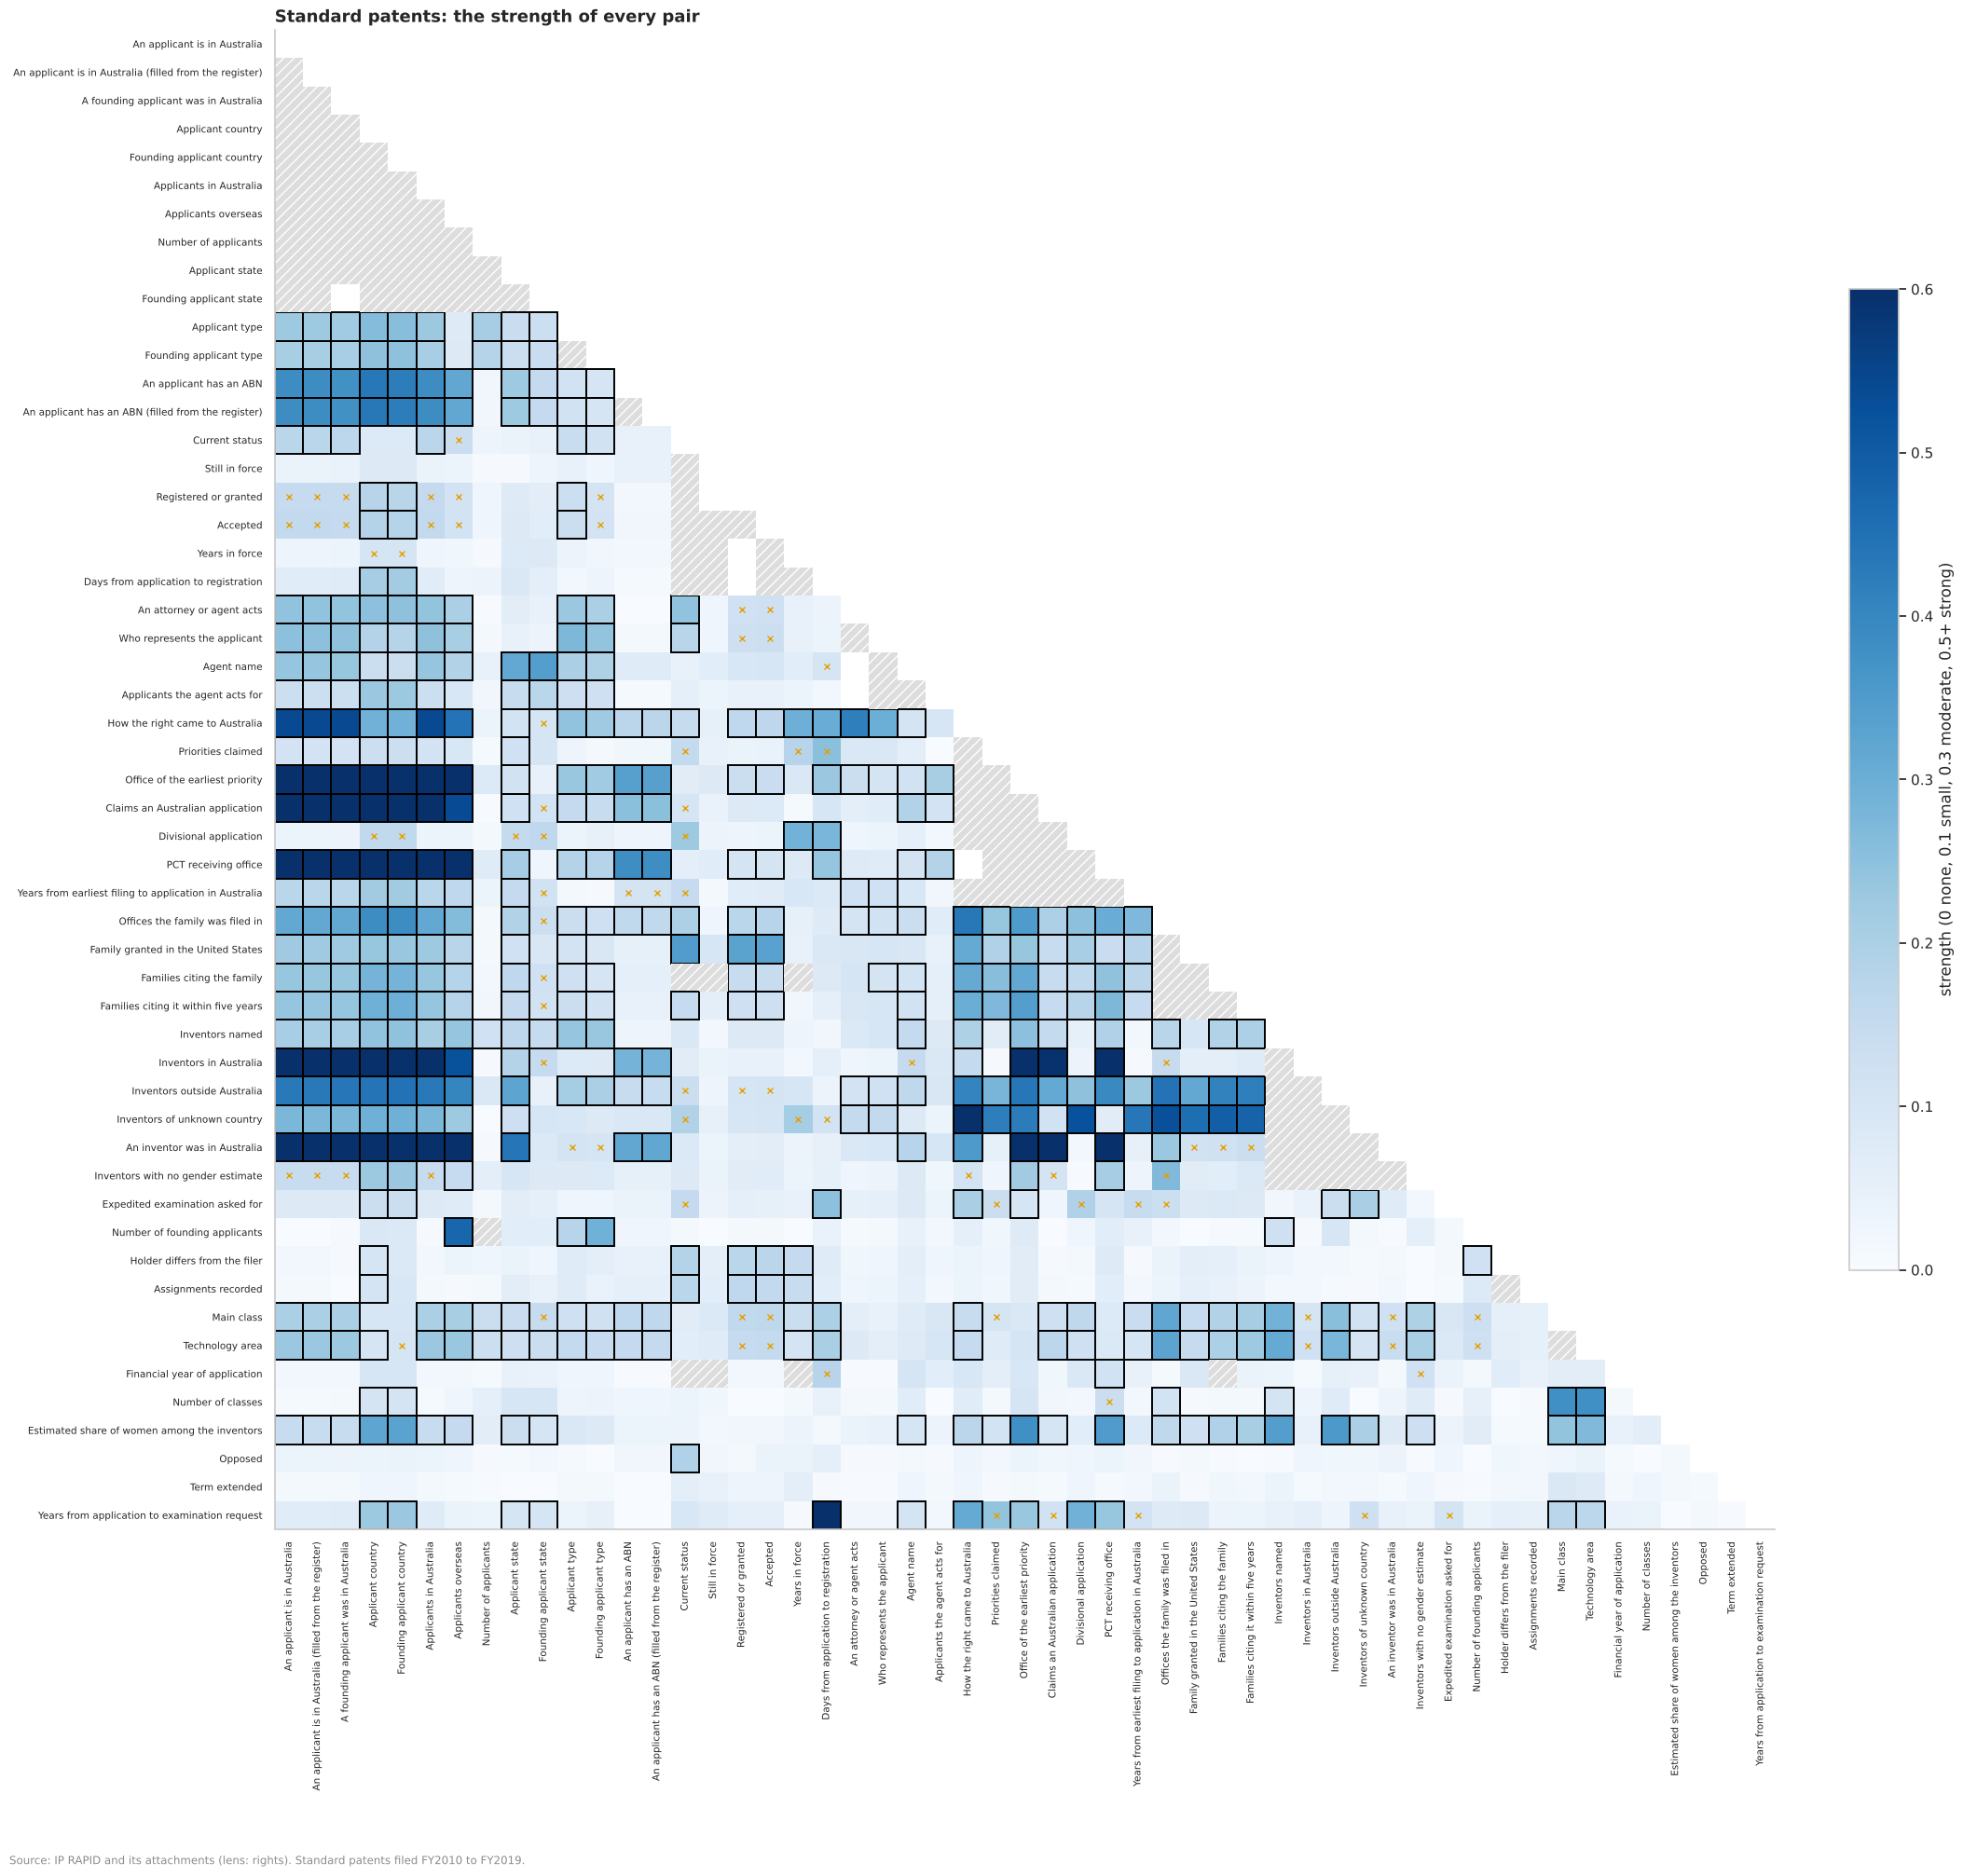

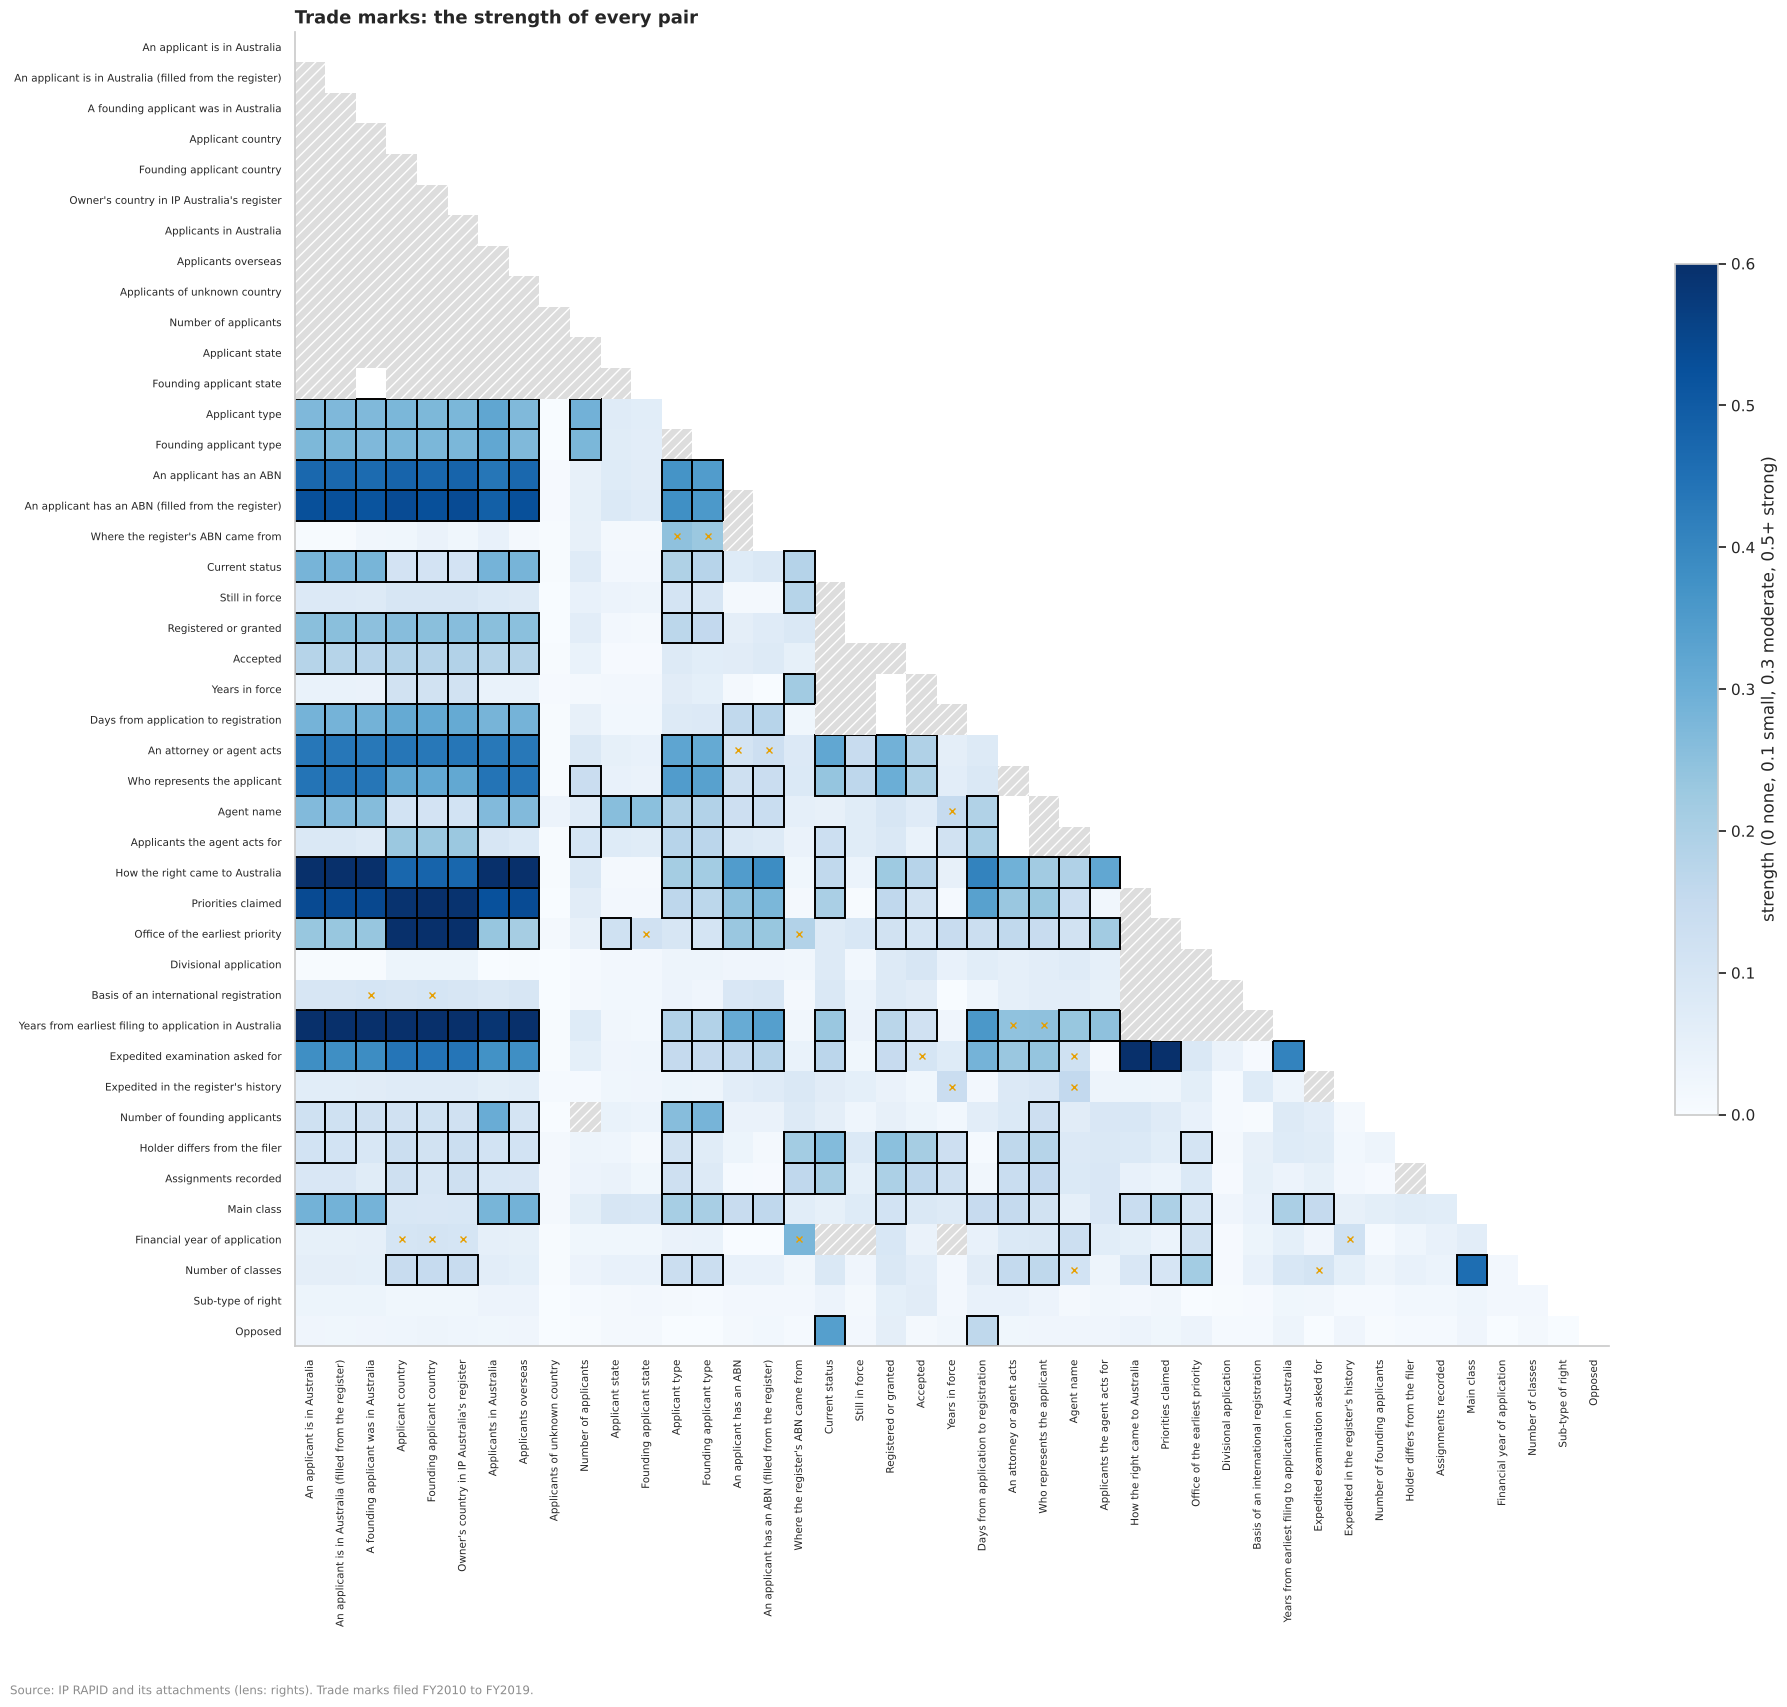

In [3]:
def screened_order(m):
    # the columns with at least one measured pair, in the order of their groups (so related measures sit together)
    measured = m.dropna(subset=["strength"])
    cols = set(measured["variable 1"]) | set(measured["variable 2"])
    grouped = [c for g in GROUPS.values() for c in g]
    return list(dict.fromkeys([c for c in grouped if c in cols] + sorted(cols)))


for t in ("standard", "trade_mark"):
    m = rights_screen[t]["verdicts"]
    fig = bi.strength_map(m, screened_order(m), label=lab, title=f"{RIGHT_TYPES[t]}: the strength of every pair")
    style.source(fig, f"IP RAPID and its attachments (lens: rights). {RIGHT_TYPES[t]} filed FY2010 to FY2019.")

Pairs measured in both samples: 5207
Agreement between the two samples' strengths (Spearman): 0.859
Leads whose strength differs between samples by more than 0.1: 264 of 1649


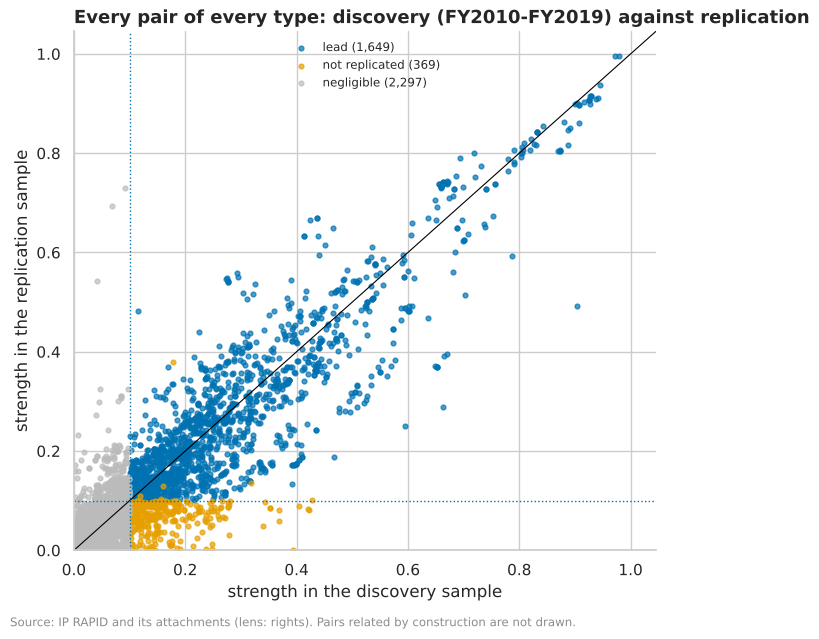

In [4]:
allv = pd.concat([s["verdicts"].assign(type=t) for t, s in rights_screen.items()])
fig = bi.replication_chart(allv, title="Every pair of every type: discovery (FY2010-FY2019) against replication")
style.source(fig, "IP RAPID and its attachments (lens: rights). Pairs related by construction are not drawn.")
print("Pairs measured in both samples:", allv["strength (replication)"].notna().sum())
ok = allv.dropna(subset=["strength", "strength (replication)"])
ok = ok[~ok["by construction"]]
print(
    "Agreement between the two samples' strengths (Spearman):",
    round(ok.strength.corr(ok["strength (replication)"], method="spearman"), 3),
)
print(
    "Leads whose strength differs between samples by more than 0.1:",
    int(((allv.verdict == "lead") & ((allv.strength - allv["strength (replication)"]).abs() > 0.1)).sum()),
    "of",
    int((allv.verdict == "lead").sum()),
)

The distinct leads, type by type (strength in discovery, its 95% interval, and in replication):

In [5]:
lead_tables = {}
for t in RIGHT_TYPES:
    s = rights_screen[t]
    lead_tables[t] = bi.leads_table(rights_leads[t], s["prepared"], s["discovery"], label=lab)
    print(f"\n{RIGHT_TYPES[t]}: {len(lead_tables[t])} distinct leads")
    with pd.option_context("display.max_rows", 100, "display.width", 250):
        display(lead_tables[t].round(3))


Standard patents: 59 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,A founding applicant was in Australia × PCT receiving office,cramer_v,0.945,0.942 to 0.949,0.938,strong,47,True with au (17.9× chance),"Applicants in Australia, An applicant is in Australia, An applicant is in Australia (f..."
1,PCT receiving office × An inventor was in Australia,cramer_v,0.907,0.902 to 0.911,0.86,strong,27,au with True (16.5× chance),"Inventors in Australia, A founding applicant was in Australia, Applicants in Australia"
2,A founding applicant was in Australia × An inventor was in Australia,cramer_v,0.892,0.888 to 0.895,0.851,strong,45,True with True (14.1× chance),"PCT receiving office, Founding applicant country, Applicants in Australia"
3,Days from application to registration × Years from application to examination request,spearman,0.83,0.829 to 0.832,0.817,strong,1,rises with,"How the right came to Australia, Divisional application, Priorities claimed"
4,Offices the family was filed in × Inventors of unknown country,spearman,0.526,0.522 to 0.529,0.582,strong,12,falls with,"Inventors outside Australia, How the right came to Australia, Families citing the family"
5,Applicants overseas × Number of founding applicants,spearman,0.475,0.468 to 0.482,0.401,moderate,1,rises with,"Number of applicants, Main class, Technology area"
6,Applicant country × An applicant has an ABN (filled from the register),cramer_v,0.432,0.428 to 0.437,0.389,moderate,18,au with True (3.5× chance),"An applicant has an ABN, Founding applicant country, An applicant is in Australia"
7,How the right came to Australia × Offices the family was filed in,rank_eta,0.431,0.427 to 0.434,0.481,moderate,28,"Offices the family was filed in: highest median for pct (7), lowest for australian_pri...","Inventors of unknown country, Inventors outside Australia, Office of the earliest prio..."
8,An attorney or agent acts × How the right came to Australia,cramer_v,0.415,0.402 to 0.429,0.317,moderate,13,False with direct (27.2× chance),"Who represents the applicant, Applicant country, Founding applicant country"
9,Applicant country × Offices the family was filed in,rank_eta,0.386,0.383 to 0.390,0.489,moderate,32,"Offices the family was filed in: highest median for it (9), lowest for au (2)","Inventors outside Australia, Founding applicant country, Office of the earliest priority"



Trade marks: 45 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Expedited examination asked for × Priorities claimed,rank_eta,0.78,0.777 to 0.784,0.763,strong,3,"Priorities claimed: highest median for True (1), lowest for False (0)","How the right came to Australia, Founding applicant country, Owner's country in IP Aus..."
1,Founding applicant country × Office of the earliest priority,cramer_v,0.731,0.727 to 0.735,0.774,strong,33,at with at (91.8× chance),"Applicant country, Owner's country in IP Australia's register, Years from earliest fil..."
2,Applicant country × An applicant has an ABN (filled from the register),cramer_v,0.535,0.532 to 0.539,0.507,strong,16,se with False (1.8× chance),"Owner's country in IP Australia's register, An applicant is in Australia, An applicant..."
3,Main class × Number of classes,rank_eta,0.457,0.453 to 0.460,0.453,moderate,1,"Number of classes: highest median for 16 (3), lowest for 10 (1)","An attorney or agent acts, Applicant type, Founding applicant type"
4,Founding applicant country × Expedited examination asked for,cramer_v,0.444,0.438 to 0.448,0.385,moderate,8,at with True (3.3× chance),"Priorities claimed, How the right came to Australia, Owner's country in IP Australia's..."
5,Applicants in Australia × Who represents the applicant,rank_eta,0.442,0.439 to 0.445,0.427,moderate,31,"Applicants in Australia: highest median for self (1), lowest for attorney (0)","An applicant is in Australia (filled from the register), An applicant is in Australia,..."
6,Days from application to registration × How the right came to Australia,rank_eta,0.406,0.402 to 0.411,0.471,moderate,16,"Days from application to registration: highest median for divisional (620), lowest for...","Years from earliest filing to application in Australia, Priorities claimed, Founding a..."
7,An applicant has an ABN (filled from the register) × How the right came to Australia,cramer_v,0.385,0.382 to 0.388,0.337,moderate,8,False with madrid (1.7× chance),"An applicant is in Australia, An applicant is in Australia (filled from the register),..."
8,Applicant type × An applicant has an ABN (filled from the register),cramer_v,0.379,0.376 to 0.383,0.431,moderate,4,individual with False (1.8× chance),"An applicant has an ABN, Founding applicant type, Applicants in Australia"
9,Applicant type × Who represents the applicant,cramer_v,0.347,0.342 to 0.350,0.384,moderate,8,individual with self (2.0× chance),"Founding applicant type, An attorney or agent acts, Applicants in Australia"



Designs: 33 distinct leads


...

,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Applicant type × An applicant has an ABN,cramer_v,0.757,0.751 to 0.763,0.738,strong,4,individual with False (1.8× chance),"An applicant has an ABN (filled from the register), Founding applicant type, Estimated..."
1,Applicants in Australia × Number of founding applicants,spearman,0.693,0.680 to 0.704,0.79,strong,1,rises with,"Number of applicants, Applicant type, Founding applicant type"
2,Number of founding applicants × Founding applicant type,rank_eta,0.23,0.224 to 0.237,0.22,small,2,"Number of founding applicants: highest mean for individual (1.187), lowest for organis...","Applicant type, Number of applicants, Applicants in Australia"
3,Applicant type × Applicants in Australia,rank_eta,0.221,0.214 to 0.227,0.254,small,11,"Applicants in Australia: highest mean for individual (1.144), lowest for organisation ...","Number of applicants, Number of founding applicants, Founding applicant type"
4,Applicant country × Estimated share of women among the register's inventors,rank_eta,0.207,0.202 to 0.214,0.196,small,7,Estimated share of women among the register's inventors: highest median for us (0.0028...,"Founding applicant country, An applicant is in Australia, An applicant is in Australia..."
5,Founding applicant type × Estimated share of women among the register's inventors,rank_eta,0.157,0.148 to 0.166,0.206,small,2,Estimated share of women among the register's inventors: highest median for organisati...,"Applicant type, An applicant has an ABN, An applicant has an ABN (filled from the regi..."
6,An applicant has an ABN (filled from the register) × Estimated share of women among th...,rank_eta,0.152,0.143 to 0.161,0.198,small,2,Estimated share of women among the register's inventors: highest median for True (0.07...,"Founding applicant type, Applicant type, An applicant has an ABN"
7,Applicant country × An applicant has an ABN,cramer_v,0.127,0.122 to 0.134,0.112,small,10,gi with True (2.1× chance),"Estimated share of women among the register's inventors, An applicant has an ABN (fill..."
8,An applicant has an ABN × Number of founding applicants,rank_eta,0.103,0.094 to 0.110,0.118,small,2,"Number of founding applicants: highest mean for False (1.127), lowest for True (1.057)","Founding applicant type, Applicant type, Inventors named in IP Australia's register (p..."



Second-tier patents: 63 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,A founding applicant was in Australia × An inventor was in Australia,cramer_v,0.941,0.927 to 0.954,0.911,strong,32,True with True (3.0× chance),"Founding applicant country, An applicant is in Australia, An applicant is in Australia..."
1,A founding applicant was in Australia × Office of the earliest priority,cramer_v,0.916,0.905 to 0.926,0.903,strong,30,False with in (2.0× chance),"An applicant is in Australia, An applicant is in Australia (filled from the register),..."
2,Office of the earliest priority × An inventor was in Australia,cramer_v,0.88,0.849 to 0.901,0.863,strong,16,au with True (4.1× chance),"A founding applicant was in Australia, An applicant is in Australia, An applicant is i..."
3,Offices the family was filed in × Inventors outside Australia,spearman,0.72,0.707 to 0.730,0.751,strong,19,rises with,"Office of the earliest priority, How the right came to Australia, Inventors of unknown..."
4,Office of the earliest priority × Offices the family was filed in,rank_eta,0.686,0.666 to 0.705,0.755,strong,13,"Offices the family was filed in: highest median for tw (4), lowest for au (1)","Inventors outside Australia, How the right came to Australia, Families citing the family"
5,An applicant has an ABN × An inventor was in Australia,cramer_v,0.551,0.518 to 0.575,0.36,strong,4,True with True (2.3× chance),"An applicant has an ABN (filled from the register), Office of the earliest priority, A..."
6,Current status × An attorney or agent acts,cramer_v,0.491,0.482 to 0.500,0.474,moderate,12,lapsed with False (3.3× chance),"Registered or granted, Who represents the applicant, Years in force"
7,Applicant type × Who represents the applicant,cramer_v,0.458,0.444 to 0.467,0.382,moderate,8,individual with self (1.8× chance),"Founding applicant type, An attorney or agent acts, Applicants in Australia"
8,A founding applicant was in Australia × Agent name,cramer_v,0.454,0.444 to 0.471,0.355,moderate,23,False with leoniepat (2.1× chance),"An applicant is in Australia, An applicant is in Australia (filled from the register),..."
9,Founding applicant country × Offices the family was filed in,rank_eta,0.445,0.436 to 0.460,0.424,moderate,28,"Offices the family was filed in: highest median for vg (4), lowest for au (1)","Office of the earliest priority, Inventors outside Australia, Applicant country"



Plant breeder's rights: 14 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Applicant country × An attorney or agent acts,cramer_v,0.67,0.648 to 0.687,0.74,strong,26,au with False (2.1× chance),"Founding applicant country, An applicant is in Australia, An applicant is in Australia..."
1,Founding applicant type × Agent name,cramer_v,0.573,0.539 to 0.611,0.446,strong,2,individual with 2021c22c-85e8-42f5-8ea7-6662f6a0fb0f (3.7× chance),"Applicant type, Main class, Founding applicant country"
2,Number of applicants × Holder differs from the filer,rank_eta,0.531,0.478 to 0.593,0.482,strong,4,"Number of applicants: highest mean for True (1.392), lowest for False (1)","Main class, Applicants in Australia, Founding applicant state"
3,Applicants overseas × Main class,rank_eta,0.513,0.487 to 0.534,0.544,strong,9,"Applicants overseas: highest median for vitis (1), lowest for brassica (0)","An applicant is in Australia, An applicant is in Australia (filled from the register),..."
4,Main class × Agent name,cramer_v,0.489,0.470 to 0.510,0.414,moderate,4,rosa with 1bb69e3e-2d07-4cec-a900-d5b8b0a340ce (26.1× chance),"Applicants overseas, An applicant is in Australia, An applicant is in Australia (fille..."
5,Agent name × Still in force,cramer_v,0.45,0.417 to 0.492,0.488,moderate,11,3362bc56-4677-460b-9bea-0556c88221d2 with False (2.5× chance),"Years in force, Main class, Current status"
6,Days from application to registration × Main class,rank_eta,0.336,0.314 to 0.377,0.357,moderate,5,"Days from application to registration: highest median for citrus (2,692), lowest for s...","Agent name, Applicant state, Years in force"
7,Applicant type × Main class,cramer_v,0.296,0.283 to 0.324,0.276,small,2,individual with rosa (2.1× chance),"Agent name, Founding applicant type, Founding applicant country"
8,Financial year of application × Agent name,rank_eta,0.276,0.257 to 0.334,0.224,small,1,Financial year of application: highest median for 53bf33ed-b1db-4330-a97f-be61722e90ac...,"Years in force, Current status, Still in force"
9,Days from application to registration × Applicant state,rank_eta,0.27,0.212 to 0.340,0.319,small,30,"Days from application to registration: highest median for other (1,329), lowest for sa...","Main class, Founding applicant state, Applicant country"


In [6]:
# A record quirk the screen points to (designs: status against applicants of unknown country): IP RAPID's origin of
# designs by status, and after the register's fill (ADR 0029)
sql("""
    SELECT CASE WHEN filing_fy >= 2010 THEN 'FY2010-FY2019' ELSE 'FY2000-FY2009' END AS period, status,
           count(*) AS designs,
           100 * avg((applicants_country_unknown > 0)::int) AS "an applicant of unknown country (%)",
           100 * avg((australian_applicant IS NULL)::int) AS "origin unknown (%)",
           100 * avg((australian_applicant_filled IS NULL)::int) AS "origin unknown, filled (%)"
    FROM {lens/rights} WHERE ip_right_type = 'design' AND filing_fy BETWEEN 2000 AND 2019
    GROUP BY ALL HAVING count(*) >= 100 ORDER BY 1, 3 DESC
""").set_index(["period", "status"]).round(2)

designs  an applicant of unknown country (%)  origin unknown (%)  origin unknown, filled (%)
period        status                                                                                                  
FY2000-FY2009 ceased        45348                                 0.08                0.07                        0.07
              lapsed         5035                                  100                 100                        0.73
              withdrawn       560                                  100                 100                        0.89
FY2010-FY2019 ceased        53008                                 0.22                0.22                        0.22
              registered     9880                                 0.01                0.01                        0.01
              lapsed         2680                                  100                 100                        1.12
              certified      2204                                    0                   0                           0
              withdrawn       446                                99.78                 100                        3.81

#### Observations
**B1 (descriptive). The screen of the rights lens: 223 distinct leads, all of them past the correction for the
number of pairs, most of them holding in a second decade.**
- Six types of right were screened, each on up to 200,000 rights filed FY2010 to FY2019 and again on those filed
  FY2000 to FY2009; 23 (provisionals) to 53 (standard patents) variables had at least one measured pair.
- **Leads:** 490 pairs for standard patents, 304 for trade marks, 271 for designs, 41 for provisionals, 436 for
  second-tier patents and 107 for plant breeder's rights; as distinct pairs of measures, 59, 45, 33, 9, 63 and 14
  (223 in all, as printed). 85, 22, 68, 7, 158 and 29 pairs passed in the first decade but did not hold in the second.
- **No pair failed on the correction alone** ("not significant": 0 for every type): with samples this large the
  conventional threshold of 0.1 and the second decade did all the sorting, as expected.
- **The two decades agree closely:** across the 5,207 pairs measured in both, the strengths' order agrees with a
  Spearman rho of 0.859. Of 1,649 leads, 264 differ between the decades by more than 0.1, so a lead's size is often
  period-specific even when its existence is not.

**B2 (descriptive). The strongest leads are mechanics of the IP system, recorded and not carried forward.** Each is
expected from how rights are filed and recorded:
- Australian filers file their PCT applications at IP Australia (filer origin × PCT receiving office 0.945, interval
  0.942 to 0.949; 0.938 in FY2000 to FY2009; the filer in Australia with `au` 17.9 times chance), and the inventions
  they file are made here (filer origin × an inventor in Australia 0.892, interval 0.888 to 0.895; 0.851).
- A standard patent's time to grant rises with the time its owner waits before asking for examination (rho 0.83,
  interval 0.829 to 0.832; 0.817): the applicant, not only the office, sets the pace.
- Wider families have fewer inventors of unknown country (rho 0.526; 0.582): Google Patents takes inventors' countries
  from foreign publications, which narrow families lack (U95).
- Trade marks: expedited examination goes with a priority claim (0.78; 0.763), the recording U103 explained, and a
  founding applicant's country with its priority office (0.731; 0.774).
- Provisionals: individuals have no ABN (0.757; 0.738).

**B3 (descriptive). A record quirk: IP RAPID gives no applicant country for designs that were never registered.** The
screen's strongest design pair is status against applicants of unknown country (0.98, interval 0.976 to 0.982; 0.996
in FY2000 to FY2009). In the table above, every lapsed and every withdrawn design in both decades is of unknown
origin in IP RAPID (100%), against 0.22% of ceased and 0.01% of registered ones filed FY2010 to FY2019. The register's
countries fill nearly all of them (after the fill, 1.12% of lapsed and 3.81% of withdrawn designs filed FY2010 to
FY2019 remain unknown). So IP RAPID's "origin unknown" designs (U7, U13) are, in recent decades, the applications that
never reached registration: an origin comparison on IP RAPID alone drops failed applications, and must use the
filled origin (ADR 0029).

**B4 (observational). The substantive leads, and where each is followed up.** Read with their candidate third
factors (above); all hold in both decades:
- **Representation and outcome** (section 1.1): a standard patent with no attorney or agent is more often withdrawn
  (status × an agent acts 0.243; 0.217; withdrawn with no agent 28.0 times chance), as are trade marks (0.317;
  0.274), second-tier patents (0.491; 0.474) and designs filed through an agent who is not an attorney (representation
  × registered 0.323; 0.281).
- **Origin and reach** (1.3): the offices a standard patent's family is filed in vary with its route (0.431; 0.481),
  the applicant's country (0.386; 0.489: a median of 2 for Australian applicants, 9 for Italian) and the technology
  (0.328; 0.31: organic fine chemistry a median of 11).
- **Technology and inventors' gender** (1.6): the estimated share of women among a standard patent's inventors
  varies with the technology area (0.268; 0.297; biotechnology highest). Its strongest leads, with the priority
  office (0.378) and the applicant's country (0.329), are led by China, whose estimates U97 found unreliable: a
  quirk of the name dictionary, not a finding. Provisionals' inventors: organisations' have more women than
  individuals' (0.157; 0.206).
- **Place and representation:** the founding applicant's state goes with the attorney firm (0.342; 0.389; South
  Australia with Collison & Co 14.9 times chance): attorney markets are local.
- **Trade marks:** individuals go with clothing (class 25, 2.1 times chance; applicant type × class 0.207; 0.205);
  overseas applicants with medical apparatus (class 10, 1.9 times; 0.287; 0.294); attorneys file more classes per
  mark (a mean 1.958 against 1.466 for applicants filing alone; 0.163; 0.154).
- **Lifetimes:** designs' years in force vary with the Locarno class (0.288; 0.221: a median 9.41 years for class 04,
  5 for class 02, clothing); second-tier patents' with the applicant's country (0.379; 0.217: China lowest, a median
  2.54 years) and with having an ABN (0.201; 0.198: a median 6.54 years against 3.54).
- **Plant breeder's rights:** the genus goes with overseas applicants (0.513; 0.544; grapes, `vitis`, highest) and with
  the time to grant (0.336; 0.357; citrus a median 2,692 days).

### 1.1 Filing alone, and what comes of it, by origin, applicant type and representation

**From:** U11, U20, U33. **Informs:** Q2, Q4. Who files without an attorney, and whether those applications are
granted or registered as often, and as fast. Decided years only (filed FY2000 to FY2019); both periods shown.

share                           n              
period                              FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019
t          filer                                                                           
design     Australian individuals          0.0215        0.2279          8144          5898
           Australian organisations        0.2119        0.2044         14555         19634
           overseas individuals            0.0102        0.0689          1568          2235
           overseas organisations          0.0079        0.0112         21117         37289
standard   Australian individuals          0.1977        0.2606          8047          6320
           Australian organisations        0.0697        0.0352         16471         19330
           overseas individuals            0.0135        0.0114         15877         14483
           overseas organisations          0.0014        0.0028        196232        235507
trade_mark Australian individuals          0.5882        0.6829         90482        112275
           Australian organisations        0.4267        0.4023        245437        318331
           overseas individuals            0.2233        0.1074          8495         10722
           overseas organisations          0.1047        0.0537        156638        235831

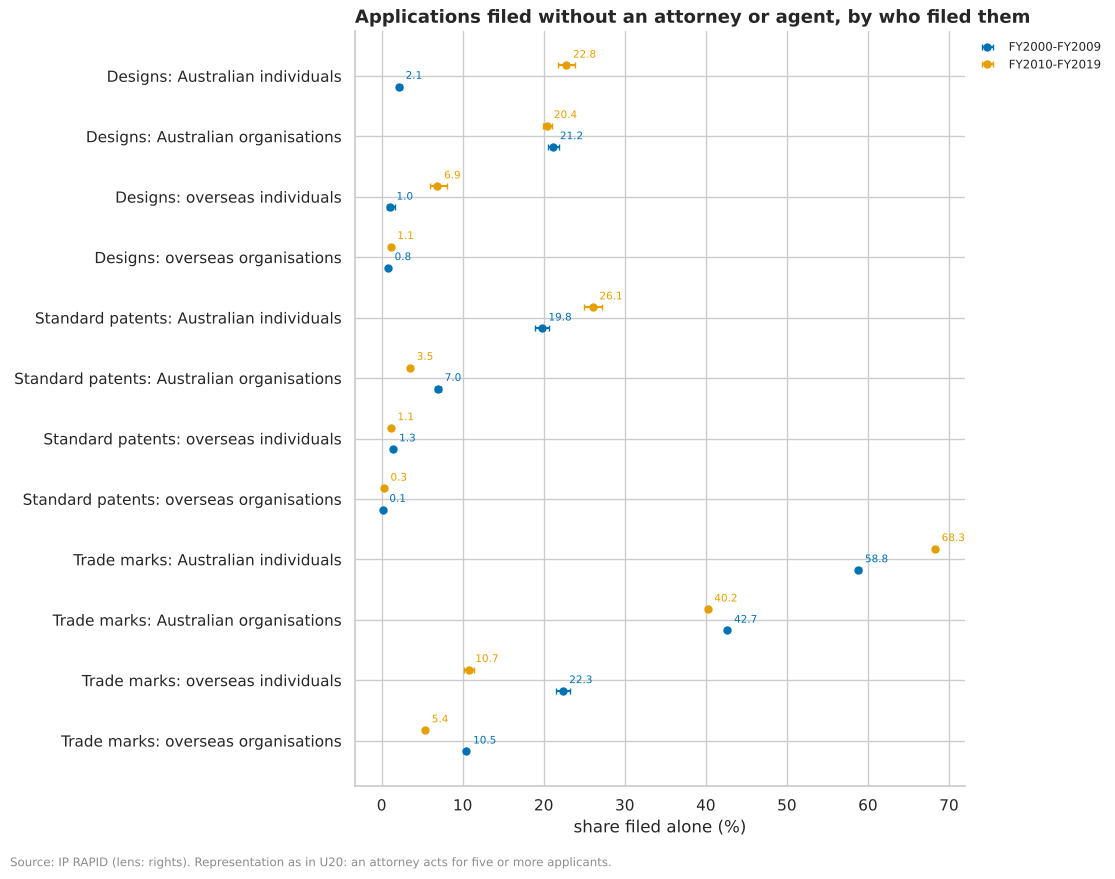

In [7]:
FILER = "CASE WHEN founding_australian THEN 'Australian ' ELSE 'overseas ' END || founder_type || 's'"
PERIOD = (
    "CASE WHEN filing_fy BETWEEN 2010 AND 2019 THEN 'FY2010-FY2019'"
    " WHEN filing_fy BETWEEN 2000 AND 2009 THEN 'FY2000-FY2009' END"
)
SHORT = {"standard": "Standard patents", "trade_mark": "Trade marks", "design": "Designs"}


def rsql(q, **kw):
    # sql() with the shorthands @FILER (who filed: origin and type) and @PERIOD (the two decades)
    return sql(q.replace("@FILER", FILER).replace("@PERIOD", PERIOD), **kw)


rep = rsql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, @PERIOD AS period, @FILER AS filer, representation,
           count(*) AS n, count(*) FILTER (registered_date IS NOT NULL) AS registered,
           count(*) FILTER (exam_requested_date IS NOT NULL) AS exam_requested
    FROM {lens/rights}
    WHERE filing_fy BETWEEN 2000 AND 2019
      AND coalesce(patent_type, ip_right_type) IN ('standard', 'trade_mark', 'design')
      AND founding_australian IS NOT NULL AND founder_type IS NOT NULL AND representation IS NOT NULL
    GROUP BY ALL
""")
alone = (
    rep.assign(alone=rep.n.where(rep.representation == "self", 0))
    .groupby(["t", "filer", "period"])[["alone", "n"]]
    .sum()
)
alone["share"] = alone.alone / alone.n
alone["low"], alone["high"] = bi.wilson(alone.alone, alone.n)
plot = alone.reset_index()
plot.index = plot.t.map(SHORT) + ": " + plot.filer
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    title="Applications filed without an attorney or agent, by who filed them",
    xlabel="share filed alone",
)
style.source(fig, "IP RAPID (lens: rights). Representation as in U20: an attorney acts for five or more applicants.")
alone.unstack("period")[["share", "n"]].round(4)

In [8]:
# Among Australian filers: how often an application is granted or registered, by representation, and the gap between
# an attorney and filing alone (percentage points, with Newcombe's 95% interval)
au = (
    rep[rep.filer.str.startswith("Australian")]
    .groupby(["t", "filer", "period", "representation"])[["registered", "exam_requested", "n"]]
    .sum()
)
au["granted (%)"] = 100 * au.registered / au.n
lo, hi = bi.wilson(au.registered, au.n)
au["low"], au["high"] = 100 * lo, 100 * hi
display(au[["n", "granted (%)", "low", "high"]].round(1).unstack("period"))
gaps = []
for (t, filer, period), d in au.groupby(level=[0, 1, 2]):
    d = d.droplevel([0, 1, 2])
    if {"attorney", "self"} <= set(d.index):
        a, s = d.loc["attorney"], d.loc["self"]
        diff, dl, dh = bi.rate_difference(a.registered, a.n, s.registered, s.n)
        row = {
            "type": SHORT[t],
            "filer": filer,
            "period": period,
            "attorney - alone (points)": 100 * diff,
            "low": 100 * dl,
            "high": 100 * dh,
        }
        if t == "standard":
            # the same gap among applications whose examination was requested (a standard patent is granted only
            # after examination)
            diff, dl, dh = bi.rate_difference(a.registered, a.exam_requested, s.registered, s.exam_requested)
            row |= {
                "among examined (points)": 100 * diff,
                "low (examined)": 100 * dl,
                "high (examined)": 100 * dh,
                "examination requested: attorney (%)": 100 * a.exam_requested / a.n,
                "examination requested: alone (%)": 100 * s.exam_requested / s.n,
            }
        gaps.append(row)
pd.DataFrame(gaps).set_index(["type", "filer", "period"]).round(1)

n                 granted (%)                         low                        high  \
period                                             FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009   
t          filer                    representation                                                                                                     
design     Australian individuals   attorney                2470          2527           100           100          99.8          99.8           100   
                                    other_agent             5499          2027           100           100          99.9          99.8           100   
                                    self                     175          1344           100          99.9          97.9          99.5           100   
           Australian organisations attorney               10230         14910           100          99.9           100          99.9           100   
                                    other_agent             1241           711           100          99.4          99.7          98.6           100   
                                    self                    3084          4013           100          99.9          99.9          99.7           100   
standard   Australian individuals   attorney                5447          4425          45.2          40.8          43.9          39.3          46.5   
                                    other_agent             1009           248          27.7          22.6            25          17.8          30.5   
                                    self                    1591          1647           8.3           4.9             7           3.9           9.8   
           Australian organisations attorney               15104         18579            56          49.7          55.2            49          56.8   
                                    other_agent              219            71          47.9          16.9          41.4           9.9          54.5   
                                    self                    1148           680          62.1           9.7          59.3           7.7          64.9   
trade_mark Australian individuals   attorney               13908         24417          71.6          73.9          70.9          73.3          72.4   
                                    other_agent            23355         11191          49.9          62.9          49.2            62          50.5   
                                    self                   53219         76667          48.5          49.6            48          49.3          48.9   
           Australian organisations attorney              120718        169463          75.2          77.8          74.9          77.6          75.4   
                                    other_agent            19994         20801          58.7          62.5            58          61.9          59.3   
                                    self                  104725        128067          53.9          54.2          53.6          53.9          54.2   

                                                                  
period                                             FY2010-FY2019  
t          filer                    representation                
design     Australian individuals   attorney                 100  
                                    other_agent              100  
                                    self                     100  
           Australian organisations attorney                99.9  
                                    other_agent             99.8  
                                    self                     100  
standard   Australian individuals   attorney                42.2  
                                    other_agent             28.2  
                                    self                       6  
           Australian organisations attorney                50.4  

attorney - alone (points)  low  high  among examined (points)  low (examined)  high (examined)  \
type             filer                    period                                                                                                          
Designs          Australian individuals   FY2000-FY2009                          0 -0.2   2.1                      NaN             NaN              NaN   
                                          FY2010-FY2019                        0.1 -0.1   0.5                      NaN             NaN              NaN   
                 Australian organisations FY2000-FY2009                          0   -0   0.1                      NaN             NaN              NaN   
                                          FY2010-FY2019                          0 -0.1   0.2                      NaN             NaN              NaN   
Standard patents Australian individuals   FY2000-FY2009                       36.9 34.9  38.7                     33.8            29.5             37.7   
                                          FY2010-FY2019                       35.9 34.1  37.6                     34.5            30.1             38.4   
                 Australian organisations FY2000-FY2009                       -6.1 -8.9  -3.1                    -17.7           -20.2              -15   
                                          FY2010-FY2019                         40 37.5  42.1                     25.3            18.6             31.4   
Trade marks      Australian individuals   FY2000-FY2009                       23.2 22.3    24                      NaN             NaN              NaN   
                                          FY2010-FY2019                       24.3 23.6  24.9                      NaN             NaN              NaN   
                 Australian organisations FY2000-FY2009                       21.3 20.9  21.6                      NaN             NaN              NaN   
                                          FY2010-FY2019                       23.6 23.3  23.9                      NaN             NaN              NaN   

                                                         examination requested: attorney (%)  examination requested: alone (%)  
type             filer                    period                                                                                
Designs          Australian individuals   FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN  
                 Australian organisations FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN  
Standard patents Australian individuals   FY2000-FY2009                                 75.9                              32.1  
                                          FY2010-FY2019                                 75.9                              25.3  
                 Australian organisations FY2000-FY2009                                 84.2                              73.7  
                                          FY2010-FY2019                                 86.2                                30  
Trade marks      Australian individuals   FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN  
                 Australian organisations FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN

In [9]:
# Time to grant for standard patents granted: from application, and from the examination request (the part the
# office controls more), by who filed them; medians with 95% bootstrap intervals for the differences
ttg = rsql(
    """
    SELECT @PERIOD AS period, @FILER AS filer, representation, days_to_registration / 365.25 AS years,
           date_diff('day', exam_requested_date, registered_date) / 365.25 AS years_after_request
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND registered_date IS NOT NULL
      AND days_to_registration >= 0 AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
""",
    max_rows=None,
)
display(
    ttg.groupby(["filer", "period"])[["years", "years_after_request"]]
    .agg(["median", "size"])
    .round(2)
    .unstack("period")
)
rows = []
for period, d in ttg.groupby("period"):
    ref = d[d.filer == "overseas organisations"]
    for filer in ("Australian organisations", "Australian individuals"):
        g = d[d.filer == filer]
        for col in ("years", "years_after_request"):
            diff, lo, hi = bi.median_difference(g[col], ref[col])
            rb = bi.compare_groups(pd.Series(np.r_[g[col], ref[col]]), pd.Series([0] * len(g) + [1] * len(ref)))
            rows.append(
                {
                    "period": period,
                    "filer": filer,
                    "measure": col,
                    "median difference (years)": diff,
                    "low": lo,
                    "high": hi,
                    "rank-biserial": rb["rank-biserial"],
                }
            )
pd.DataFrame(rows).set_index(["measure", "filer", "period"]).sort_index().round(3)

years                                           years_after_request                                          
                                median                        size                            median                        size              
period                   FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019       FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019
filer                                                                                                                                         
Australian individuals             3.3          3.05          2873          1940                 1.8          1.72          2873          1940
Australian organisations           3.4          3.12          9281          9316                2.07          1.86          9281          9316
overseas individuals               3.3          2.86          8733          8065                2.12          1.71          8733          8065
overseas organisations            3.32          2.65        125437        161358                2.15          1.69        125437        161358

median difference (years)    low   high  rank-biserial
measure             filer                    period                                                               
years               Australian individuals   FY2000-FY2009                     -0.019 -0.126  0.085         -0.036
                                             FY2010-FY2019                        0.4  0.289  0.501           0.12
                    Australian organisations FY2000-FY2009                      0.077  0.044  0.126          0.016
                                             FY2010-FY2019                      0.476   0.43   0.52          0.179
years_after_request Australian individuals   FY2000-FY2009                     -0.342 -0.386 -0.304         -0.229
                                             FY2010-FY2019                      0.036 -0.003  0.082          0.005
                    Australian organisations FY2000-FY2009                     -0.079 -0.101 -0.057         -0.067
                                             FY2010-FY2019                       0.17  0.153  0.184          0.118

The rank-biserial correlation compares two groups by ranks: it is the chance that a patent from the first group takes
longer than one from overseas organisations, minus the reverse chance (from -1 to 1; 0 when neither tends to take
longer).

#### Observations
**B5 (observational). Australian individuals file alone far more than anyone else; organisations and overseas filers
almost never do, for patents.** Share filed with no attorney or agent, FY2010 to FY2019 (FY2000 to FY2009):
- **Standard patents:** Australian individuals 26.06% (19.77%), Australian organisations 3.52% (6.97%), overseas
  individuals 1.14% (1.35%), overseas organisations 0.28% (0.14%).
- **Trade marks:** Australian individuals 68.29% (58.82%), Australian organisations 40.23% (42.67%), overseas
  organisations 5.37% (10.47%).
- **Designs do not replicate:** Australian individuals filed 22.79% of their designs alone in FY2010 to FY2019 but
  2.15% in FY2000 to FY2009, when 5,499 of their 8,144 designs went through an agent who is not an attorney.
  How agents were recorded for designs seems to have changed between the decades; design representation is compared
  within one decade only.

**B6 (observational). Standard patents filed alone are rarely granted; the gap is about 36 points for Australian
individuals in both decades, and holds among applications that were examined.**
- **Australian individuals:** 4.9% of standard patents filed alone were granted (interval 3.9% to 6.0%) against 40.8%
  with an attorney (39.3% to 42.2%), FY2010 to FY2019: a gap of 35.9 points (34.1 to 37.6). FY2000 to FY2009: 8.3%
  against 45.2%, a gap of 36.9 points (34.9 to 38.7).
- **Among those whose examination was requested,** the gap stays: 34.5 points (30.1 to 38.4) and 33.8 (29.5 to 37.7).
  Filing alone also goes with not asking for examination: 25.3% of individuals' lone applications against 75.9% with
  an attorney (FY2010 to FY2019).
- **Australian organisations do not replicate:** a gap of 40.0 points (37.5 to 42.1) in FY2010 to FY2019, but -6.1
  (-8.9 to -3.1) in FY2000 to FY2009, when the 1,148 organisations filing alone were granted 62.1% of the time. The
  earlier decade's lone organisations look like firms with their own patent staff, which the later decade's do not.
- **Trade marks** replicate for both: with an attorney, Australian individuals' marks are registered 24.3 points more
  often (23.6 to 24.9; FY2000 to FY2009: 23.2, 22.3 to 24.0), organisations' 23.6 points (23.3 to 23.9; 21.3).
  **Designs** are registered without examination, so 99.4% to 100% are, whoever files.
- **Not a cause.** Representation counts an agent on the record at any time, so an application dropped early may
  never appoint one (the arrow can run backwards), and those who file alone differ in resources and experience.
  Candidate third factors: applicant type and origin (the screen's applicant type × representation, 0.272; 0.277),
  whether examination is requested, the route of filing. Q4 asks whether help to file would add value; this is the
  lead.

**B7 (observational). Australian organisations' standard patents took longer to grant than overseas organisations' in
FY2010 to FY2019, but not in FY2000 to FY2009: not a lead.** Granted standard patents, median years from application:
Australian organisations 3.12 against 2.65 for overseas organisations (a difference of 0.476 years, interval 0.43 to
0.52; rank-biserial 0.179), but 3.40 against 3.32 in FY2000 to FY2009 (0.077, 0.044 to 0.126; 0.016). From the
examination request the difference is 0.17 years (0.153 to 0.184) in the later decade and -0.079 (-0.101 to -0.057) in
the earlier. The route is the candidate third factor: a PCT application's clock starts at national phase entry,
about 30 months after its priority (U6), and overseas filers use the PCT most (section 1.5); the screen ties time to
grant to the route (0.304; 0.237: claiming an Australian application, a median 1,617 days).

### 1.2 Years in force, by origin, applicant type and technology

**From:** U36. **Informs:** Q1. How long owners keep a right is a sign of the value they expect from it (renewal fees
must be paid). Survival curves, with rights still in force kept as unfinished, for rights granted or registered.
Standard patents: filed FY2005 to FY2009 (discovery) against FY2000 to FY2004 (replication), so that both have reached
15 years. For patents filed before FY2003 the founding applicant may be a later holder (U35), a caution for the
replication period.

in force                         low                        high                     at risk              
period                         FY2000-FY2004 FY2005-FY2009 FY2000-FY2004 FY2005-FY2009 FY2000-FY2004 FY2005-FY2009 FY2000-FY2004 FY2005-FY2009
group                    years                                                                                                                
Australian individuals   5              99.8          99.1          99.4          98.4          99.9          99.5         1,530         1,330
                         10             55.3          66.4          52.8          63.8          57.7          68.8           848           896
                         15               27          35.6          24.8            33          29.2          38.1           414           499
Australian organisations 5               100          99.9          99.8          99.8           100           100         4,548         4,732
                         10             72.8          78.7          71.5          77.5          74.1          79.9         3,313         3,740
                         15             42.4          50.3          40.9          48.9          43.8          51.8         1,930         2,383
overseas individuals     5               100          99.9          99.8          99.7           100          99.9         4,679         4,054
                         10             55.4          68.6            54          67.1          56.9            70         2,595         2,800
                         15             28.9          38.7          27.6          37.2          30.2          40.2         1,352         1,570
overseas organisations   5               100           100           100          99.9           100           100     6.441e+04       6.1e+04
                         10             62.9          72.3          62.5          71.9          63.3          72.6     4.054e+04     4.411e+04
                         15             36.8          43.9          36.5          43.5          37.2          44.3     2.374e+04     2.679e+04

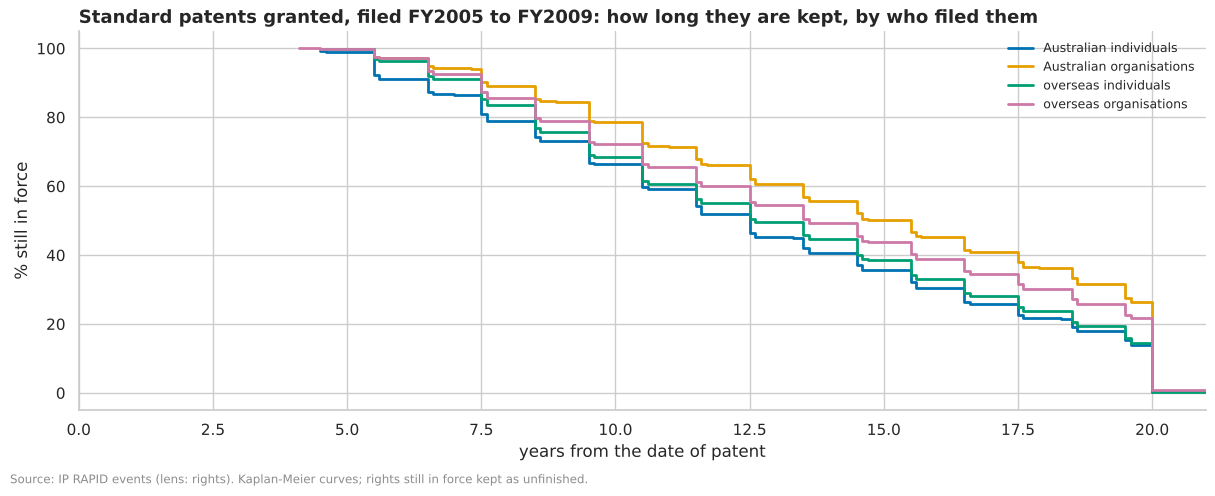

In [10]:
def lifetimes(where, group, periods):
    # Kaplan-Meier curves of years in force by group and period; returns the curves keyed 'group | period'
    case = "CASE " + " ".join(f"WHEN filing_fy BETWEEN {a} AND {b} THEN 'FY{a}-FY{b}'" for a, b in periods) + " END"
    c = rsql(f"""
        SELECT {group} AS grp, {case} AS period, round(years_in_force, 1) AS t,
               count(*) FILTER (NOT in_force) AS ended, count(*) FILTER (in_force) AS unfinished
        FROM {{lens/rights}}
        WHERE {where} AND years_in_force >= 0 AND in_force IS NOT NULL GROUP BY ALL
    """).dropna(subset=["grp", "period"])
    c["key"] = c.grp + " | " + c.period
    return uni.kaplan_meier(c, by="key")


def at_years(km, years):
    # the share in force at each of `years`, with its interval, as rows of group and period
    out = []
    for y in years:
        s = bi.survival_with_interval(km, y, by="key").reset_index()
        s[["group", "period"]] = s.key.str.split(" | ", regex=False, expand=True)
        out.append(s.assign(years=y))
    return pd.concat(out).set_index(["group", "years", "period"]).drop(columns="key").sort_index()


STD = "patent_type = 'standard' AND founding_australian IS NOT NULL AND founder_type IS NOT NULL"
km_std = lifetimes(STD, "@FILER", [(2005, 2009), (2000, 2004)])
std_life = at_years(km_std, [5, 10, 15])
fig, ax = plt.subplots(figsize=(12, 4.6))
for i, (key, d) in enumerate(km_std[km_std.key.str.endswith("FY2005-FY2009")].groupby("key")):
    ax.step(d.t, 100 * d.survival, where="post", lw=2, color=style.PALETTE[i], label=key.split(" | ")[0])
ax.set_xlabel("years from the date of patent")
ax.set_ylabel("% still in force")
ax.set_xlim(0, 21)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Standard patents granted, filed FY2005 to FY2009: how long they are kept, by who filed them")
style.source(fig, "IP RAPID events (lens: rights). Kaplan-Meier curves; rights still in force kept as unfinished.")
(100 * std_life[["in force", "low", "high"]]).round(1).join(std_life["at risk"]).unstack("period")

Fields: 35 ; agreement of the two periods' order (Spearman rho): 0.459
Range across fields, FY2005-FY2009: 59.4% to 81.2%


Fields with both (30 or more at risk at 10 years): 32; Australian organisations lower in 9; median gap 4.7 points (range -15.8 to 28.6)


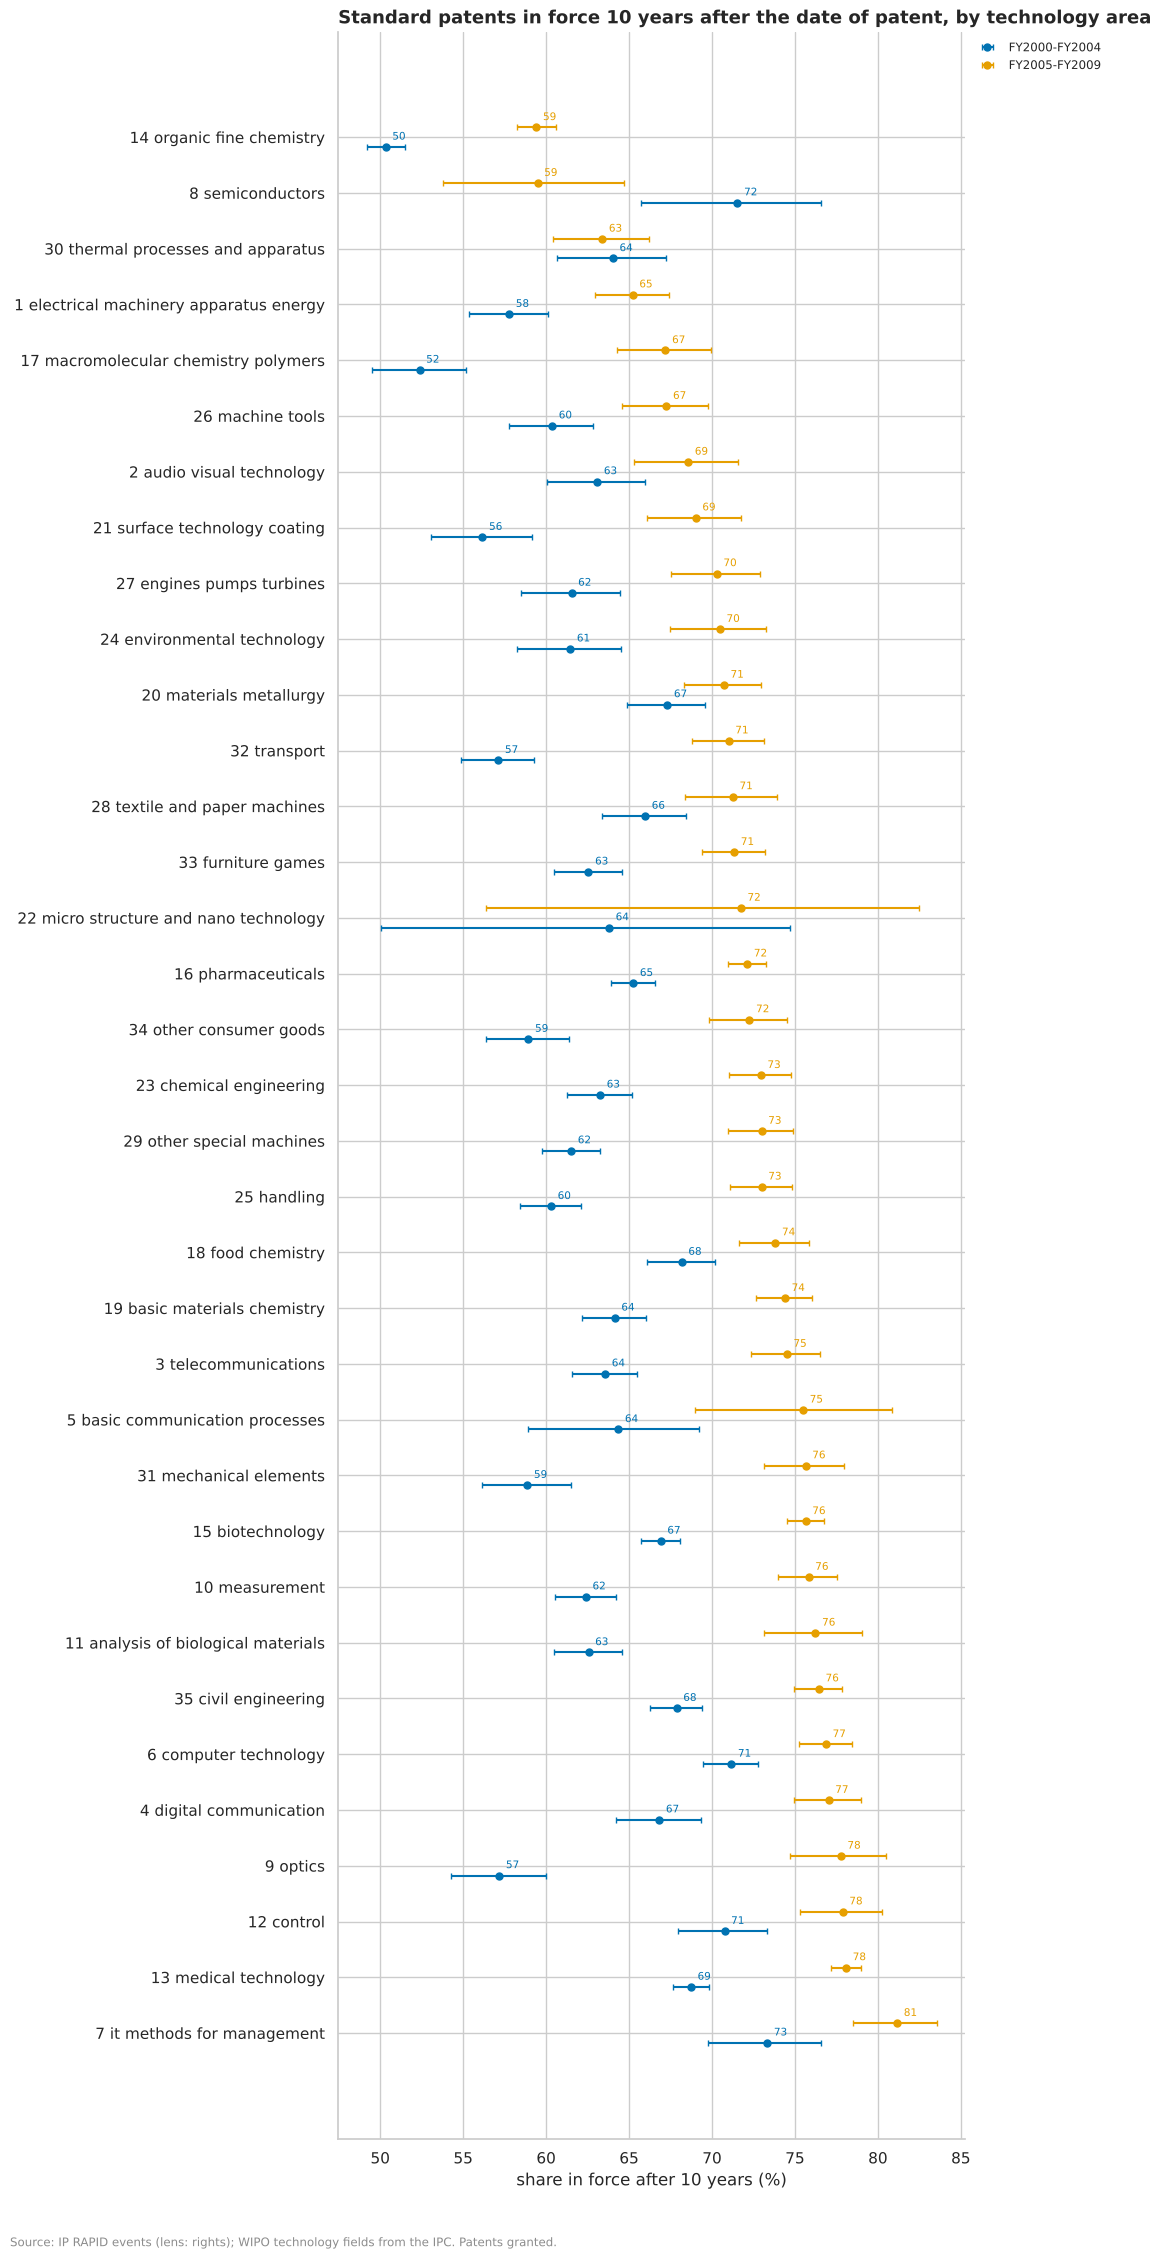

In [11]:
# By technology area (WIPO's 35 fields): the share in force after 10 years, for both periods, and whether the order of
# the fields holds from one period to the other
km_area = lifetimes("patent_type = 'standard' AND main_area IS NOT NULL", "main_area", [(2005, 2009), (2000, 2004)])
area10 = at_years(km_area, [10]).droplevel("years")
wide = area10["in force"].unstack("period")
order = wide.sort_values("FY2005-FY2009").index
plot = area10.reset_index().set_index("group").loc[order].rename(columns={"in force": "share"})
plot.index = plot.index.str.replace("_", " ")
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    fmt="{:.0f}",
    title="Standard patents in force 10 years after the date of patent, by technology area",
    xlabel="share in force after 10 years",
)
style.source(fig, "IP RAPID events (lens: rights); WIPO technology fields from the IPC. Patents granted.")
print(
    "Fields:",
    len(wide.dropna()),
    "; agreement of the two periods' order (Spearman rho):",
    round(wide.dropna().corr(method="spearman").iloc[0, 1], 3),
)
print(
    "Range across fields, FY2005-FY2009:",
    f"{100 * wide['FY2005-FY2009'].min():.1f}% to {100 * wide['FY2005-FY2009'].max():.1f}%",
)

# Does the origin gap hold within fields? Australian against overseas organisations, field by field (FY2005-FY2009)
km_af = lifetimes(
    STD + " AND founder_type = 'organisation' AND main_area IS NOT NULL",
    "main_area || ' / ' || CASE WHEN founding_australian THEN 'AU' ELSE 'overseas' END",
    [(2005, 2009)],
)
af = bi.survival_with_interval(km_af, 10, by="key").reset_index()
af[["area", "who"]] = af.key.str.split(" | ", regex=False).str[0].str.split(" / ", expand=True)
both = af.pivot(index="area", columns="who", values="in force").dropna()
gap = 100 * (both["AU"] - both["overseas"])
print(
    f"Fields with both (30 or more at risk at 10 years): {len(both)};",
    f"Australian organisations lower in {(gap < 0).sum()};",
    f"median gap {gap.median():.1f} points (range {gap.min():.1f} to {gap.max():.1f})",
)

In [12]:
# Trade marks: in force after 10 years (the first renewal), filed FY2010 to FY2015 against FY2003 to FY2009; designs:
# in force after 5 years (the one renewal under the Designs Act 2003), filed FY2010 to FY2019 against FY2005 to FY2009;
# by who filed them and, for Australian filers, by representation
TM = "ip_right_type = 'trade_mark' AND founding_australian IS NOT NULL AND founder_type IS NOT NULL"
DS = "ip_right_type = 'design' AND founding_australian IS NOT NULL AND founder_type IS NOT NULL"
tm_life = at_years(lifetimes(TM, "@FILER", [(2010, 2015), (2003, 2009)]), [10])
tm_rep = at_years(
    lifetimes(
        TM + " AND founding_australian AND representation IS NOT NULL",
        "'Australian, ' || representation",
        [(2010, 2015), (2003, 2009)],
    ),
    [10],
)
ds_life = at_years(lifetimes(DS, "@FILER", [(2010, 2019), (2005, 2009)]), [5])
ds_rep = at_years(
    lifetimes(
        DS + " AND founding_australian AND representation IS NOT NULL",
        "'Australian, ' || representation",
        [(2010, 2019), (2005, 2009)],
    ),
    [5],
)
for name, t in (
    ("Trade marks, after 10 years", pd.concat([tm_life, tm_rep])),
    ("Designs, after 5 years", pd.concat([ds_life, ds_rep])),
):
    print(name)
    display((100 * t[["in force", "low", "high"]]).round(1).join(t["at risk"]).droplevel("years").unstack("period"))

Trade marks, after 10 years


in force                         low                        high                     at risk              
period                   FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015
group                                                                                                                                   
Australian individuals            27.7            26          27.3          25.5          28.1          26.4       3.8e+04     3.405e+04
Australian organisations          44.6          45.9          44.4          45.6          44.9          46.2     1.213e+05     1.123e+05
Australian, attorney              52.1            52          51.7          51.6          52.4          52.3     7.571e+04     7.625e+04
Australian, other_agent           30.3          34.6          29.6          33.7          30.9          35.5      1.86e+04     1.158e+04
Australian, self                  30.2          28.6          29.9          28.3          30.6            29     6.495e+04     5.849e+04
overseas individuals              40.6            38          39.4          36.5          41.9          39.5         5,491         3,940
overseas organisations            56.3          56.3            56            56          56.6          56.6     9.976e+04     1.047e+05

Designs, after 5 years


in force                         low                        high                     at risk              
period                   FY2005-FY2009 FY2010-FY2019 FY2005-FY2009 FY2010-FY2019 FY2005-FY2009 FY2010-FY2019 FY2005-FY2009 FY2010-FY2019
group                                                                                                                                   
Australian individuals            27.1          28.3          25.6          27.2          28.6          29.5         3,433         5,732
Australian organisations          46.4          44.4          45.4          43.7          47.5          45.1         8,426       1.8e+04
Australian, attorney              50.8          47.2          49.6          46.4          51.9          47.9         7,024     1.599e+04
Australian, other_agent           24.9          22.2          23.4          20.6          26.5          23.7         2,865         2,647
Australian, self                  28.8          28.9          26.9          27.7          30.8          30.1         1,970         5,089
overseas individuals              36.9            40          33.8            38            40            42           917         2,151
overseas organisations            62.1          69.9          61.3          69.4          62.9          70.3     1.356e+04      3.59e+04

#### Observations
**B8 (observational). Australian organisations keep their standard patents longer than overseas organisations do;
individuals, Australian or not, keep them least.** Share of granted standard patents still in force (95% interval):
- **After 10 years:** Australian organisations 78.7% (77.5% to 79.9%) for FY2005 to FY2009 filings and 72.8% (71.5% to
  74.1%) for FY2000 to FY2004; overseas organisations 72.3% (71.9% to 72.6%) and 62.9% (62.5% to 63.3%); Australian
  individuals 66.4% and 55.3%; overseas individuals 68.6% and 55.4%.
- **After 15 years:** Australian organisations 50.3% and 42.4%; overseas organisations 43.9% and 36.8%.
- **Within technology:** in 32 fields with enough patents, Australian organisations keep a higher share to 10 years
  than overseas organisations in all but 9, by a median 4.7 points (from -15.8 to 28.6): the gap is not only a
  matter of which fields Australians patent in.
- **Third factors:** selection at grant (Australians' applications are granted less often, B6, so their granted
  patents may be the stronger ones), family reach (an Australian-only patent has one set of fees, B10), and firm size.
  Every cohort lengthened its patents' lives in the later period, in line with U36.

**B9 (descriptive). Technology areas differ in how long their patents are kept, but the order is only moderately
stable.** Share in force after 10 years, FY2005 to FY2009, from 59.4% to 81.2% across the 35 fields (chart above). The
fields' order agrees between the two periods with a Spearman rho of 0.459: a weak replication, so field differences in
lifetimes are kept as a lead only together with B8.

**B10 (observational). Trade marks and designs: overseas organisations renew most, Australian individuals least, and
Australians who file alone renew far less.**
- **Trade marks in force after 10 years** (filed FY2010 to FY2015; FY2003 to FY2009): overseas organisations 56.3%
  (56.3%), Australian organisations 45.9% (44.6%), overseas individuals 38.0% (40.6%), Australian individuals 26.0%
  (27.7%). Among Australian filers: with an attorney 52.0% (52.1%), through another agent 34.6% (30.3%), alone 28.6%
  (30.2%).
- **Designs in force after 5 years** (filed FY2010 to FY2019; FY2005 to FY2009): overseas organisations 69.9% (62.1%),
  Australian organisations 44.4% (46.4%), Australian individuals 28.3% (27.1%); Australians with an attorney 47.2%
  (50.8%), alone 28.9% (28.8%).
- Every interval is within about 1 point. The differences hold in both periods. **Third factors:** applicant type
  (individuals file alone most, B5) and the survival of the business behind a mark, which these data do not hold.

### 1.3 Family reach and citations, by origin, applicant type and technology

**From:** U93, U94. **Informs:** Q1. A patent's family reach (the offices it is filed in) is chosen and paid for by its
owner; the families citing it within five years are a sign of its influence. Citations are compared as **percentile
ranks within their technology field and year of filing** (50 is the typical patent of its field and year), because
they vary so much by field and age, and beside family reach, because a family filed in more offices is more often
cited. Standard patents filed FY2010 to FY2019, against FY2000 to FY2009.

In [13]:
reach = (
    rsql("""
    SELECT @PERIOD AS period, @FILER AS filer, count(*) AS patents, median(family_offices) AS "median offices",
           count(*) FILTER (family_offices = 1) AS only_au, count(*) FILTER (family_offices >= 5) AS five_plus,
           count(*) FILTER (family_granted_us) AS us
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND family_offices IS NOT NULL
      AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")
    .set_index(["filer", "period"])
    .sort_index()
)
for col, name in (
    ("only_au", "filed only in Australia (%)"),
    ("five_plus", "five or more offices (%)"),
    ("us", "granted in the US (%)"),
):
    lo, hi = bi.wilson(reach[col], reach.patents)
    reach[name] = 100 * reach[col] / reach.patents
    reach[name + " interval"] = [f"{100 * a:.1f} to {100 * b:.1f}" for a, b in zip(lo, hi, strict=True)]
reach.drop(columns=["only_au", "five_plus", "us"]).round(2).unstack("period").T

filer                                              Australian individuals Australian organisations overseas individuals overseas organisations
                                     period                                                                                                   
patents                              FY2000-FY2009                   7310                    15658                14796                 186575
                                     FY2010-FY2019                   5662                    18991                14353                 234524
median offices                       FY2000-FY2009                      1                        1                    5                      7
                                     FY2010-FY2019                      1                        2                    5                      6
filed only in Australia (%)          FY2000-FY2009                  87.31                    73.02                11.11                   7.34
                                     FY2010-FY2019                  59.91                    40.71                 8.66                   8.23
filed only in Australia (%) interval FY2000-FY2009           86.5 to 88.0             72.3 to 73.7         10.6 to 11.6             7.2 to 7.5
                                     FY2010-FY2019           58.6 to 61.2             40.0 to 41.4           8.2 to 9.1             8.1 to 8.3
five or more offices (%)             FY2000-FY2009                   4.21                    13.07                59.96                  72.35
                                     FY2010-FY2019                  10.28                     22.6                58.53                  69.58
five or more offices (%) interval    FY2000-FY2009             3.8 to 4.7             12.5 to 13.6         59.2 to 60.7           72.1 to 72.6
                                     FY2010-FY2019            9.5 to 11.1             22.0 to 23.2         57.7 to 59.3           69.4 to 69.8
granted in the US (%)                FY2000-FY2009                   5.98                    15.79                55.19                  61.93
                                     FY2010-FY2019                  18.77                     32.8                 59.1                  67.13
granted in the US (%) interval       FY2000-FY2009             5.5 to 6.5             15.2 to 16.4         54.4 to 56.0           61.7 to 62.2
                                     FY2010-FY2019           17.8 to 19.8             32.1 to 33.5         58.3 to 59.9           66.9 to 67.3

Mean citation percentile within field and year, all reach (50 = typical):


period,FY2000-FY2009,FY2010-FY2019
filer,,
Australian individuals,20.3,24.1
Australian organisations,25,32.2
overseas individuals,46.3,46
overseas organisations,53.6,52.3


patents               mean percentile              
period                                     FY2000-FY2009 FY2010-FY2019   FY2000-FY2009 FY2010-FY2019
reach             filer                                                                             
1 office          Australian individuals            6382          3391            17.1            14
                  Australian organisations         11433          7732              16          15.2
                  overseas individuals              1663          1243            15.7          13.1
                  overseas organisations           13732         19307            12.6          11.6
2 to 4 offices    Australian individuals             620          1688            39.4          36.2
                  Australian organisations          2179          6967              42          39.9
                  overseas individuals              4287          4709            46.1          44.7
                  overseas organisations           37921         52035            52.1          50.7
5 or more offices Australian individuals             308           582            47.7          48.3
                  Australian organisations          2046          4292            57.6          50.6
                  overseas individuals              8882          8401              52          51.6
                  overseas organisations          135107        163182            58.2          57.7

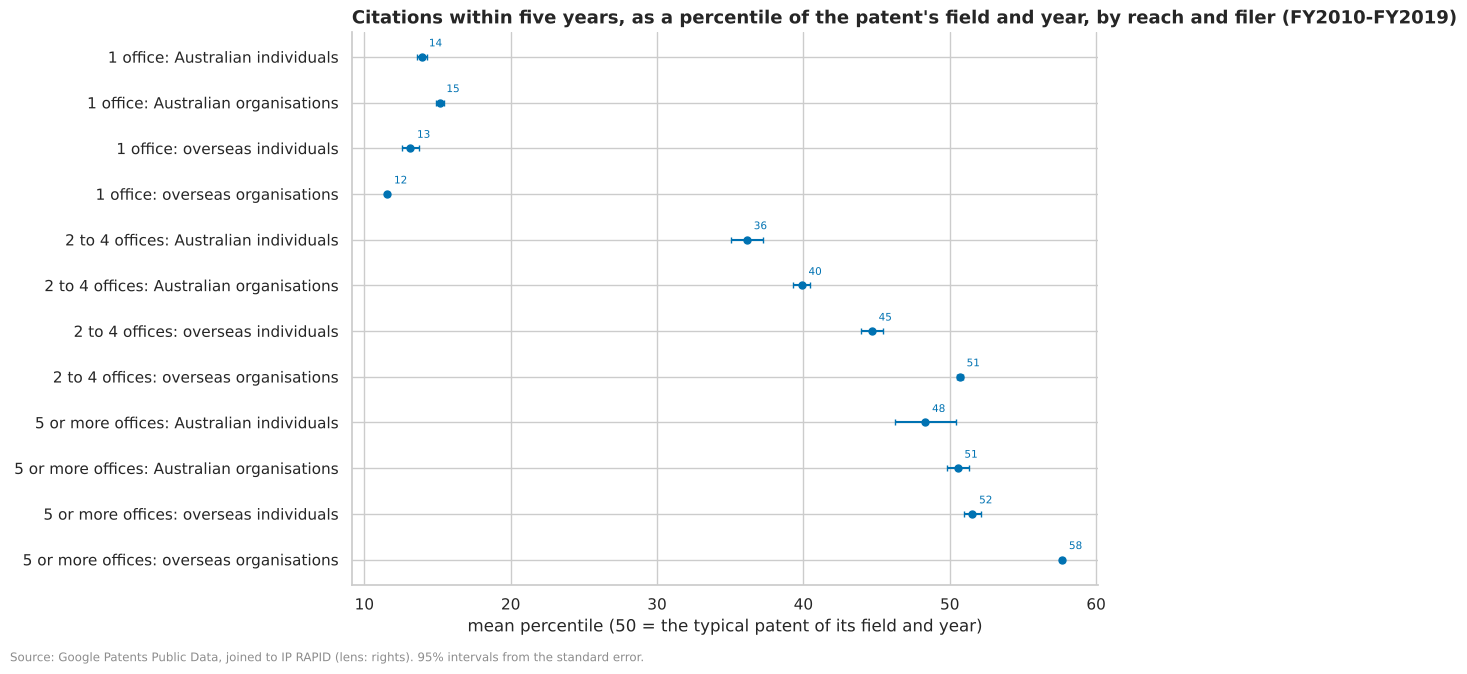

In [14]:
cites = rsql("""
    WITH c AS (
        SELECT @PERIOD AS period, @FILER AS filer, family_offices, main_area,
               100 * (percent_rank() OVER w + cume_dist() OVER w) / 2 AS pct
        FROM {lens/rights}
        WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND family_citations_5y IS NOT NULL
          AND main_area IS NOT NULL
        WINDOW w AS (PARTITION BY filing_fy, main_area ORDER BY family_citations_5y))
    SELECT period, filer,
           CASE WHEN family_offices = 1 THEN '1 office' WHEN family_offices < 5 THEN '2 to 4 offices'
                ELSE '5 or more offices' END AS reach,
           count(*) AS patents, avg(pct) AS "mean percentile", stddev(pct) / sqrt(count(*)) AS se
    FROM c WHERE filer IS NOT NULL GROUP BY ALL
""")
allr = cites.assign(w=cites.patents * cites["mean percentile"]).groupby(["filer", "period"])[["w", "patents"]].sum()
allr["mean percentile"] = allr.w / allr.patents
print("Mean citation percentile within field and year, all reach (50 = typical):")
display(allr["mean percentile"].round(1).unstack("period"))
cites["low"] = cites["mean percentile"] - 1.96 * cites.se
cites["high"] = cites["mean percentile"] + 1.96 * cites.se
plot = cites[cites.period == "FY2010-FY2019"].sort_values(["reach", "filer"])
plot.index = plot.reach + ": " + plot.filer
fig = bi.dot_chart(
    plot,
    value="mean percentile",
    low="low",
    high="high",
    percent=False,
    fmt="{:.0f}",
    title="Citations within five years, as a percentile of the patent's field and year, "
    "by reach and filer (FY2010-FY2019)",
    xlabel="mean percentile (50 = the typical patent of its field and year)",
)
style.source(
    fig, "Google Patents Public Data, joined to IP RAPID (lens: rights). 95% intervals from the standard error."
)
cites.set_index(["reach", "filer", "period"])[["patents", "mean percentile"]].round(1).unstack("period")

#### Observations
**B11 (observational). Australian organisations' patents reach fewer countries than overseas filers', though the gap
has narrowed.** Standard patents, FY2010 to FY2019 (FY2000 to FY2009):
- **Filed only in Australia:** Australian organisations 40.71% (73.02%), Australian individuals 59.91% (87.31%),
  overseas organisations 8.23% (7.34%), each within about a point.
- **Five or more offices:** Australian organisations 22.6% (13.07%), overseas organisations 69.58% (72.35%).
- **Granted in the United States:** Australian organisations 32.8% (15.79%), overseas organisations 67.13% (61.93%).
- The gap holds in both decades, but Australian organisations' share filed only here fell from 73.02% to 40.71%. Whether that
  is a change in practice or in how fully Google Patents holds older Australian-only families is not shown here (a
  lead).

**B12 (observational). Australians' patents are cited less within their field and year, and most of the gap goes
with family reach.** Mean percentile of citations within five years, within field and year (50 = typical):
- **All reach:** overseas organisations 52.3 (FY2010 to FY2019) and 53.6 (FY2000 to FY2009); Australian organisations
  32.2 and 25.0; Australian individuals 24.1 and 20.3.
- **Within the same reach** the gap shrinks or reverses: among patents filed in one office, Australian organisations
  15.2 against overseas organisations' 11.6 (16.0 against 12.6); in five or more offices, 50.6 against 57.7 (57.6
  against 58.2). Among those filed in 2 to 4 offices, 39.9 against 50.7 (42.0 against 52.1).
- So reach is the main third factor: a narrow family is seldom cited wherever it comes from. Since owners choose and
  pay for reach, citations and reach are two readings of the same expected value, not independent evidence of it.

### 1.4 Expedited examination and years in force

**From:** U34, U36, and the commissioned study IP Australia cites (ADR 0024), which found expedited patents kept
longer. **Informs:** Q1, Q4. Does asking for speed go with keeping the right longer? Standard patents whose examination
was requested, filed FY2010 to FY2016 against FY2003 to FY2009; trade marks without a priority claim (whose recorded
expedites are applicants' requests, U103), filed FY2010 to FY2015 against FY2003 to FY2009, before November 2018's
change of records.

In [15]:
EXP = "CASE WHEN exam_expedited THEN 'expedited' ELSE 'not expedited' END"
share = rsql("""
    SELECT coalesce(patent_type, ip_right_type) AS t,
           CASE WHEN filing_fy >= 2010 THEN 'FY2010 on' ELSE 'FY2003-FY2009' END AS period, @FILER AS filer,
           count(*) AS n, count(*) FILTER (exam_expedited) AS expedited,
           count(*) FILTER (registered_date IS NOT NULL) AS granted,
           count(*) FILTER (exam_expedited AND registered_date IS NOT NULL) AS expedited_granted
    FROM {lens/rights}
    WHERE (patent_type = 'standard' AND filing_fy BETWEEN 2003 AND 2016 AND exam_requested_date IS NOT NULL
           OR ip_right_type = 'trade_mark' AND filing_fy BETWEEN 2003 AND 2015 AND coalesce(priority_claims, 0) = 0)
      AND exam_expedited IS NOT NULL AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")
s = share.groupby(["t", "period", "filer"])[["expedited", "n", "granted", "expedited_granted"]].sum()
s["expedited (%)"] = 100 * s.expedited / s.n
s["granted if expedited (%)"] = 100 * s.expedited_granted / s.expedited
s["granted if not (%)"] = 100 * (s.granted - s.expedited_granted) / (s.n - s.expedited)
s[["n", "expedited", "expedited (%)", "granted if expedited (%)", "granted if not (%)"]].round(2)

n  expedited  expedited (%)  granted if expedited (%)  granted if not (%)
t          period        filer                                                                                                   
standard   FY2003-FY2009 Australian individuals      3703        728          19.66                     71.29               48.27
                         Australian organisations   10251        914           8.92                     79.87               63.46
                         overseas individuals        9399        179            1.9                     79.33               62.94
                         overseas organisations    118785        999           0.84                     88.89               70.77
           FY2010 on     Australian individuals      2844        566           19.9                     66.78                  45
                         Australian organisations   10972       1851          16.87                     69.75                  57
                         overseas individuals        8549        704           8.23                     81.68                66.2
                         overseas organisations    143018      11448              8                     82.53               76.18
trade_mark FY2003-FY2009 Australian individuals     71437       4981           6.97                     63.54               53.17
                         Australian organisations  185536      16557           8.92                     73.32               65.31
                         overseas individuals        4735        107           2.26                      75.7               79.45
                         overseas organisations     72848       1531            2.1                     82.56               86.41
           FY2010 on     Australian individuals     67523       2841           4.21                     64.59               50.59
                         Australian organisations  177260      13650            7.7                     74.37               63.02
                         overseas individuals        3871         72           1.86                     69.44               75.18
                         overseas organisations     74267       1532           2.06                     83.22               85.05

In [16]:
km_exp = lifetimes(
    STD + " AND exam_requested_date IS NOT NULL AND exam_expedited IS NOT NULL",
    EXP + " || ', ' || @FILER",
    [(2010, 2016), (2003, 2009)],
)
std_exp = at_years(km_exp, [5, 10])
km_exp_all = lifetimes(
    "patent_type = 'standard' AND exam_requested_date IS NOT NULL AND exam_expedited IS NOT NULL",
    EXP,
    [(2010, 2016), (2003, 2009)],
)
std_exp_all = at_years(km_exp_all, [5, 10])
km_tm = lifetimes(
    TM + " AND coalesce(priority_claims, 0) = 0 AND exam_expedited IS NOT NULL",
    EXP + " || ', ' || @FILER",
    [(2010, 2015), (2003, 2009)],
)
tm_exp = at_years(km_tm, [10])
for name, t in (
    ("Standard patents, all filers", std_exp_all),
    ("Standard patents, by filer", std_exp),
    ("Trade marks without a priority claim, by filer", tm_exp),
):
    print(name)
    display((100 * t[["in force", "low", "high"]]).round(1).join(t["at risk"]).unstack("period"))

Standard patents, all filers


in force                         low                        high                     at risk              
period              FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016
group         years                                                                                                                
expedited     5              99.3          97.3          98.8            97          99.5          97.6         2,265     1.138e+04
              10             68.7          76.8          66.8            76          70.6          77.5         1,572         8,979
not expedited 5               100          98.1          99.9            98           100          98.2     9.651e+04     1.095e+05
              10             71.3          68.7          71.1          68.5          71.6            69     6.887e+04     7.675e+04

Standard patents, by filer


in force                         low                        high                     at risk              
period                                        FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016
group                                   years                                                                                                                
expedited, Australian individuals       5              98.1          88.4          96.4          84.7            99          91.2           510           337
                                        10             54.1          64.6          49.8          59.5          58.3          69.1           308           245
expedited, Australian organisations     5              99.7          96.4          98.9          95.3          99.9          97.3           730         1,250
                                        10             69.9          80.2          66.4          77.9          73.1          82.2           512         1,044
expedited, overseas individuals         5              97.2          95.3          92.7          93.2          98.9          96.8           141           549
                                        10             55.6          66.8          47.1          62.8          63.4          70.5            80           390
expedited, overseas organisations       5              99.9          97.9          99.2          97.6           100          98.2           888         9,264
                                        10             78.5          77.4          75.6          76.6          81.1          78.3           698         7,316
not expedited, Australian individuals   5              99.8          97.6          99.4          96.4          99.9          98.3         1,434         1,002
                                        10             68.8          70.7          66.3          67.8          71.1          73.4           989           735
not expedited, Australian organisations 5               100          98.8          99.9          98.5           100          99.1         5,925         5,138
                                        10             79.1            77            78          75.8          80.1          78.1         4,686         4,002
not expedited, overseas individuals     5              99.9          98.1          99.8          97.7           100          98.5         5,803         5,100
                                        10             67.1          65.8          65.9          64.5          68.3          67.1         3,896         3,423
not expedited, overseas organisations   5               100          98.1           100            98           100          98.2     8.334e+04     9.831e+04
                                        10             71.1          68.4          70.8          68.2          71.4          68.7     5.929e+04     6.861e+04

Trade marks without a priority claim, by filer


in force                         low                        high                     at risk              
period                                        FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015
group                                   years                                                                                                                
expedited, Australian individuals       10             30.1          28.8          28.5          26.7          31.7          30.9         3,118         1,797
expedited, Australian organisations     10             45.6          49.8          44.7          48.8          46.5          50.8     1.194e+04         9,986
expedited, overseas individuals         10             39.5            32          28.9          19.7          49.9            45            79            49
expedited, overseas organisations       10             57.7          59.2          54.9          56.5          60.3          61.9         1,251         1,255
not expedited, Australian individuals   10             27.5          25.8            27          25.3            28          26.3     3.484e+04      3.22e+04
not expedited, Australian organisations 10             44.5          45.5          44.2          45.2          44.8          45.8      1.09e+05     1.018e+05
not expedited, overseas individuals     10             42.9          40.1          41.3          38.3          44.5          41.8         3,500         2,720
not expedited, overseas organisations   10             60.6          60.3          60.2          59.9            61          60.6     5.972e+04     5.972e+04

#### Observations
**B13 (observational). Expedited standard patents last longer in the later period but not the earlier one; the
pooled link is a composition effect, and it holds only for overseas organisations.**
- **Pooled:** expedited patents in force after 10 years 76.8% (76.0% to 77.5%) against 68.7% (68.5% to 69.0%) for
  FY2010 to FY2016 filings, but 68.7% against 71.3% for FY2003 to FY2009: the association does not replicate.
- **By filer:** overseas organisations 77.4% against 68.4% (FY2010 to FY2016) and 78.5% against 71.1% (FY2003 to
  FY2009), higher in both; Australian organisations 80.2% against 77.0%, then 69.9% against 79.1%;
  Australian individuals 64.6% against 70.7%, then 54.1% against 68.8% (expedited patents kept less).
- **Who asks changed:** 0.84% of overseas organisations' examined patents were expedited in FY2003 to FY2009 and 8.0%
  from FY2010; Australian individuals 19.66% and 19.9%. As overseas organisations, who keep patents longer, became most
  of the expedited, the pooled figure rose: Simpson's paradox.
- **Expedited applications are granted more often** in every group: for example Australian organisations 69.75%
  against 57.0%, overseas organisations 82.53% against 76.18% (FY2010 on).
- IP Australia's commissioned study found expedited patents kept longer (ADR 0024); here that holds for overseas
  organisations only. Third factors: the filer (above), the urgency behind a request (a product on the market, a
  dispute), which the data do not record.

**B14 (descriptive). Trade marks: expediting goes with renewal only slightly, and not for overseas organisations: not
a lead.** Marks without a priority claim, in force after 10 years (FY2010 to FY2015; FY2003 to FY2009), expedited
against not: Australian organisations 49.8% against 45.5% (45.6% against 44.5%), Australian individuals 28.8% against
25.8% (30.1% against 27.5%), overseas organisations 59.2% against 60.3% (57.7% against 60.6%). Differences of 1 to 4
points for Australians, below the size this stage looks for.

### 1.5 The route into Australia, and where inventions are made against who files them

**From:** U90, U96. **Informs:** Q1, Q2. Standard patents filed FY2010 to FY2019 against FY2000 to FY2009.

filing_route                            pct  convention  australian_priority  divisional  direct
filer                    period                                                                 
Australian individuals   FY2000-FY2009 27.5           1                 39.7         6.7      25
                         FY2010-FY2019 29.2         1.8                   31        10.2    27.8
Australian organisations FY2000-FY2009 51.4         1.7                   28        11.6     7.3
                         FY2010-FY2019 45.3           2                   21        22.4     9.2
overseas individuals     FY2000-FY2009   79        10.7                  0.3         5.1       5
                         FY2010-FY2019 79.9         7.8                  0.2         9.7     2.5
overseas organisations   FY2000-FY2009 78.2        13.4                  0.5         7.1     0.8
                         FY2010-FY2019 74.7         8.9                  0.1        15.6     0.6

Screen strength of filer type x route: {'strength': 0.243, 'strength (replication)': 0.29}


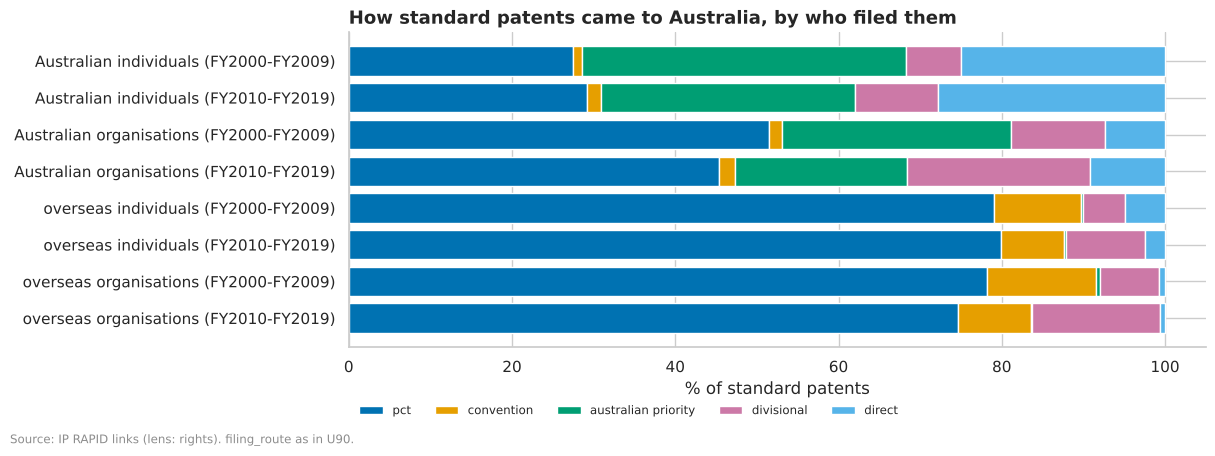

In [17]:
route = rsql("""
    SELECT @PERIOD AS period, @FILER AS filer, filing_route, count(*) AS n
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND filing_route IS NOT NULL
      AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")
shares = route.pivot_table(index=["filer", "period"], columns="filing_route", values="n", aggfunc="sum").fillna(0)
shares = 100 * shares.div(shares.sum(axis=1), axis=0)
order = ["pct", "convention", "australian_priority", "divisional", "direct"]
shares = shares[[c for c in order if c in shares] + [c for c in shares if c not in order]]
fig, ax = plt.subplots(figsize=(12, 4.2))
left = np.zeros(len(shares))
labels = [f"{f} ({p})" for f, p in shares.index]
for i, c in enumerate(shares.columns):
    ax.barh(labels, shares[c], left=left, color=style.PALETTE[i], label=c.replace("_", " "))
    left += shares[c].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("% of standard patents")
ax.legend(frameon=False, fontsize=8.5, ncol=5, loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("How standard patents came to Australia, by who filed them")
style.source(fig, "IP RAPID links (lens: rights). filing_route as in U90.")
display(shares.round(1))
s = rights_screen["standard"]["verdicts"].set_index(["variable 1", "variable 2"])
print(
    "Screen strength of filer type x route:",
    s.loc[("applicant_type", "filing_route"), ["strength", "strength (replication)"]].round(3).to_dict(),
)

In [18]:
made = (
    rsql("""
    SELECT @PERIOD AS period, founding_australian AS filed_from_au, invented_in_australia AS made_in_au, count(*) AS n
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND founding_australian IS NOT NULL
      AND invented_in_australia IS NOT NULL
    GROUP BY ALL
""")
    .set_index(["period", "filed_from_au", "made_in_au"])
    .n
)
rows = {}
for p in ("FY2000-FY2009", "FY2010-FY2019"):
    m = made.loc[p]
    here = m.xs(True, level="made_in_au")
    rows[p] = {
        "inventions made in Australia (an inventor here)": int(here.sum()),
        "... filed from overseas": int(here.loc[False]),
        "... share filed from overseas (%)": 100 * here.loc[False] / here.sum(),
        "filed from Australia, no inventor here": int(m.loc[(True, False)]),
        "filed from Australia: share made here (%)": 100 * m.loc[(True, True)] / m.loc[True].sum(),
    }
    lo, hi = bi.wilson(np.array([here.loc[False]]), np.array([here.sum()]))
    rows[p]["... interval (%)"] = f"{100 * lo[0]:.2f} to {100 * hi[0]:.2f}"
pd.DataFrame(rows).T.round(2)

,inventions made in Australia (an inventor here),... filed from overseas,... share filed from overseas (%),"filed from Australia, no inventor here",filed from Australia: share made here (%),... interval (%)
FY2000-FY2009,6142,1184,19.28,509,90.69,18.31 to 20.28
FY2010-FY2019,16193,2349,14.51,771,94.72,13.97 to 15.06


#### Observations
**B15 (descriptive). Each kind of filer has its own route into Australia, and divisionals doubled.** Standard patents,
FY2010 to FY2019 (FY2000 to FY2009):
- **Overseas organisations:** the PCT 74.7% (78.2%), a priority abroad 8.9% (13.4%), divisionals 15.6% (7.1%).
- **Australian organisations:** the PCT 45.3% (51.4%), claiming an Australian application 21.0% (28.0%), divisionals
  22.4% (11.6%), direct 9.2% (7.3%).
- **Australian individuals:** claiming an Australian application 31.0% (39.7%), the PCT 29.2% (27.5%), direct 27.8%
  (25.0%).
- The screen's strength of applicant type × route: 0.243 and 0.29. The rise of divisionals among both Australian and
  overseas organisations is a lead for Stage 3 (a divisional keeps an application pending longer).

**B16 (descriptive). About one patent in seven made in Australia is filed by an overseas applicant.** Of the standard
patents with an inventor in Australia, 14.51% were filed from overseas in FY2010 to FY2019 (2,349 of 16,193; interval
13.97% to 15.06%) and 19.28% in FY2000 to FY2009 (1,184 of 6,142). Patents filed from Australia have an inventor here
94.72% and 90.69% of the time (771 and 509 without one). These count patents whose inventors' countries are known
(U95); Australian inventions filed only abroad are not in IP RAPID at all (the review's F07).

### 1.6 Women among inventors, by field and filer (the gender analysis)

**From:** U97, U98, U107. **Informs:** Q2. Estimated from first names (WIPO's World Gender-Name Dictionary), so these
are expected counts for groups, never anyone's recorded gender, and read only for inventors in Australia, the one
country whose estimates WIPO's published shares confirm (U97). Intervals come from a bootstrap that resamples whole
patents.

**Standard patents** (Google Patents' inventors whose country is Australia, as U98): by who filed and by technology,
filed FY2010 to FY2019 against FY2000 to FY2009. **Provisional applications** (IP Australia's register, ADR 0029):
by who filed and by the filer's state, FY2013 to FY2022 against FY2003 to FY2012, with each year's coverage shown
(U106; OQ17 asks why fewer name inventors since FY2024).

Patents: 22,335; inventor places in Australia: 44,251; with an estimate: 93.38%


ratio                         low                        high                        rows                       total  \
period                   FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009   
filer                                                                                                                                                    
Australian individuals           11.55         11.21          9.69           9.9         13.47         12.63         1,010         2,517         1,249   
Australian organisations         15.85         12.17         14.99         11.78         16.74         12.62         3,948     1.133e+04         8,175   
overseas individuals              5.56         10.16             0          0.01         16.81         23.84            18            23            18   
overseas organisations            9.83         10.57          8.44          9.46         11.29         11.51         1,166         2,326         1,864   

                                        
period                   FY2010-FY2019  
filer                                   
Australian individuals           3,087  
Australian organisations     2.294e+04  
overseas individuals                22  
overseas organisations           3,970

Fields in both periods: 12 ; agreement of their order (Spearman rho): 0.86


period,FY2000-FY2009,FY2010-FY2019
main_area,,
35_civil_engineering,4.3,4.2
32_transport,4.1,5.2
29_other_special_machines,9.6,5.7
10_measurement,5.8,7.2
20_materials_metallurgy,12.2,11.2
6_computer_technology,15.3,11.3
13_medical_technology,9.6,12.1
33_furniture_games,12.2,12.7
28_textile_and_paper_machines,39.7,15.9


FY2010-FY2019 range: 4.2% (35_civil_engineering) to 26.9% (15_biotechnology)


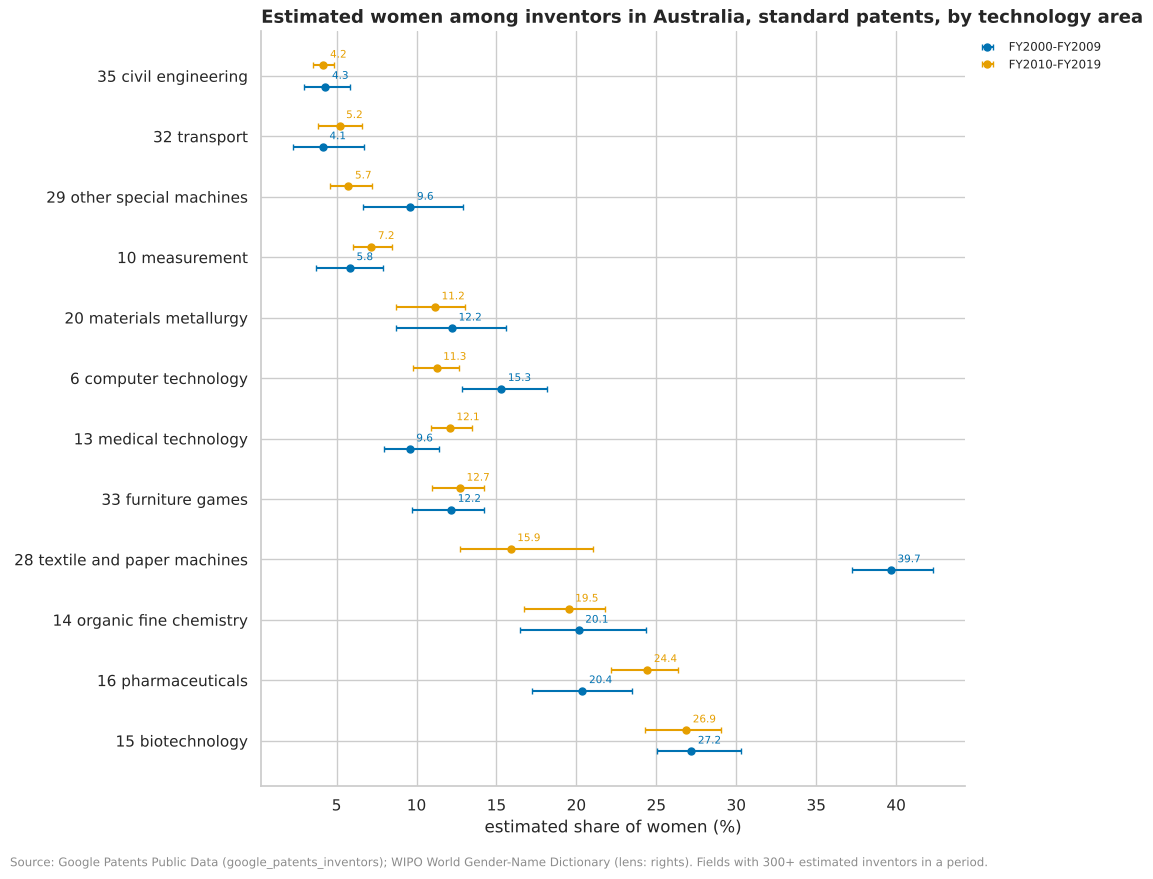

In [19]:
inv = rsql(
    """
    SELECT r.application_number, @PERIOD AS period, @FILER AS filer, r.main_area,
           sum(i.p_female) AS women, count(i.p_female) AS estimated, count(*) AS places
    FROM {lens/rights} r JOIN {google_patents_inventors/inventors} i USING (family_id)
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2000 AND 2019 AND i.country_code = 'AU'
      AND r.founding_australian IS NOT NULL AND r.founder_type IS NOT NULL
    GROUP BY ALL
""",
    max_rows=None,
)
print(
    f"Patents: {len(inv):,}; inventor places in Australia: {inv.places.sum():,};",
    f"with an estimate: {100 * inv.estimated.sum() / inv.places.sum():.2f}%",
)
by_filer = bi.ratio_by(inv, ["filer", "period"], "women", "estimated")
display((100 * by_filer[["ratio", "low", "high"]]).round(2).join(by_filer[["rows", "total"]]).unstack("period"))
by_area = bi.ratio_by(inv, ["main_area", "period"], "women", "estimated")
by_area = by_area[by_area.total >= 300]
wide = by_area.ratio.unstack("period").dropna()
order = wide.sort_values("FY2010-FY2019").index
plot = by_area.reset_index().set_index("main_area").loc[order].rename(columns={"ratio": "share"})
plot.index = plot.index.str.replace("_", " ")
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    title="Estimated women among inventors in Australia, standard patents, by technology area",
    xlabel="estimated share of women",
)
style.source(
    fig,
    "Google Patents Public Data (google_patents_inventors); WIPO World Gender-Name Dictionary "
    "(lens: rights). Fields with 300+ estimated inventors in a period.",
)
print(
    "Fields in both periods:",
    len(wide),
    "; agreement of their order (Spearman rho):",
    round(wide.corr(method="spearman").iloc[0, 1], 3),
)
display((100 * wide).round(1).sort_values("FY2010-FY2019"))
late = wide["FY2010-FY2019"]
print("FY2010-FY2019 range:", f"{100 * late.min():.1f}% ({late.idxmin()}) to {100 * late.max():.1f}% ({late.idxmax()})")

ratio                         low                        high                        rows                       total  \
period                   FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012   
filer                                                                                                                                                    
Australian individuals           18.89         16.14         18.54          15.7          19.2         16.51     3.274e+04     1.888e+04      3.62e+04   
Australian organisations         25.52         21.19          25.2         20.88         25.82          21.5     3.196e+04     2.892e+04     4.035e+04   
overseas individuals              5.78          16.6          3.95         14.18          7.93         19.21           459           604           492   
overseas organisations            6.05          6.66          5.01          5.64          7.13          7.78         1,691         1,594         2,315   

                                        
period                   FY2013-FY2022  
filer                                   
Australian individuals       2.164e+04  
Australian organisations      4.23e+04  
overseas individuals               985  
overseas organisations           2,371

ratio                         low                        high                       total              
period FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022
state                                                                                                                 
act            27.03         25.59         25.81         23.89         28.37         27.19         2,590         1,950
nsw            19.56         17.92         19.17         17.51         19.92         18.35     2.754e+04     2.386e+04
nt             28.11         13.92         23.55           8.8         33.52         20.84           175           136
qld            21.39         19.59         20.92         19.04         21.87         20.14       1.3e+04       1.1e+04
sa             32.23         21.92         31.35         20.88         33.03          22.8         4,390         3,324
tas            23.32         22.47         21.16         19.93         25.28         25.38           922           532
vic            25.77         21.31         25.29         20.81         26.18         21.84     1.959e+04      1.54e+04
wa             18.49         17.83         17.75          17.2         19.15         18.57         8,341         7,741

States with 500+ estimated inventors in both periods: 7 ; agreement of their order (Spearman rho): 0.821


with inventors (%)                                                                                   women (%)                           \
filer     Australian individuals Australian organisations overseas individuals overseas organisations Australian individuals Australian organisations   
filing_fy                                                                                                                                               
2003                        98.8                    98.21                  100                  98.42                  14.71                    24.33   
2008                       99.94                    99.94                  100                    100                  20.52                    27.35   
2012                       99.84                    99.96                  100                    100                  23.54                    27.07   
2013                       99.95                      100                  100                    100                  18.58                    22.28   
2014                         100                      100                  100                    100                  15.39                    18.47   
2018                         100                      100                  100                    100                  16.49                    21.32   
2022                       99.64                       99                98.78                  99.44                  17.24                     23.4   
2023                       99.58                    99.84                  100                    100                  17.33                    24.87   
2024                       93.49                    70.13                99.07                  80.51                  14.77                    19.94   
2025                       93.65                    63.91                94.74                  78.82                  15.51                    19.83   
2026                       95.86                    71.03                95.45                  74.15                  13.69                    15.13   

                                                       
filer     overseas individuals overseas organisations  
filing_fy                                              
2003                      7.44                   9.49  
2008                       2.1                    4.8  
2012                      3.63                   2.22  
2013                     10.08                   3.35  
2014                      5.33                   6.46  
2018                     19.25                   6.19  
2022                     22.51                   5.56  
2023                     27.67                   9.35  
2024                      17.4                    8.9  
2025                      26.2                  12.39  
2026                     22.98                     14

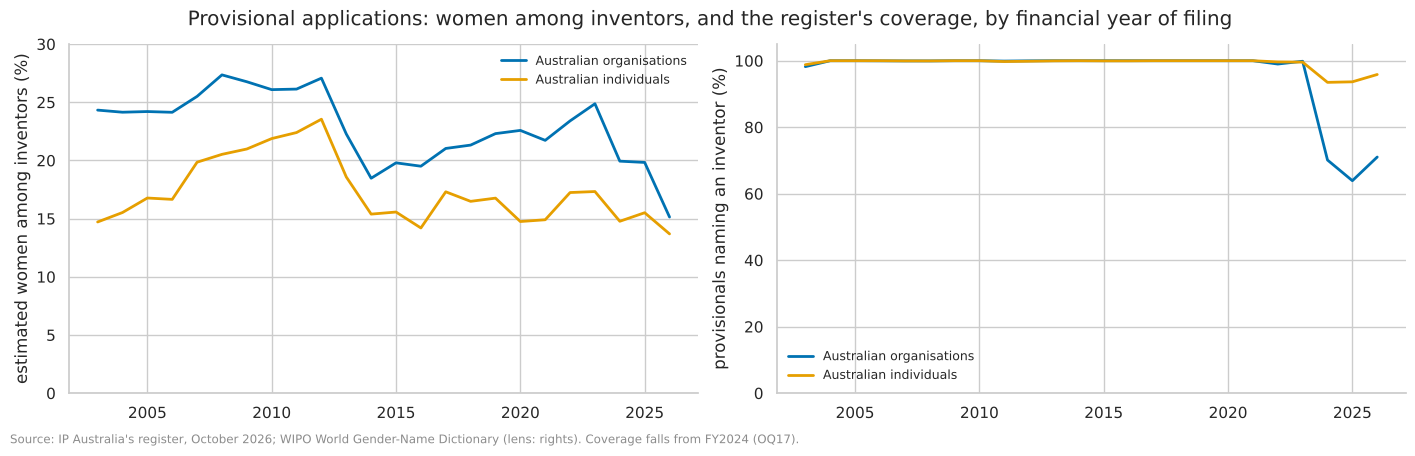

In [20]:
prov = rsql(
    """
    SELECT application_number, filing_fy,
           CASE WHEN filing_fy BETWEEN 2013 AND 2022 THEN 'FY2013-FY2022' WHEN filing_fy BETWEEN 2003 AND 2012
                THEN 'FY2003-FY2012' END AS period,
           @FILER AS filer, CASE WHEN founding_australian THEN founder_state END AS state,
           register_inventors AS named, register_inventors_women_expected AS women,
           register_inventors - register_inventors_gender_unknown AS estimated
    FROM {lens/rights}
    WHERE patent_type = 'provisional' AND filing_fy BETWEEN 2003 AND 2026 AND founding_australian IS NOT NULL
      AND founder_type IS NOT NULL
""",
    max_rows=None,
)
yearly = (
    prov.groupby(["filing_fy", "filer"])
    .apply(
        lambda d: pd.Series(
            {
                "with inventors (%)": 100 * (d.named > 0).mean(),
                "women (%)": 100 * d.women.sum() / max(d.estimated.sum(), 1),
            }
        ),
        include_groups=False,
    )
    .unstack("filer")
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for f in ("Australian organisations", "Australian individuals"):
    axes[0].plot(yearly.index, yearly[("women (%)", f)], lw=2, label=f)
    axes[1].plot(yearly.index, yearly[("with inventors (%)", f)], lw=2, label=f)
axes[0].set_ylabel("estimated women among inventors (%)")
axes[0].set_ylim(0, 30)
axes[1].set_ylabel("provisionals naming an inventor (%)")
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
fig.suptitle(
    "Provisional applications: women among inventors, and the register's coverage, by financial year of filing"
)
style.source(
    fig,
    "IP Australia's register, October 2026; WIPO World Gender-Name Dictionary (lens: rights). "
    "Coverage falls from FY2024 (OQ17).",
)
pv = prov.dropna(subset=["period"])
by_pf = bi.ratio_by(pv, ["filer", "period"], "women", "estimated")
display((100 * by_pf[["ratio", "low", "high"]]).round(2).join(by_pf[["rows", "total"]]).unstack("period"))
by_st = bi.ratio_by(pv[pv.state.notna()], ["state", "period"], "women", "estimated")
display((100 * by_st[["ratio", "low", "high"]]).round(2).join(by_st["total"]).unstack("period"))
st = by_st[by_st.total >= 500].ratio.unstack("period").dropna()
print(
    "States with 500+ estimated inventors in both periods:",
    len(st),
    "; agreement of their order (Spearman rho):",
    round(st.corr(method="spearman").iloc[0, 1], 3),
)
yearly.loc[[2003, 2008, 2012, 2013, 2014, 2018, 2022, 2023, 2024, 2025, 2026]].round(2)

#### Observations
**B17 (observational). Women among inventors in Australia: the field matters more than the filer, and the order of
fields holds.** Standard patents, inventors in Australia (44,251 inventor places on 22,335 patents, 93.38% with an
estimate):
- **By field,** FY2010 to FY2019 (FY2000 to FY2009): from 4.2% in civil engineering (4.3%) and 5.2% in transport
  (4.1%) to 24.4% in pharmaceuticals (20.4%) and 26.9% in biotechnology (27.2%). The order of the 12 fields with
  enough inventors agrees between the decades with a Spearman rho of 0.86.
- **By filer:** Australian organisations 12.17% (11.78% to 12.62%) and 15.85% (14.99% to 16.74%); Australian
  individuals 11.21% (9.9% to 12.63%) and 11.55% (9.69% to 13.47%); overseas organisations 10.57% and 9.83%.
  Organisations' and individuals' intervals overlap in FY2010 to FY2019, so the filer gap does not replicate for
  standard patents.
- Expected counts from names, read for inventors in Australia only (U97). Third factor: the field (organisations
  file more in biotechnology and pharmaceuticals, individuals in transport and civil engineering, B4).

**B18 (observational). Provisional applications: organisations' inventors include more women than individuals', in
both decades, and the states' order holds.**
- **By filer,** FY2013 to FY2022 (FY2003 to FY2012): Australian organisations 21.19% (20.88% to 21.5%) and 25.52%;
  Australian individuals 16.14% (15.7% to 16.51%) and 18.89% (18.54% to 19.2%). Overseas
  organisations 6.66% and 6.05%.
- **By state:** the ACT highest in the later decade (25.59%; 27.03% before), Western Australia and New South Wales
  lowest (17.83% and 17.92%; 18.49% and 19.56%); South Australia fell from 32.23% to 21.92%. The seven states with 500
  or more estimated inventors keep their order with a Spearman rho of 0.821.
- **Coverage:** in the years shown from FY2003 to FY2023, 98.21% to 100% of provisionals name an inventor in every
  filer group, but
  Australian organisations' only 70.13% (FY2024), 63.91% (FY2025) and 71.03% (FY2026), against 93.49% to 95.86% for
  Australian individuals. The recent years' figures (Australian organisations 19.94%, 19.83%, 15.13%) cover two
  thirds of their provisionals, so they are not compared with earlier years until OQ17 is answered.
- The provisionals' estimates use the applicant's country, not the inventor's, and were checked against WIPO only for
  patents (U107), so they are levels within this source, not to be set beside B17's.

### 1.7 Rights moving overseas, by technology, applicant type and reach

**From:** U18. **Informs:** Q1, Q2. Standard patents filed from Australia whose holders today are all overseas,
filed FY2003 to FY2011 against FY2012 to FY2021 (IP RAPID records holders' changes from FY2003, U35). The older
period has had longer for its patents to change hands, so the two periods' levels differ by design; what should
hold is the pattern across groups. The firm's own age is a `firms` question (section 2).

share                         low                        high                       moved                           n              
period       FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021
founder_type                                                                                                                                            
individual            1.63          1.95          1.37          1.63          1.95          2.34           118           116          7218          5935
organisation          6.88           2.8           6.5          2.58          7.28          3.03          1101           556         15998         19884

share                         low                        high                       moved                           n              
period            FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021
reach                                                                                                                                                        
1 office                   3.75          1.16          3.45          0.97          4.08          1.37           539           127         14362         10984
2 to 4 offices              5.5          2.56          4.86          2.25          6.22          2.91           238           224          4328          8765
5 or more offices         14.52          6.25         13.28          5.62         15.85          6.95           421           319          2900          5104

share                         low                        high                       moved                           n              
period  FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021
granted                                                                                                                                            
False            1.15          0.87          0.97          0.73          1.35          1.04           142           126         12401         14463
True             9.96          4.81          9.41          4.43         10.54          5.22          1077           546         10815         11356

Fields in both periods: 27 ; agreement of their order (Spearman rho): 0.805
Highest and lowest fields, FY2012-FY2021:


period,FY2003-FY2011,FY2012-FY2021
main_area,,
20_materials_metallurgy,9.51,9.33
14_organic_fine_chemistry,6.51,8.21
15_biotechnology,5.07,7.96
4_digital_communication,5.45,6.43
33_furniture_games,1.3,1.05
30_thermal_processes_and_apparatus,3.71,1.02
25_handling,2.38,0.83


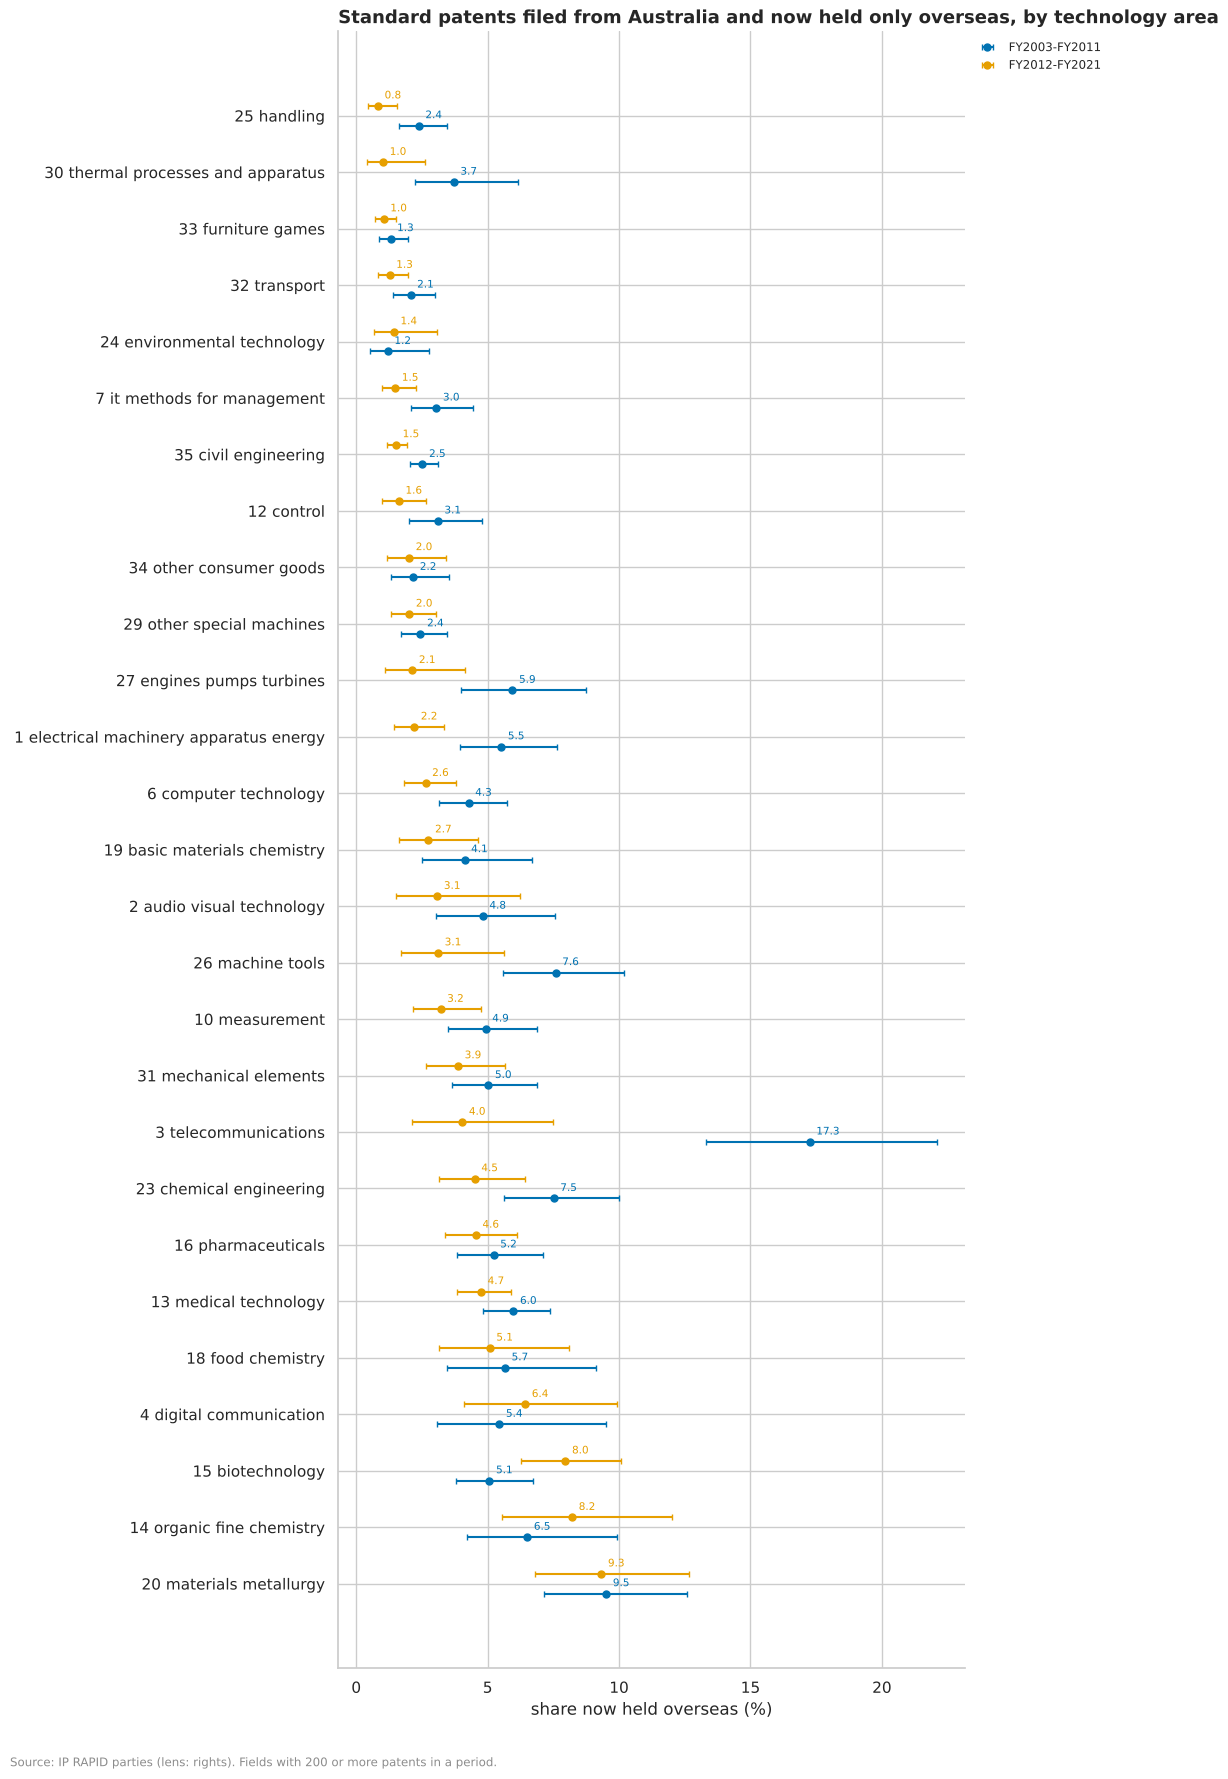

In [21]:
moved = rsql("""
    SELECT CASE WHEN filing_fy <= 2011 THEN 'FY2003-FY2011' ELSE 'FY2012-FY2021' END AS period, founder_type,
           main_area, CASE WHEN family_offices = 1 THEN '1 office' WHEN family_offices < 5 THEN '2 to 4 offices'
                           WHEN family_offices >= 5 THEN '5 or more offices' END AS reach,
           registered_date IS NOT NULL AS granted, count(*) AS n, count(*) FILTER (NOT australian_applicant) AS moved
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2003 AND 2021 AND founding_australian
      AND australian_applicant IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")


def moved_by(col):
    t = moved.dropna(subset=[col]).groupby([col, "period"])[["moved", "n"]].sum()
    t["share"] = t.moved / t.n
    t["low"], t["high"] = bi.wilson(t.moved, t.n)
    return t


for col in ("founder_type", "reach", "granted"):
    t = moved_by(col)
    display((100 * t[["share", "low", "high"]]).round(2).join(t[["moved", "n"]]).unstack("period"))
area = moved_by("main_area")
area = area[area.n >= 200]
wide = area.share.unstack("period").dropna()
order = wide.sort_values("FY2012-FY2021").index
plot = area.reset_index().set_index("main_area").loc[order]
plot.index = plot.index.str.replace("_", " ")
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    title="Standard patents filed from Australia and now held only overseas, by technology area",
    xlabel="share now held overseas",
)
style.source(fig, "IP RAPID parties (lens: rights). Fields with 200 or more patents in a period.")
print(
    "Fields in both periods:",
    len(wide),
    "; agreement of their order (Spearman rho):",
    round(wide.corr(method="spearman").iloc[0, 1], 3),
)
ranked = (100 * wide).round(2).sort_values("FY2012-FY2021", ascending=False)
print("Highest and lowest fields, FY2012-FY2021:")
display(pd.concat([ranked.head(4), ranked.tail(3)]))

#### Observations
**B19 (observational). Patents that move overseas are the wider and the granted ones; organisations' move more, and
the order of fields holds.** Standard patents filed from Australia now held only overseas, FY2003 to FY2011 (FY2012 to
FY2021, which have had less time to change hands):
- **By reach:** five or more offices 14.52% (6.25%), two to four 5.5% (2.56%), one office 3.75% (1.16%).
- **Granted or not:** granted 9.96% (4.81%), never granted 1.15% (0.87%).
- **By filer:** organisations 6.88% (2.8%), individuals 1.63% (1.95%); the organisations' gap holds, smaller, in the
  later period.
- **By field:** highest in materials and metallurgy (9.33% in the later period; 9.51% earlier), organic fine chemistry
  (8.21%; 6.51%) and biotechnology (7.96%; 5.07%); lowest in handling (0.83%; 2.38%), thermal processes (1.02%; 3.71%)
  and furniture and games (1.05%; 1.3%). The 27 fields' order agrees with a Spearman rho of 0.805.
- **So** the rights that leave are the ones their owners valued most (wide and granted): a lead for Q1, since value
  created in Australia may be captured abroad. Third factors: reach and grant are tied to each other and to the field;
  the filing firm's age is in section 2.5.

### 1.8 Summary of the IP rights lens

| # | Pair | What was found | Strength | Holds in the second period? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B1 | Every pair, six types | 223 distinct leads; the decades agree (rho 0.859) | descriptive | method | The leads below |
| B2 | Mechanics (PCT office, inventors, timing) | Expected from how rights are filed and recorded | descriptive | yes | No |
| B3 | Design status × origin | IP RAPID drops failed designs' origin; the register fills it | descriptive | yes | Rule: design origin from the filled column |
| B5 | Filer × filing alone | Australian individuals file alone most | observational | yes (not designs) | Yes, with B6 |
| B6 | Filing alone × grant | Standard patents 36 points less often granted (individuals); trade marks 23 to 24 | observational | yes (not organisations' patents) | Yes: Q4 (help to file) |
| B7 | Origin × time to grant | A 2010s gap only | observational | no | No; route as third factor |
| B8 | Origin × years in force | Australian organisations keep patents longer, within fields too | observational | yes | Yes: Q1, with selection at grant |
| B9 | Field × years in force | 59.4% to 81.2% in force at 10 years | descriptive | weakly (rho 0.459) | Only with B8 |
| B10 | Filer and representation × renewal | Trade marks and designs renewed least by Australian individuals and lone filers | observational | yes | Yes: Q2, Q4 |
| B11 | Origin × reach | Australian organisations narrower, gap narrowing | observational | yes | Yes: Q1 |
| B12 | Origin × citations | Mostly reach | observational | yes | Reach as third factor |
| B13 | Expedited × years in force | Holds for overseas organisations only; Simpson's paradox when pooled | observational | no (pooled) | Yes, by filer: Q1, Q4 |
| B14 | Expedited trade marks × renewal | 1 to 4 points | descriptive | partly | No |
| B15 | Filer × route | Distinct routes; divisionals doubled | descriptive | yes | Divisionals: lead |
| B16 | Invented here × filed from overseas | One in seven made here filed from abroad | descriptive | yes | Yes: Q1 |
| B17 | Field and filer × women among inventors | Field matters (4.2% to 26.9%), filer does not replicate | observational | yes (field) | Yes: Q2 gender analysis |
| B18 | Filer and state × women (provisionals) | Organisations about 5 points higher; states' order holds | observational | yes | Yes: Q2, after OQ17 |
| B19 | Reach, grant, field × moving overseas | Wider, granted, organisations' patents move most | observational | yes | Yes: Q1 |

**Candidate third factors named most often:** the filer (origin and type), family reach, the route of filing, the
technology field, and selection at grant. Stage 3 tests them together.

## 2. Lens: Firms (one row per ABN)

**Rules carried from Stage 1:** firms' IP counts are lower bounds (50,790 ABNs only IPLORD links to IP have counts of
0, U41); counts are compared by medians, ranks or logs, never means alone (U44); age is read with `age_truncated` (a
business first seen through its ABN or GST date before 2001 may be older, U43); an address is where a business is
registered, not where it works (U47). Firms are credited by the filer's ABN, filled from IP Australia's register
(ADR 0029).

**Who is in the lens matters here.** A business is in the lens because it appears in an IP, R&D, procurement or tax
source, so "the share of firms with IP" over the whole lens mostly measures how the lens was built. The planned pairs
therefore look within groups that came in through another door: R&D Tax Incentive claimants, government suppliers and
the large taxpayers in the ATO's transparency reports.

**The two samples.** Firms have no time dimension, so the discovery and replication samples are the two halves of the
lens by a hash of the ABN (about 230,000 each; the screen takes 200,000 of each).

### 2.0 The screen: every pair

verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,221,10,410,0,171,8,33


Agreement between the halves' strengths (Spearman): 0.962


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Average R&D spend claimed × Total income (latest year reported),spearman,0.485,0.406 to 0.552,0.346,moderate,8,rises with,"R&D spend claimed (latest year), Years in the tax transparency reports, Years claiming..."
1,Entity type (ABR) × Business may be older than its first public registration,cramer_v,0.441,0.434 to 0.450,0.438,moderate,7,Local Government Entity with True (15.9× chance),"Entity group, Register that set first_seen, Years since earliest public registration"
2,Entity type (ABR) × Rights held now,rank_eta,0.365,0.362 to 0.368,0.366,moderate,21,"Rights held now: highest median for State Government Statutory Authority (1), lowest f...","Entity group, Applicant or owner of a trade mark (IP RAPID), IP applications as a foun..."
3,ABN is active × Financial year of first trade mark application (filled),rank_eta,0.363,0.358 to 0.367,0.36,moderate,6,"Financial year of first trade mark application (filled): highest median for True (2,01...","Register that set first_seen, Financial year of first trade mark application, Financia..."
4,Entity type (ABR) × Applicant or owner of a trade mark (IP RAPID),cramer_v,0.353,0.350 to 0.357,0.35,moderate,13,ATO Regulated Self-Managed Superannuation Fund with False (2.0× chance),"Rights held now, Entity group, IP applications as a founding applicant (shared ones sp..."
5,Years since earliest public registration × Linked to IP by IPLORD (to FY2020),rank_eta,0.316,0.313 to 0.321,0.315,moderate,4,"Years since earliest public registration: highest median for True (16.1), lowest for F...","Financial year of first trade mark application (filled), Financial year of first trade..."
6,Has a government contract (AusTender) × Trade mark applications,rank_eta,0.316,0.312 to 0.320,0.314,moderate,11,"Trade mark applications: highest median for False (1), lowest for True (0)","An owner in IP Australia's register, Government contracts, Applicant or owner of a tra..."
7,ABN is active × Financial year of first design application (filled),rank_eta,0.311,0.290 to 0.330,0.307,moderate,4,"Financial year of first design application (filled): highest median for True (2,016), ...","Financial year of first trade mark application (filled), Register that set first_seen,..."
8,ABN is active × Financial year of first standard patent application (filled),rank_eta,0.282,0.260 to 0.297,0.26,small,8,Financial year of first standard patent application (filled): highest median for True ...,"Financial year of first trade mark application (filled), Financial year of first trade..."
9,Has a government contract (AusTender) × IP applications as a founding applicant,rank_eta,0.27,0.265 to 0.274,0.268,small,15,"IP applications as a founding applicant: highest median for False (1), lowest for True...","Trade mark applications, Applicant or owner of a trade mark (IP RAPID), IP application..."


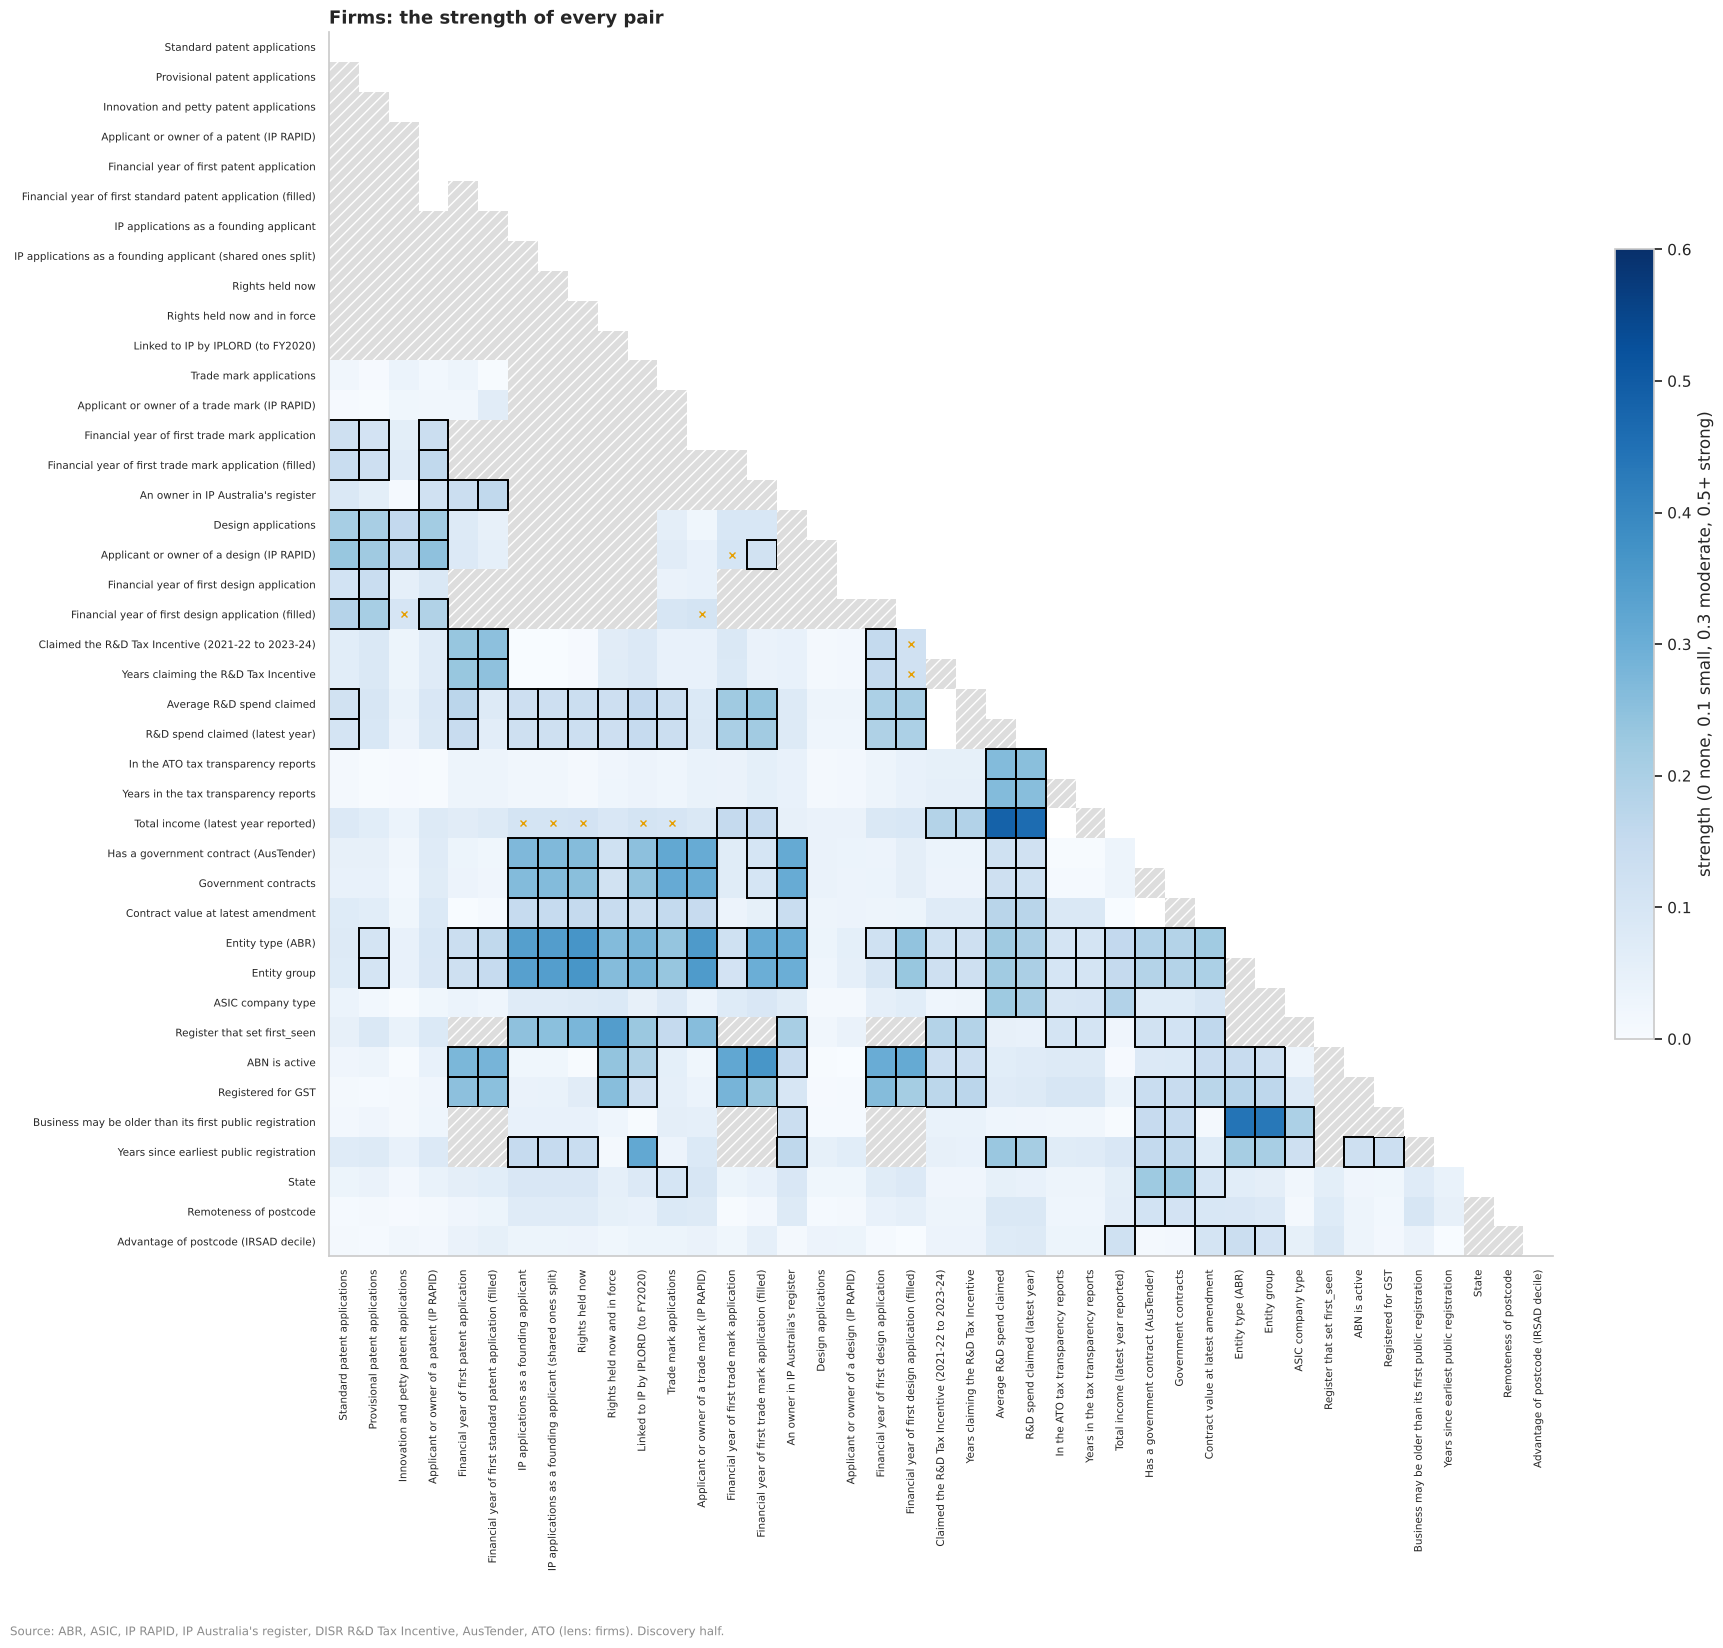

In [22]:
FIRM_GROUPS = bi.screens()["firms"]["groups"]


def flab(c):
    return bi.screen_label("firms", c)


firms_screen = bi.run_screen("firms")
firms_leads = bi.distinct_leads(firms_screen["verdicts"], FIRM_GROUPS)
display(bi.verdict_counts(firms_screen["verdicts"]).to_frame("pairs").T.assign(**{"distinct leads": len(firms_leads)}))
m = firms_screen["verdicts"]
measured = m.dropna(subset=["strength"])
cols = set(measured["variable 1"]) | set(measured["variable 2"])
order = list(dict.fromkeys([c for g in FIRM_GROUPS.values() for c in g if c in cols] + sorted(cols)))
fig = bi.strength_map(m, order, label=flab, title="Firms: the strength of every pair")
style.source(
    fig,
    "ABR, ASIC, IP RAPID, IP Australia's register, DISR R&D Tax Incentive, AusTender, ATO "
    "(lens: firms). Discovery half.",
)
ok = m.dropna(subset=["strength", "strength (replication)"])
print(
    "Agreement between the halves' strengths (Spearman):",
    round(
        ok[~ok["by construction"]].strength.corr(
            ok[~ok["by construction"]]["strength (replication)"], method="spearman"
        ),
        3,
    ),
)
firm_lead_table = bi.leads_table(firms_leads, firms_screen["prepared"], firms_screen["discovery"], label=flab)
with pd.option_context("display.max_rows", 100, "display.width", 250):
    display(firm_lead_table.round(3))

#### Observations
**B20 (descriptive). The screen of the firms lens: 33 distinct leads; the two halves agree almost exactly.** 221 pairs
are leads (33 distinct pairs of measures), 10 passed in one half only, 410 are negligible and 171 are related by
construction. The halves' strengths agree with a Spearman rho of 0.962: random halves of one population are a weaker
test than the rights lens's second decade, so the firms' leads rest more on their size and on the planned pairs below.

**B21 (observational). Most firm leads describe who is in the lens, or the registers' mechanics; a few are
substantive.**
- **How the lens was built:** a government supplier has fewer trade marks (a median 0 against 1; 0.316 in both halves),
  because a firm without a contract is in the lens only if it has IP or another link; entity type goes with rights
  held (0.365; 0.366) and with whether an older business's age is truncated (0.441; 0.438: local government 15.9 times
  chance), which is how ABNs began in 1999 and 2000.
- **Substantive, and followed up below:** larger firms both claim more R&D and report more income (average R&D spend ×
  total income, rho 0.485, interval 0.406 to 0.552, among the few firms that are both large taxpayers and claimants; 0.346
  in the other half); public
  companies claim far more R&D than proprietary ones (a median $1.381m against $0.297m; 0.225; 0.232); firms that hold
  patents also hold designs (5.5 times chance; 0.247; 0.248); R&D spend rises with contract value (0.176; 0.184); and
  government suppliers cluster in the ACT (a median of 1 contract against 0 in NSW; 0.229 in both halves).

### 2.1 Who files IP, among firms that came in through another door

**From:** U41 to U46. **Informs:** Q2, Q3. Among R&D Tax Incentive claimants, government suppliers and the large
taxpayers, the share that has filed any IP (as a founding applicant, `ip_filed_total`, or as the filer by the filled
ABN), by entity group, age and place. Active ABNs; each figure in both halves.

In [23]:
FILED = (
    "(ip_filed_total > 0 OR n_patents_standard + n_patents_provisional + n_patents_second_tier + n_trade_marks"
    " + n_designs > 0)"
)
HALF = "CASE WHEN hash(abn || 'stage2') % 2 = 0 THEN 'discovery' ELSE 'replication' END"
AGE = (
    "CASE WHEN age_truncated THEN 'first seen before 2001 (may be older)' WHEN age_years < 3 THEN 'under 3 years'"
    " WHEN age_years < 10 THEN '3 to 10 years' WHEN age_years < 20 THEN '10 to 20 years' ELSE '20 years or more' END"
)


def by_door(group, door):
    t = (
        sql(f"""
        SELECT {group} AS grp, {HALF} AS half, count(*) AS n, count(*) FILTER ({FILED}) AS filed,
               count(*) FILTER (n_patents_standard > 0) AS patent, count(*) FILTER (n_trade_marks > 0) AS trade_mark
        FROM {{lens/firms}} WHERE abn_active AND {door} GROUP BY ALL
    """)
        .dropna(subset=["grp"])
        .set_index(["grp", "half"])
        .sort_index()
    )
    for c in ("filed", "patent", "trade_mark"):
        t[f"{c} (%)"] = 100 * t[c] / t.n
    lo, hi = bi.wilson(t.filed, t.n)
    t["filed low"], t["filed high"] = 100 * lo, 100 * hi
    return t


DOORS = {
    "R&D Tax Incentive claimants": "in_rdti",
    "Government suppliers": "in_austender",
    "Large taxpayers (ATO transparency)": "in_ato_ctt",
}
overall = pd.concat({name: by_door("'all'", door) for name, door in DOORS.items()})
display(overall.droplevel(1)[["n", "filed (%)", "filed low", "filed high", "patent (%)", "trade_mark (%)"]].round(2))
for g, name in (
    ("entity_group", "entity group"),
    (AGE, "age"),
    ("remoteness", "remoteness"),
    ("irsad_decile", "advantage of postcode (IRSAD decile)"),
):
    t = pd.concat({d: by_door(g, door) for d, door in DOORS.items() if d != "Large taxpayers (ATO transparency)"})
    t = t[t.n >= 50]
    print(f"Share that has filed IP, by {name} (groups of 50 or more):")
    display(t[["n", "filed (%)", "filed low", "filed high"]].round(1).unstack("half"))

n  filed (%)  filed low  filed high  patent (%)  trade_mark (%)
                                   half                                                                            
R&D Tax Incentive claimants        discovery     8909      51.41      50.37       52.45       12.26           45.26
                                   replication   8734      51.89      50.84       52.94       12.71            45.8
Government suppliers               discovery    26287      25.02       24.5       25.54        3.12           23.75
                                   replication  26597      25.09      24.57       25.61        3.21           23.95
Large taxpayers (ATO transparency) discovery     3184      40.45      38.76       42.17        7.54           39.35
                                   replication   3126       41.2      39.49       42.94        8.06           39.32

Share that has filed IP, by entity group (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                                        discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                                     
R&D Tax Incentive claimants Private company      8429        8210      50.7        51.1      49.7          50       51.8        52.2
                            Public company        459         510      63.8        64.7      59.3        60.5       68.1        68.7
Government suppliers        Government            673         651      39.4        46.1      35.8        42.3       43.1        49.9
                            Other                1487        1482      29.5        28.1      27.2        25.9       31.8        30.5
                            Partnership           703         721       6.5         6.1       4.9         4.6        8.6         8.1
                            Private company     15064       15307      31.4        31.2      30.7        30.5       32.2          32
                            Public company       1236        1273      65.1        63.7      62.4          61       67.7        66.3
                            Sole trader          3650        3711       1.2         1.3       0.9           1        1.6         1.7
                            Super fund             63          73         0         2.7        -0         0.8        5.7         9.5
                            Trust                3411        3379       7.2           8       6.4         7.1        8.2           9

Share that has filed IP, by age (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                                                              discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                                                           
R&D Tax Incentive claimants 10 to 20 years                             2633        2593      55.7        56.8      53.8        54.9       57.6        58.7
                            20 years or more                           1782        1766      67.4        66.6      65.2        64.4       69.5        68.8
                            3 to 10 years                              4350        4208        43        43.4      41.6          42       44.5        44.9
                            under 3 years                               134         152      26.9        30.3      20.1        23.5       34.9          38
Government suppliers        10 to 20 years                             7251        7398      20.6        20.9      19.7          20       21.6        21.8
                            20 years or more                          10436       10657      35.7        35.6      34.8        34.7       36.7        36.5
                            3 to 10 years                              4168        4131      14.2        13.9      13.2        12.9       15.3          15
                            first seen before 2001 (may be older)      3781        3752      19.5        19.8      18.3        18.6       20.8        21.1
                            under 3 years                               651         659       3.2         2.9       2.1         1.9        4.9         4.5

Share that has filed IP, by remoteness (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                                                  discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                                               
R&D Tax Incentive claimants Inner Regional Australia        630         646      49.8        51.4      45.9        47.5       53.7        55.2
                            Major Cities of Australia      8007        7824      51.9        52.1      50.8          51         53        53.2
                            Outer Regional Australia        234         229      39.3        46.7      33.3        40.4       45.7        53.2
Government suppliers        Inner Regional Australia       3017        2939      17.1        16.4      15.8        15.1       18.5        17.8
                            Major Cities of Australia     20489       20877      27.8          28      27.2        27.4       28.4        28.6
                            Outer Regional Australia       1930        1912        13          12      11.6        10.6       14.6        13.5
                            Remote Australia                354         353      10.5        10.8       7.7         7.9       14.1        14.4
                            Very Remote Australia           357         375       8.4         8.3       5.9         5.9       11.7        11.5

Share that has filed IP, by advantage of postcode (IRSAD decile) (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                            discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                         
R&D Tax Incentive claimants 1         163         186      48.5        55.4      40.9        48.2       56.1        62.3
                            2         309         326        57        51.2      51.4        45.8       62.4        56.6
                            3         231         221      48.9        47.5      42.5          41       55.3        54.1
                            4         372         335      49.7        52.8      44.7        47.5       54.8        58.1
                            5         351         379      51.9        46.4      46.6        41.5         57        51.5
                            6         506         469        54        51.4      49.6        46.9       58.2        55.9
                            7         515         521      54.2        55.5      49.9        51.2       58.4        59.7
                            8        1063        1075      50.8        50.3      47.8        47.3       53.8        53.3
                            9        1865        1789      50.9        51.1      48.6        48.8       53.1        53.5
                            10       3468        3377      50.9        52.7      49.3        51.1       52.6        54.4
Government suppliers        1         985         974      20.2        21.4      17.8        18.9       22.8          24
                            2        1185        1226      23.1        22.1      20.8        19.9       25.6        24.5
                            3         921         880      19.8        21.7      17.3        19.1       22.5        24.5
                            4        1324        1333      19.4        19.8      17.4        17.8       21.6          22
                            5        1581        1569      20.3        19.6      18.4        17.7       22.4        21.6
                            6        1538        1513      22.5        22.4      20.5        20.4       24.7        24.6
                            7        1565        1584      24.3        22.2      22.3        20.2       26.5        24.3
                            8        2797        2878        25        23.8      23.4        22.2       26.6        25.4
                            9        5137        5228      26.7        26.8      25.5        25.6       27.9          28
                            10       8986        9146      27.1        27.9      26.2          27       28.1        28.8

In [24]:
# The gradient by advantage of postcode, as one number per door and half: Spearman's rho between IRSAD decile and
# the share that has filed IP (10 deciles)
rows = []
for d, door in DOORS.items():
    if d.startswith("Large"):
        continue
    t = by_door("irsad_decile", door).reset_index()
    for h, g in t.groupby("half"):
        rho = g.grp.astype(float).corr(g["filed (%)"], method="spearman")
        lo, hi = g["filed (%)"].iloc[0], g["filed (%)"].iloc[-1]
        rows.append({"door": d, "half": h, "rho (decile, share)": rho, "decile 1 (%)": lo, "decile 10 (%)": hi})
pd.DataFrame(rows).set_index(["door", "half"]).round(3)

rho (decile, share)  decile 1 (%)  decile 10 (%)
door                        half                                                         
R&D Tax Incentive claimants discovery                  0.236         48.47          50.92
                            replication               -0.055         55.38          52.74
Government suppliers        discovery                  0.806          20.2          27.14
                            replication                0.782         21.36          27.88

#### Observations
**B22 (observational). Among firms that came in through another door, filing IP goes with being a company, older, and
in a city; and, for government suppliers, with an advantaged postcode.** Active ABNs, discovery half (replication):
- **Overall:** 51.41% of R&D Tax Incentive claimants have filed IP (51.89%), 25.02% of government suppliers (25.09%),
  and 40.45% of the large taxpayers (41.2%). Trade marks dominate: 45.26%, 23.75% and 39.35% have filed one; standard
  patents 12.26%, 3.12% and 7.54%.
- **Entity group (government suppliers):** public companies 65.1% (63.7%), private companies 31.4% (31.2%), trusts
  7.2% (8.0%), partnerships 6.5% (6.1%), sole traders 1.2% (1.3%). Claimants: public companies 63.8% (64.7%), private
  50.7% (51.1%).
- **Age:** claimants under 3 years old 26.9% (30.3%), 20 years or more 67.4% (66.6%); suppliers 3.2% (2.9%) and
  35.7% (35.6%). Age is partly time: an older firm has had longer to file.
- **Remoteness (suppliers):** major cities 27.8% (28.0%), inner regional 17.1% (16.4%), very remote 8.4% (8.3%).
- **Advantage of postcode:** for suppliers the share rises steadily from 20.2% in the most disadvantaged tenth of
  postcodes to 27.14% in the most advantaged (Spearman rho over the deciles 0.806; 0.782 in the other half). For R&D
  claimants there is no gradient (rho 0.236, then -0.055; 48.47% to 50.92%, then 55.38% to 52.74%): once a firm does
  R&D, where it is registered does not go with filing.
- **Third factors:** firm size (companies, older firms and city firms are larger), industry (not in the ABR), and
  where a business is registered rather than where it works (U47).

### 2.2 IP and R&D: spend, and the claimants who have never filed ('missing filers')

**From:** U41, U54. **Informs:** Q3, Q4. Among active R&D Tax Incentive claimants: does more R&D spend go with
patenting, and where are the claimants who have never filed IP? A missing filer is a claimant with no IP application
as a founding applicant (`ip_filed_total` = 0, as the `regions` lens counts them, U54); the count is an upper bound,
since IPLORD links some of them to IP that IP RAPID gives no ABN (shown beside). The ABR gives no industry, so
missing filers by industry wait for the `industries` lens.

Active claimants with a recorded R&D spend: 17,514


claimants             median_spend                patent             trade_mark             never_filed            
half         discovery replication    discovery replication discovery replication  discovery replication   discovery replication
spend_decile                                                                                                                    
1                  893         859    4.479e+04   4.493e+04       9.5         9.8       39.8        39.7          54          54
2                  911         841    8.779e+04   8.874e+04       9.8         9.2       40.4        41.7        54.2        54.9
3                  852         900    1.384e+05   1.384e+05       8.3        10.4       41.1        42.2        55.5        54.4
4                  879         873    2.005e+05       2e+05       8.1         7.1       42.3        42.8        55.2        53.4
5                  901         850    2.754e+05   2.783e+05      10.4        10.7       46.9        46.7        50.4        50.8
6                  878         873    3.829e+05   3.826e+05        13        11.2       46.5          47        48.3        50.3
7                  885         866    5.343e+05   5.352e+05      11.3        12.2         45        50.9        49.9        45.8
8                  897         854    8.152e+05   8.034e+05      10.9        15.6       47.9        49.1        49.6          48
9                  877         874    1.392e+06   1.396e+06        18        16.8       51.9        49.7        44.9        48.1
10                 868         883     3.79e+06   3.368e+06      24.1        24.3       51.8        49.8        45.5        44.4

discovery: rho(R&D spend, standard patents) = 0.120; rho(R&D spend, trade marks) = 0.135; n = 8,841
replication: rho(R&D spend, standard patents) = 0.128; rho(R&D spend, trade marks) = 0.124; n = 8,673


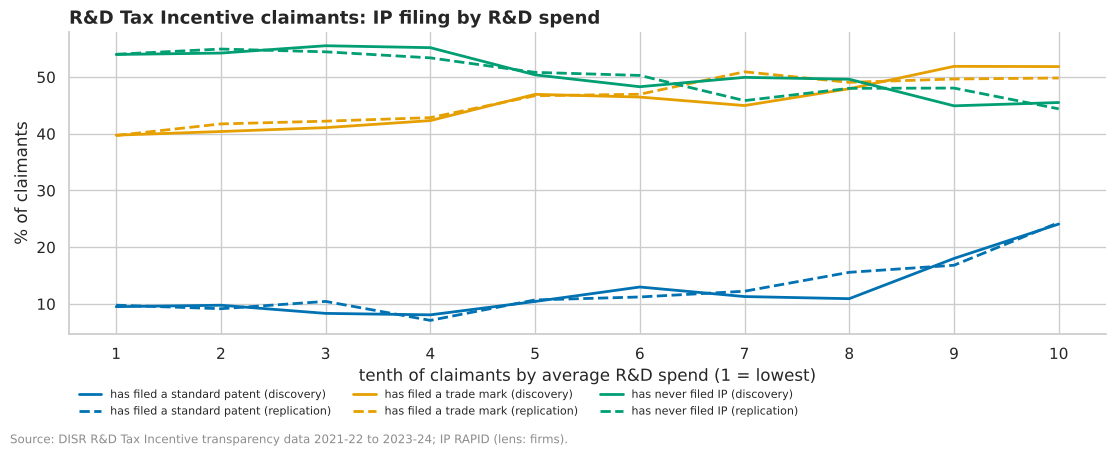

In [25]:
rd = sql(
    f"""
    SELECT {HALF} AS half, ntile(10) OVER (ORDER BY rd_expenditure_mean) AS spend_decile, rd_expenditure_mean,
           n_patents_standard, n_trade_marks, ip_filed_total, in_iplord, entity_group, state, remoteness,
           irsad_decile, {AGE} AS age
    FROM {{lens/firms}} WHERE abn_active AND in_rdti AND rd_expenditure_mean > 0
""",
    max_rows=None,
)
print(f"Active claimants with a recorded R&D spend: {len(rd):,}")
dec = rd.groupby(["spend_decile", "half"]).agg(
    claimants=("rd_expenditure_mean", "size"),
    median_spend=("rd_expenditure_mean", "median"),
    patent=("n_patents_standard", lambda s: (s > 0).mean()),
    trade_mark=("n_trade_marks", lambda s: (s > 0).mean()),
    never_filed=("ip_filed_total", lambda s: (s == 0).mean()),
)
display((dec.assign(**{c: 100 * dec[c] for c in ("patent", "trade_mark", "never_filed")})).round(1).unstack("half"))
for h, g in rd.groupby("half"):
    s1 = bi.pair_stats(np.log10(g.rd_expenditure_mean), g.n_patents_standard)
    s2 = bi.pair_stats(np.log10(g.rd_expenditure_mean), g.n_trade_marks)
    print(
        f"{h}: rho(R&D spend, standard patents) = {s1['spearman rho']:.3f};",
        f"rho(R&D spend, trade marks) = {s2['spearman rho']:.3f}; n = {s1['n']:,.0f}",
    )
plot = dec.reset_index()
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (col, name) in enumerate(
    (
        ("patent", "has filed a standard patent"),
        ("trade_mark", "has filed a trade mark"),
        ("never_filed", "has never filed IP"),
    )
):
    for h, ls in (("discovery", "-"), ("replication", "--")):
        d = plot[plot.half == h]
        ax.plot(d.spend_decile, 100 * d[col], ls=ls, color=style.PALETTE[i], lw=2, label=f"{name} ({h})")
ax.set_xticks(range(1, 11))
ax.set_xlabel("tenth of claimants by average R&D spend (1 = lowest)")
ax.set_ylabel("% of claimants")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("R&D Tax Incentive claimants: IP filing by R&D spend")
style.source(fig, "DISR R&D Tax Incentive transparency data 2021-22 to 2023-24; IP RAPID (lens: firms).")

In [26]:
mf = []
for col, name in (
    ("state", "state"),
    ("remoteness", "remoteness"),
    ("irsad_decile", "IRSAD decile"),
    ("entity_group", "entity group"),
    ("age", "age"),
):
    t = (
        rd.dropna(subset=[col])
        .groupby([col, "half"])
        .agg(
            n=("ip_filed_total", "size"),
            missing=("ip_filed_total", lambda s: (s == 0).sum()),
            iplord=("in_iplord", lambda s: s.fillna(False).sum()),
        )
    )
    t = t[t.n >= 50]
    t["missing filers (%)"] = 100 * t.missing / t.n
    lo, hi = bi.wilson(t.missing, t.n)
    t["low"], t["high"] = 100 * lo, 100 * hi
    t["of whom IPLORD links to IP (%)"] = 100 * t.iplord / t.n
    mf.append(t.assign(by=name).reset_index().rename(columns={col: "group"}))
mf = pd.concat(mf).set_index(["by", "group", "half"])
mf[["n", "missing filers (%)", "low", "high", "of whom IPLORD links to IP (%)"]].round(1).unstack("half")

n             missing filers (%)                   low                  high              \
half                                    discovery replication          discovery replication discovery replication discovery replication   
by           group                                                                                                                         
IRSAD decile 1                                163         185               52.1        46.5      44.5        39.4      59.7        53.7   
             2                                305         324               45.6        50.6      40.1        45.2      51.2          56   
             3                                228         219               51.8        53.9      45.3        47.3      58.2        60.4   
             4                                366         333               53.3        49.2      48.2        43.9      58.3        54.6   
             5                                350         375               50.6        54.1      45.4        49.1      55.8        59.1   
             6                                500         466               48.2          50      43.9        45.5      52.6        54.5   
             7                                513         517               47.4        47.2      43.1        42.9      51.7        51.5   
             8                               1054        1070               51.2          52      48.2          49      54.2        54.9   
             9                               1855        1780               51.7        51.1      49.4        48.7        54        53.4   
             10                              3442        3349               51.2          50      49.5        48.3      52.9        51.7   
age           10 to 20 years                 2616        2584               46.8        45.7      44.8        43.8      48.7        47.6   
              20 years or more               1775        1761               35.8        36.7      33.6        34.5      38.1          39   
              3 to 10 years                  4307        4163               58.6        58.5      57.1          57      60.1          60   
              under 3 years                   133         150               74.4        71.3      66.4        63.6      81.1          78   
entity group  Private company                8361        8149               51.4        51.1      50.3          50      52.5        52.1   
              Public company                  459         510               39.9        39.8      35.5        35.6      44.4        44.1   
remoteness    Inner Regional Australia        623         644               52.3        50.8      48.4        46.9      56.2        54.6   
              Major Cities of Australia      7949        7767               50.3        50.2      49.2        49.1      51.4        51.3   
              Outer Regional Australia        232         227               62.1        56.8      55.7        50.3      68.1        63.1   
state         ACT                             121         126               35.5          50      27.6        41.4      44.4        58.6   
              NSW                            3214        3117               50.4        49.9      48.6        48.1      52.1        51.6   
              QLD                            1513        1559               51.8        52.3      49.3        49.8      54.3        54.7   
              SA                              477         481               49.9        47.8      45.4        43.4      54.4        52.3   
              TAS                              82          79               53.7        58.2      42.9        47.2        64        68.5   
              VIC                            2457        2393               50.6        50.1      48.6        48.1      52.6        52.1   
              WA                              952         895               52.4        50.3      49.2          47      55.6    

#### Observations
**B23 (observational). More R&D spend goes with patenting, but only weakly; about half of claimants have never filed
IP at any spend.** 17,514 active claimants with a recorded spend:
- **Standard patents:** 9.5% of the lowest-spending tenth of claimants (median $44,790 a year) have filed one, rising
  to 24.1% of the highest-spending tenth (median $3.79m); 9.8% and 24.3% in the other half. Spearman's rho between
  spend and patent applications is 0.120 (0.128): small.
- **Never filed IP:** 54% of the lowest-spending tenth and 45.5% of the highest (54% and 44.4%).
- **Missing filers (no IP as a founding applicant)** are most common among young claimants (under 3 years: 74.4%;
  71.3%) and least among the oldest (20 years or more: 35.8%; 36.7%), more common among private companies (51.4%;
  51.1%) than public ones (39.9%; 39.8%), and somewhat more common in outer regional areas (62.1%; 56.8%) than in
  major cities (50.3%; 50.2%). They do not vary with the advantage of the postcode (from 45.6% to 53.3% across the
  deciles, with no order).
- **An upper bound for older firms:** IPLORD links 54.3% (56.2%) of the oldest missing filers to IP that IP RAPID
  gives no ABN, against 10.4% (9.8%) of those 3 to 10 years old and none under 3. Among young claimants the count is
  close to exact.
- **So** the claimants who do R&D but have never filed IP are mostly young private companies, wherever they are: a lead
  for Q4 (where an intervention could add most), with industry, which the ABR does not give, as the main missing third
  factor.

### 2.3 IP and government contracts, and income

**From:** U46. **Informs:** Q3. Among active government suppliers: do firms that have filed IP win more or larger
contracts? Among the large taxpayers: do those with IP report higher income? Both halves; medians, with the
rank-biserial correlation as the size of the difference.

In [27]:
sup = sql(
    f"""
    SELECT {HALF} AS half, {FILED} AS filed, entity_group, austender_contracts, austender_value, total_income_latest,
           in_austender, in_ato_ctt
    FROM {{lens/firms}} WHERE abn_active AND (in_austender OR in_ato_ctt)
""",
    max_rows=None,
)
rows = []
for (h, who), d in (
    *(((h, "government suppliers"), g[g.in_austender.fillna(False)]) for h, g in sup.groupby("half")),
    *(((h, "large taxpayers"), g[g.in_ato_ctt.fillna(False)]) for h, g in sup.groupby("half")),
):
    for col in ["austender_contracts", "austender_value"] if who == "government suppliers" else ["total_income_latest"]:
        dd = d.dropna(subset=[col])
        a, b = dd[dd.filed][col], dd[~dd.filed][col]
        diff, lo, hi = bi.median_difference(a, b)
        rb = bi.compare_groups(pd.Series(np.r_[a, b]), pd.Series([0] * len(a) + [1] * len(b)))
        rows.append(
            {
                "who": who,
                "measure": col,
                "half": h,
                "with IP": len(a),
                "without": len(b),
                "median with IP": a.median(),
                "median without": b.median(),
                "difference": diff,
                "low": lo,
                "high": hi,
                "rank-biserial": rb["rank-biserial"],
            }
        )
pd.DataFrame(rows).set_index(["who", "measure", "half"]).round(3)

with IP  without  median with IP  median without  difference        low      high  rank-biserial
who                  measure             half                                                                                                         
government suppliers austender_contracts discovery       6576    19711               3               2           1          1         2          0.226
                     austender_value     discovery       6576    19711       2.734e+05       1.138e+05   1.597e+05  1.357e+05  1.85e+05          0.205
                     austender_contracts replication     6672    19925               3               2           1          1         2          0.229
                     austender_value     replication     6672    19925       2.773e+05         1.1e+05   1.673e+05  1.492e+05 1.951e+05          0.212
large taxpayers      total_income_latest discovery       1288     1896       2.146e+08       1.868e+08   2.782e+07  1.338e+07 4.504e+07          0.079
                                         replication     1288     1838        2.04e+08       2.002e+08   3.746e+06 -8.291e+06 1.949e+07           0.04

In [28]:
# Within entity groups (a candidate third factor: companies both file IP and win contracts more than sole traders)
rows = []
for (h, eg), d in sup[sup.in_austender.fillna(False)].groupby(["half", "entity_group"]):
    a, b = d[d.filed].austender_value.dropna(), d[~d.filed].austender_value.dropna()
    if len(a) >= 50 and len(b) >= 50:
        rb = bi.compare_groups(pd.Series(np.r_[a, b]), pd.Series([0] * len(a) + [1] * len(b)))
        rows.append(
            {
                "entity group": eg,
                "half": h,
                "with IP": len(a),
                "without": len(b),
                "median value with IP": a.median(),
                "median value without": b.median(),
                "rank-biserial": rb["rank-biserial"],
            }
        )
pd.DataFrame(rows).set_index(["entity group", "half"]).round(3).unstack("half")

with IP               without             median value with IP             median value without             rank-biserial            
half            discovery replication discovery replication            discovery replication            discovery replication     discovery replication
entity group                                                                                                                                           
Government            265         300       408         351            1.111e+06   1.123e+06            1.982e+05   1.795e+05         0.387       0.317
Other                 438         417      1049        1065            4.109e+05   4.251e+05            1.117e+05   1.081e+05          0.27       0.265
Private company      4732        4780     10332       10527            2.363e+05   2.385e+05            1.452e+05   1.335e+05         0.114       0.126
Public company        805         811       431         462            6.323e+05   5.737e+05            2.434e+05   2.051e+05           0.2       0.214
Trust                 247         270      3164        3109            1.207e+05   1.085e+05            9.243e+04   9.557e+04         0.044       0.065

#### Observations
**B24 (observational). Government suppliers that have filed IP win more and larger contracts, within every kind of
entity; large taxpayers with IP do not report clearly more income.**
- **Suppliers:** a median 3 contracts against 2 (both halves) and a median contract value of $273,400 against
  $113,800 (a difference of $159,700, interval $135,700 to $185,000; rank-biserial 0.205); replication $277,300 against
  $110,000 (0.212).
- **Within entity groups** the gap holds in both halves: private companies (rank-biserial 0.114; 0.126), public
  companies (0.2; 0.214), government bodies (0.387; 0.317), other entities (0.27; 0.265); for trusts it is negligible
  (0.044; 0.065).
- **Large taxpayers:** median income $214.6m with IP against $186.8m without (rank-biserial 0.079), and $204.0m against
  $200.2m in the other half (0.04; interval -$8.3m to $19.5m, which includes no difference): not a lead.
- **Not a cause:** IP and contracts may both follow from a firm's size and capability. Firm size (employees, turnover)
  is not in the lens; it is the main candidate third factor.

### 2.4 How old firms are when they first file

**From:** U43, U45. **Informs:** Q2. A firm's age at its first application of each kind, for first filings FY2010 to
FY2026 (filled from the register, so the years after FY2024 count), among firms whose first public registration is not
truncated (first seen in 2001 or later, so their age is real). Age is measured from the first public registration to
the middle of the financial year of first filing.

firms                median                   p25                   p75               under_1               over_10            
half            discovery replication discovery replication discovery replication discovery replication discovery replication discovery replication
kind                                                                                                                                               
design               2993        2941      4.72        4.23      1.24        0.96        12       11.23     22.65       25.57     30.27       28.15
standard patent      4025        4092      4.62        4.76         2           2     11.36       11.48     13.39       13.42     28.42       28.32
trade mark          73458       73501      2.03        2.06      0.07        0.08      6.85        6.97     39.61       39.26     16.71       17.05

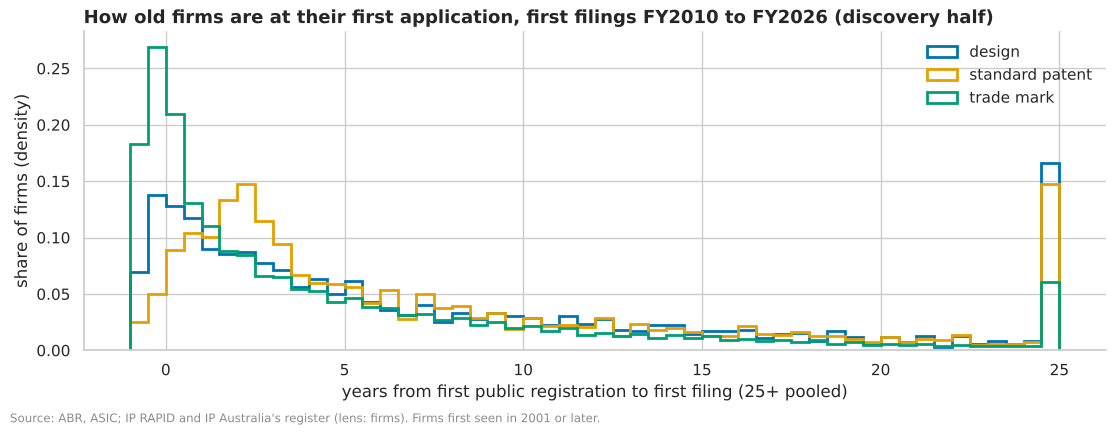

In [29]:
first = sql(
    f"""
    SELECT {HALF} AS half, kind, entity_group, (fy - 0.5) - (year(first_seen) + dayofyear(first_seen) / 365.25) AS age
    FROM (SELECT abn, first_seen, entity_group, age_truncated, 'standard patent' AS kind, patent_first_fy_filled AS fy
          FROM {{lens/firms}} UNION ALL
          SELECT abn, first_seen, entity_group, age_truncated, 'trade mark', trade_mark_first_fy_filled
          FROM {{lens/firms}} UNION ALL
          SELECT abn, first_seen, entity_group, age_truncated, 'design', design_first_fy_filled FROM {{lens/firms}})
    WHERE fy BETWEEN 2010 AND 2026 AND NOT age_truncated AND first_seen IS NOT NULL
""",
    max_rows=None,
)
first = first[first.age > -1]
t = first.groupby(["kind", "half"]).age.agg(
    firms="size",
    median="median",
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
    under_1=lambda s: 100 * (s < 1).mean(),
    over_10=lambda s: 100 * (s >= 10).mean(),
)
display(t.round(2).unstack("half"))
fig, ax = plt.subplots(figsize=(11, 4))
for i, (k, d) in enumerate(first[first.half == "discovery"].groupby("kind")):
    ax.hist(
        d.age.clip(upper=25),
        bins=np.arange(-1, 25.5, 0.5),
        density=True,
        histtype="step",
        lw=2,
        color=style.PALETTE[i],
        label=k,
    )
ax.set_xlabel("years from first public registration to first filing (25+ pooled)")
ax.set_ylabel("share of firms (density)")
ax.legend(frameon=False)
ax.set_title("How old firms are at their first application, first filings FY2010 to FY2026 (discovery half)")
style.source(fig, "ABR, ASIC; IP RAPID and IP Australia's register (lens: firms). Firms first seen in 2001 or later.")

#### Observations
**B25 (descriptive). Firms file their first trade mark early, their first patent or design later.** Firms first seen
in 2001 or later, first filings FY2010 to FY2026 (other half):
- **Trade marks:** a median 2.03 years after the firm's first public registration (2.06); 39.61% (39.26%) within the
  first year; 16.71% (17.05%) after 10 years or more.
- **Standard patents:** a median 4.62 years (4.76); 13.39% (13.42%) within the first year; 28.42% (28.32%) after 10
  years or more.
- **Designs:** a median 4.72 years (4.23).
- Age counts from the first public registration (ABN, GST or ASIC), a lower bound on the business's start (U43), so
  these are lower bounds on age at first filing.

### 2.5 Rights moving overseas, by the filing firm's age

**From:** U18 (section 1.7). **Informs:** Q1, Q2. Standard patents filed from Australia by a firm with an ABN, FY2003
to FY2021, joined to the firm: the share now held only overseas, by the firm's age when it filed (firms first seen in
2001 or later only, so ages run to about 20 years), in the two periods of section 1.7.

In [30]:
mv = (
    sql("""
    SELECT CASE WHEN r.filing_fy <= 2011 THEN 'FY2003-FY2011' ELSE 'FY2012-FY2021' END AS period,
           CASE WHEN (r.filing_fy - 0.5) - year(f.first_seen) < 2 THEN '1: under 2 years'
                WHEN (r.filing_fy - 0.5) - year(f.first_seen) < 5 THEN '2: 2 to 5 years'
                WHEN (r.filing_fy - 0.5) - year(f.first_seen) < 10 THEN '3: 5 to 10 years'
                ELSE '4: 10 years or more' END AS age_at_filing,
           count(*) AS n, count(*) FILTER (NOT r.australian_applicant) AS moved,
           count(*) FILTER (r.family_offices >= 5) AS wide
    FROM {lens/rights} r JOIN {lens/firms} f ON f.abn = r.filer_abn
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2003 AND 2021 AND r.founding_australian
      AND r.australian_applicant IS NOT NULL AND NOT f.age_truncated AND f.first_seen IS NOT NULL
      AND year(f.first_seen) <= r.filing_fy
    GROUP BY ALL
""")
    .set_index(["age_at_filing", "period"])
    .sort_index()
)
mv["moved (%)"] = 100 * mv.moved / mv.n
lo, hi = bi.wilson(mv.moved, mv.n)
mv["low"], mv["high"] = 100 * lo, 100 * hi
mv["five or more offices (%)"] = 100 * mv.wide / mv.n
mv.round(2).unstack("period")

n                       moved                        wide                   moved (%)                         low  \
period              FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011   
age_at_filing                                                                                                                                       
1: under 2 years              577           941            33            37            71           194          5.72          3.93           4.1   
2: 2 to 5 years               934          2023            18            43           146           540          1.93          2.13          1.22   
3: 5 to 10 years             1314          2165            62            29           250           549          4.72          1.34           3.7   
4: 10 years or more          4341          8665           143           202           703          1747          3.29          2.33           2.8   

                                           high               five or more offices (%)                
period              FY2012-FY2021 FY2003-FY2011 FY2012-FY2021            FY2003-FY2011 FY2012-FY2021  
age_at_filing                                                                                         
1: under 2 years             2.87          7.92          5.37                    12.31         20.62  
2: 2 to 5 years              1.58          3.03          2.85                    15.63         26.69  
3: 5 to 10 years             0.93             6          1.92                    19.03         25.36  
4: 10 years or more          2.03          3.87          2.67                    16.19         20.16

#### Observations
**B26 (observational). Patents filed by the youngest firms move overseas more often, in both periods, though the
numbers are small.** Standard patents filed from Australia by a firm first seen in 2001 or later, now held only
overseas:
- **Firms under 2 years old when they filed:** 5.72% (33 of 577; interval 4.1% to 7.92%) for FY2003 to FY2011 filings,
  3.93% (37 of 941; 2.87% to 5.37%) for FY2012 to FY2021.
- **Firms 2 to 5 years old:** 1.93% and 2.13%; **5 to 10 years:** 4.72% and 1.34%; **10 years or more:** 3.29% and
  2.33%.
- The youngest firms' patents are not the widest (12.31% and 20.62% filed in five or more offices, against 15.63% to
  26.69% for older firms'), so reach does not explain the gap. Candidate third factors: the sale of young firms to
  overseas buyers, and founders moving abroad; neither is in the data. A lead for Q1, small enough to need Stage 3's
  care.

### 2.6 Size and industry among employers of 100 or more (WGEA; added after Stage 2, gap A3)

**From:** U112, B21 to B24. **Informs:** Q2, Q3. Among the firms with a WGEA report only: the share that has filed IP
by size band and by division, with Wilson intervals, the gap between the largest and smallest bands (Newcombe's
interval), the rank correlation with headcount in the lens's two halves, and B23's R&D pair within size bands.

In [31]:
# Among firms with a WGEA report (100 or more employees): the share that has filed any IP, a standard patent and a
# trade mark, by size band and by ANZSIC division, with Wilson intervals; and the rank correlation of headcount with
# filing, in the two halves of the lens (the replication rule of section 2)
w = sql("""
    SELECT abn, wgea_employees, wgea_size_band, wgea_division, rd_latest, in_rdti,
           (n_patents_standard + n_patents_provisional + n_patents_second_tier
                    + n_trade_marks + n_designs > 0) AS files_ip,
           n_patents_standard > 0 AS files_patent, n_trade_marks > 0 AS files_tm,
           n_patents_standard, n_trade_marks
    FROM {lens/firms} WHERE wgea_year IS NOT NULL ORDER BY abn
""")
w["half"] = bi.split_half(w.abn)
order = ["<250", "250-499", "500-999", "1000-4999", "5000+"]
rows = []
for flag in ["files_ip", "files_patent", "files_tm"]:
    t = bi.rate_by(w[flag], w.wgea_size_band).reindex(order)
    rows.append(t.assign(measure=flag))
by_size = pd.concat(rows).rename_axis("size band").reset_index()
display(by_size.set_index(["measure", "size band"]).round(3))
gaps = []
for flag in ["files_ip", "files_patent", "files_tm"]:
    t = bi.rate_by(w[flag], w.wgea_size_band)
    d, lo, hi = bi.rate_difference(t.loc["5000+", "yes"], t.loc["5000+", "n"], t.loc["<250", "yes"], t.loc["<250", "n"])
    gaps.append(
        {"measure": flag, "5000+ minus <250 (points)": 100 * d, "95% interval": f"{100 * lo:.1f} to {100 * hi:.1f}"}
    )
display(pd.DataFrame(gaps).round(1))
corr = []
for half, g in w.groupby("half"):
    for flag in ["files_ip", "files_patent", "files_tm"]:
        corr.append(
            {
                "half": half,
                "measure": flag,
                "firms": len(g),
                "rho (employees × files)": bi.association(
                    g.wgea_employees.to_numpy(float), g[flag].to_numpy(float), "number", "number"
                )["rho"],
            }
        )
pd.DataFrame(corr).pivot(index="measure", columns="half", values="rho (employees × files)").rename(
    columns={True: "discovery half", False: "replication half"}
).round(3)

n   yes  rate   low  high
measure      size band                              
files_ip     <250       3599 2,523 0.701 0.686 0.716
             250-499    1654 1,213 0.733 0.712 0.754
             500-999     892   655 0.734 0.704 0.762
             1000-4999   838   651 0.777 0.747 0.804
             5000+       137   113 0.825 0.753 0.879
files_patent <250       3599   392 0.109 0.099  0.12
             250-499    1654   234 0.141 0.126 0.159
             500-999     892   138 0.155 0.132  0.18
             1000-4999   838   163 0.195 0.169 0.223
             5000+       137    45 0.328 0.255 0.411
files_tm     <250       3599 2,464 0.685 0.669   0.7
             250-499    1654 1,172 0.709 0.686  0.73
             500-999     892   642  0.72 0.689 0.748
             1000-4999   838   632 0.754 0.724 0.782
             5000+       137   111  0.81 0.736 0.867

,measure,5000+ minus <250 (points),95% interval
0,files_ip,12.4,5.0 to 18.0
1,files_patent,22,14.6 to 30.3
2,files_tm,12.6,5.0 to 18.4


half,replication half,discovery half
measure,,
files_ip,0.056,0.074
files_patent,0.093,0.091
files_tm,0.057,0.065


In [32]:
# By division: the share filing a standard patent and a trade mark among covered firms (divisions with 30 or more)
names = (
    sql("SELECT division, any_value(division_name) AS name FROM {lens/industries} GROUP BY 1")
    .set_index("division")
    .name
)
t_pat = bi.rate_by(w.files_patent, w.wgea_division)
t_tm = bi.rate_by(w.files_tm, w.wgea_division)
both = t_pat.add_prefix("patent: ").join(t_tm.add_prefix("trade mark: "))
both = both[both["patent: n"] >= 30]
both.insert(0, "name", names.reindex(both.index))
display(both.sort_values("patent: rate", ascending=False).round(3))

,name,patent: n,patent: yes,patent: rate,patent: low,patent: high,trade mark: n,trade mark: yes,trade mark: rate,trade mark: low,trade mark: high
g,,,,,,,,,,,
C,Manufacturing,885,350,0.395,0.364,0.428,885,712,0.805,0.777,0.829
B,Mining,201,55,0.274,0.217,0.339,201,120,0.597,0.528,0.662
F,Wholesale Trade,542,136,0.251,0.216,0.289,542,413,0.762,0.724,0.796
D,"Electricity, Gas, Water and Waste Services",76,15,0.197,0.123,0.3,76,54,0.711,0.6,0.8
M,"Professional, Scientific and Technical Services",939,129,0.137,0.117,0.161,939,609,0.649,0.617,0.678
A,"Agriculture, Forestry and Fishing",86,10,0.116,0.064,0.201,86,68,0.791,0.693,0.863
J,Information Media and Telecommunications,175,19,0.109,0.071,0.163,175,122,0.697,0.625,0.76
E,Construction,389,41,0.105,0.079,0.14,389,231,0.594,0.544,0.641
S,Other Services,222,21,0.095,0.063,0.14,222,184,0.829,0.774,0.873


In [33]:
# B23 again with size held: R&D spend (latest claim) against standard patents filed, among covered R&D claimants,
# overall and within each size band (rank correlations)
rd = w[w.in_rdti & w.rd_latest.notna()]
rows = [
    {
        "firms": "all covered R&D claimants",
        "n": len(rd),
        "rho": bi.association(
            rd.rd_latest.to_numpy(float), rd.n_patents_standard.to_numpy(float), "number", "number", min_n=30
        )["rho"],
    }
]
for band in order:
    g = rd[rd.wgea_size_band == band]
    rows.append(
        {
            "firms": band,
            "n": len(g),
            "rho": bi.association(
                g.rd_latest.to_numpy(float), g.n_patents_standard.to_numpy(float), "number", "number", min_n=30
            )["rho"],
        }
    )
rho_size = bi.association(rd.wgea_employees.to_numpy(float), rd.rd_latest.to_numpy(float), "number", "number")["rho"]
print(f"Headcount against R&D spend among them: rho {rho_size:.3f}")
pd.DataFrame(rows).round(3)

Headcount against R&D spend among them: rho 0.289


,firms,n,rho
0,all covered R&D claimants,509,0.172
1,<250,246,0.105
2,250-499,103,0.132
3,500-999,72,0.253
4,1000-4999,77,0.235
5,5000+,11,NaN


#### Observations
**B50 (observational). Among employers of 100 or more, filing rises with size: the largest are 22 points more likely
to have filed a standard patent.** 7,126 firms with a WGEA report:
- Any right: 0.701 of firms under 250 employees, 0.825 of those with 5,000 or more (12.4 points, 95% interval 5.0 to
  18.0). A standard patent: 0.109 to 0.328 (22 points, 14.6 to 30.3), rising band by band. A trade mark: 0.685 to
  0.81 (12.6 points, 5.0 to 18.4).
- As rank correlations with headcount the pairs are weak in both halves (0.056 to 0.093, under the screen's 0.1): the
  rise is steady but small beside the spread within each band.

**B51 (observational). Industry sorts patenting far more than size does; size does not explain why R&D spend goes
only weakly with patenting (B23).**
- Share of covered firms that have filed a standard patent, by division: manufacturing 0.395, mining 0.274,
  wholesale trade 0.251, utilities 0.197, down to health care 0.033, administrative services 0.034 and accommodation
  0.006. Trade marks reach every division (0.473 in public administration to 0.868 in arts and recreation).
- Among the 509 covered R&D claimants, R&D spend goes with standard patents at rho 0.172 (B23 found 0.12 among all
  claimants), and within size bands at 0.105 (under 250 employees, 246 firms) to 0.253 (500 to 999, 72); headcount
  goes with R&D spend at 0.289. The weak link holds within size.
- **For Stage 3:** industry and size are now available as third factors for large employers only; small firms, most
  IP filers, still lack them (ADR 0032).

### 2.7 Summary of the firms lens

| # | Pair | What was found | Strength | Holds in the other half? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B20 | Every pair | 33 distinct leads; halves agree (rho 0.962) | descriptive | method | The leads below |
| B21 | Lens build and register mechanics | Who is in the lens drives several leads | observational | yes | No; the rule to look within doors |
| B22 | Entity, age, place × filing IP | Companies, older and city firms file more; advantaged postcodes for suppliers only | observational | yes | Yes: Q2 |
| B23 | R&D spend × patenting; missing filers | Weak link (rho 0.12); missing filers young private companies | observational | yes | Yes: Q4, with industry |
| B24 | IP × contracts | Suppliers with IP win more and larger contracts, within entity groups | observational | yes | Yes: Q3, with firm size |
| B25 | Age × first filing | Trade marks at about 2 years, patents and designs at 4 to 5 | descriptive | yes | Context |
| B26 | Firm age × patents moving overseas | Youngest firms' patents move most | observational | yes (small numbers) | Yes: Q1 |

**Data gaps this section shows:** firms' industry and size (employees, turnover) are not in the lens; they are the
third factors most of these leads need (BLADE, ruled out, would hold them; the ABR's ANZSIC code is not public).
| B50 | Size band × filing, employers of 100 or more (added after Stage 2) | Patents 0.109 to 0.328 (+22 points, 14.6 to 30.3) | observational | halves (weak as rho) | Yes: Q2, a third factor |
| B51 | Division × filing; R&D × patents within size | Manufacturing 0.395 to accommodation 0.006; R&D × patents 0.105 to 0.253 within bands | observational | within bands | Yes: Q2, Q3 |

## 3. Lens: Places (one row per postal area)

**Rules carried from Stage 1:** applications are counted at the filer's postcode, a year over FY2017 to FY2026; rates
are shown only where 10 or more applications would be expected at the national rate (U53), so a rate's pairs cover
the larger areas only; area counts are modelled with room for more spread than chance (negative binomial), pooled to
SA3s as a check and read beside the firms behind them (U52, U53); business counts come from the ABR, CABEE gives their
industry mix (U56); Census values are shares of whole groups (U57); an address is where a business is registered (U47).

**Every association here is between places, not people or firms** (an *ecological* association): that areas with more
graduates file more patents does not say that graduates file them.

**The two samples:** the halves of the 2,641 postal areas by a hash of the postcode.

### 3.0 The screen: every pair of the lens's own columns

verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,269,16,43,8,15,27,124


Areas in each half: (1377, 1264)
Agreement between the halves' strengths (Spearman): 0.961
Distinct leads that involve an IP or R&D measure: 75 of 124


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors,rho
0,"Active firms that have filed IP per 1,000 GST-registered businesses × R&D Tax Incentiv...",spearman,0.884,0.857 to 0.905,0.909,strong,1,rises with,"Trade mark applications by organisations a year per 1,000 GST-registered businesses, T...",0.884
1,"Trade mark applications by organisations a year per 1,000 GST-registered businesses × ...",spearman,0.851,0.828 to 0.875,0.872,strong,2,rises with,"Trade mark applications a year per 10,000 people, R&D Tax Incentive claimants per 1,00...",0.851
2,"Trade mark applications by organisations a year per 1,000 GST-registered businesses × ...",spearman,0.82,0.778 to 0.853,0.859,strong,2,rises with,"Active firms that have filed IP per 1,000 GST-registered businesses, Trade mark applic...",0.82
3,"Standard patent applications a year per 10,000 people × Provisional applications a yea...",spearman,0.765,0.720 to 0.815,0.779,strong,2,rises with,"Standard patent applications by organisations a year per 1,000 GST-registered business...",0.765
4,"Provisional applications a year per 10,000 people × R&D Tax Incentive claimants per 1,...",spearman,0.748,0.702 to 0.796,0.761,strong,1,rises with,"Standard patent applications a year per 10,000 people, Active firms that have filed IP...",0.748
5,"Standard patent applications a year per 10,000 people × R&D Tax Incentive claimants pe...",spearman,0.716,0.652 to 0.781,0.776,strong,2,rises with,"Provisional applications a year per 10,000 people, Trade mark applications a year per ...",0.716
6,"R&D Tax Incentive claimants per 1,000 GST-registered businesses × Government suppliers...",spearman,0.71,0.643 to 0.767,0.734,strong,1,rises with,"Active firms that have filed IP per 1,000 GST-registered businesses, Standard patent a...",0.71
7,"Provisional applications a year per 10,000 people × Active firms that have filed IP pe...",spearman,0.701,0.652 to 0.747,0.702,strong,1,rises with,"R&D Tax Incentive claimants per 1,000 GST-registered businesses, Standard patent appli...",0.701
8,"Standard patent applications a year per 10,000 people × Trade mark applications a year...",spearman,0.693,0.639 to 0.747,0.718,strong,4,rises with,"R&D Tax Incentive claimants per 1,000 GST-registered businesses, Active firms that hav...",0.693
9,"Trade mark applications a year per 10,000 people × Design applications a year per 10,0...",spearman,0.688,0.636 to 0.742,0.706,strong,4,rises with,"Trade mark applications by organisations a year per 1,000 GST-registered businesses, A...",0.688


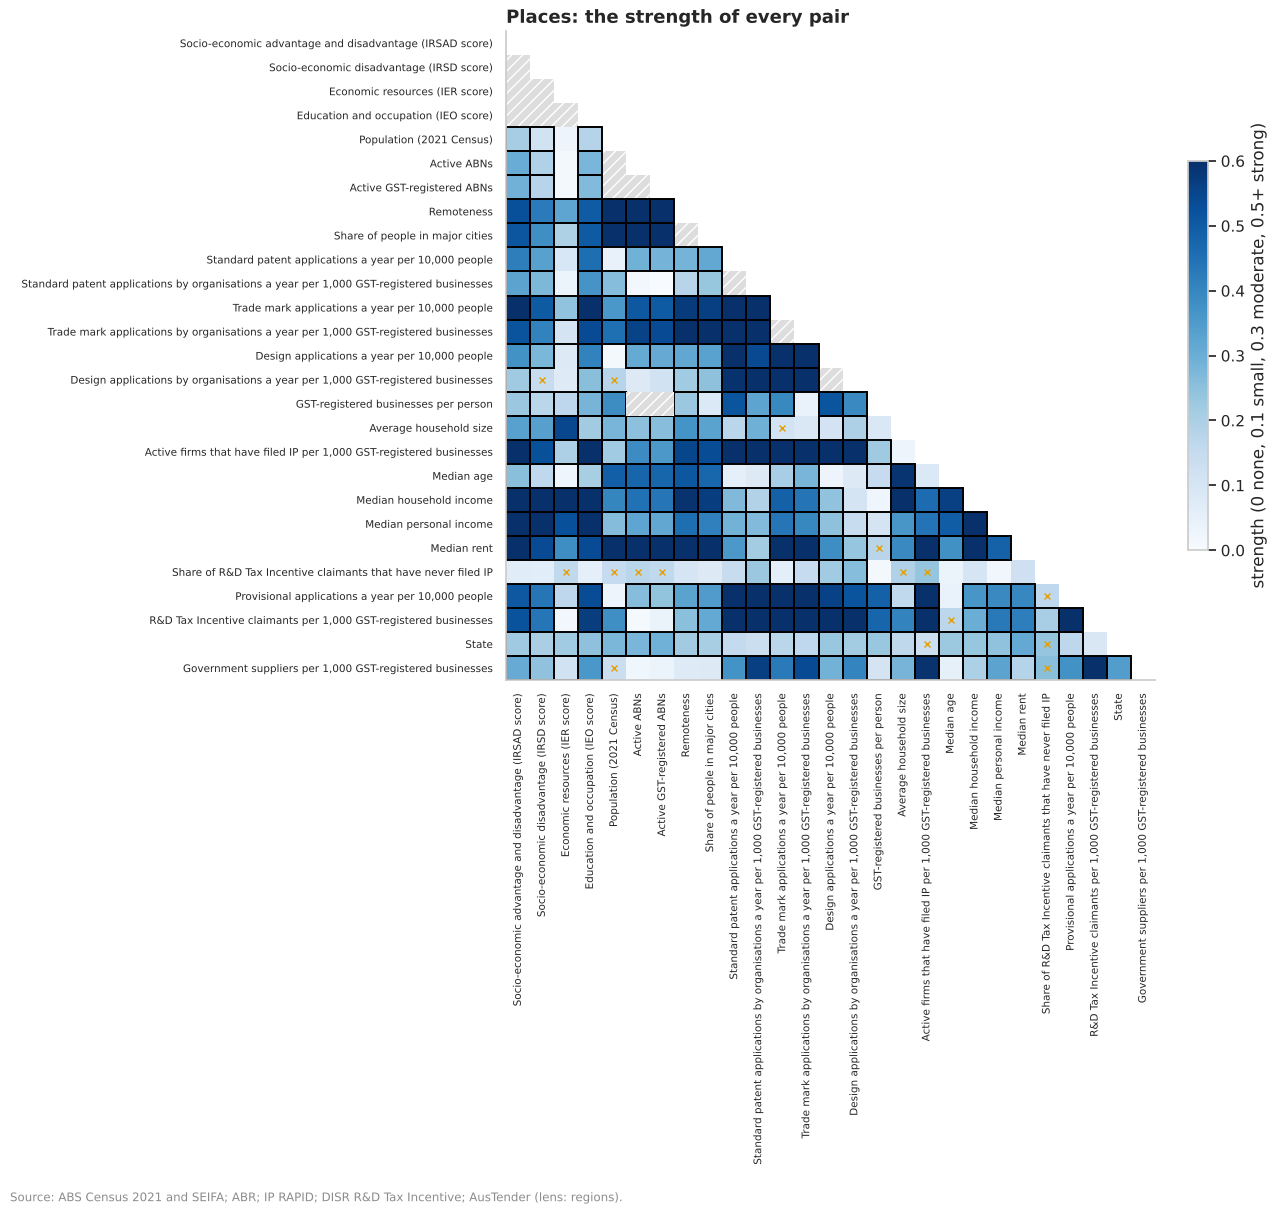

In [34]:
REGION_GROUPS = bi.screens()["regions"]["groups"]


def glab(c):
    return bi.screen_label("regions", c)


regions_screen = bi.run_screen("regions")
regions_leads = bi.distinct_leads(regions_screen["verdicts"], REGION_GROUPS)
display(
    bi.verdict_counts(regions_screen["verdicts"]).to_frame("pairs").T.assign(**{"distinct leads": len(regions_leads)})
)
print("Areas in each half:", regions_screen["n"])
m = regions_screen["verdicts"]
measured = m.dropna(subset=["strength"])
cols = set(measured["variable 1"]) | set(measured["variable 2"])
order = list(dict.fromkeys([c for g in REGION_GROUPS.values() for c in g if c in cols] + sorted(cols)))
fig = bi.strength_map(m, order, label=glab, title="Places: the strength of every pair")
style.source(fig, "ABS Census 2021 and SEIFA; ABR; IP RAPID; DISR R&D Tax Incentive; AusTender (lens: regions).")
ok = m.dropna(subset=["strength", "strength (replication)"])
ok = ok[~ok["by construction"]]
print(
    "Agreement between the halves' strengths (Spearman):",
    round(ok.strength.corr(ok["strength (replication)"], method="spearman"), 3),
)
IP_RATES = [
    "patents_standard_per_10k_people",
    "trade_marks_per_10k_people",
    "designs_per_10k_people",
    "provisionals_per_10k_people",
    "patents_standard_per_1k_businesses",
    "trade_marks_per_1k_businesses",
    "designs_per_1k_businesses",
    "ip_firms_per_1k_businesses",
    "rdti_firms_per_1k_businesses",
    "missing_filer_share",
]
ip_leads = regions_leads[regions_leads["variable 1"].isin(IP_RATES) | regions_leads["variable 2"].isin(IP_RATES)]
print(f"Distinct leads that involve an IP or R&D measure: {len(ip_leads)} of {len(regions_leads)}")
region_lead_table = bi.leads_table(ip_leads, regions_screen["prepared"], regions_screen["discovery"], label=glab)
with pd.option_context("display.max_rows", 120, "display.width", 250):
    display(region_lead_table.assign(rho=ip_leads.rho.round(3).to_numpy()).round(3))

#### Observations
**B27 (observational). The places lens: 124 distinct leads, 75 of them about IP or R&D; the IP measures move together,
and with education and occupation more than income.** Postal areas in two halves (1,377 and 1,264); 269 pairs are
leads, 16 hold in one half only, and the halves agree with a Spearman rho of 0.961.
- **The kinds of IP go together across places:** standard patents and provisionals per person (rho 0.765; 0.779 in
  the other half), standard patents and trade marks (0.693; 0.718), trade marks and designs (0.688; 0.706). Firms
  that have filed IP and R&D claimants, per business, are the strongest pair (0.884; 0.909).
- **Of the four SEIFA indexes, education and occupation (IEO) goes with filing most:** with IP-filing firms per
  business 0.665 (0.674), trade marks per person 0.64 (0.679), R&D claimants 0.568 (0.599), provisionals 0.534
  (0.579), standard patents 0.455 (0.476) and designs 0.409 (0.415). Median personal income, by comparison, goes
  with standard patents at 0.287 (0.364).
- **Business density:** areas with more GST-registered businesses per person file more standard patents (0.513;
  0.626).
- **Missing filers are rarer where filing is common:** the share of R&D claimants that have never filed IP falls with
  designs (rho -0.259; strength 0.224 in the other half, in the same direction) and standard patents (-0.229; 0.192)
  per business.
- Every rate is shown only where 10 or more applications are expected (U53), so these pairs cover the larger areas
  (431 areas for standard patents per person in the discovery half), and they are between places, not firms.

### 3.1 The attachments: every indicator against the IP rates

The `region_indicators` table holds 6,406 indicators from five sources (the Census, Data by Region, CABEE, PHIDU and
the Clean Energy Regulator). Screening every one against every other would give tens of millions of pairs between, for
example, two Census cells, which serve none of the questions (ADR 0030); so each indicator is screened against the
lens's IP and R&D rates instead. Each indicator is taken in one period (the one covering the most areas, the latest if
tied); a count is turned into a rate per 1,000 residents (a share of the whole population, as U57 asks); levels
(medians, percentages, rates) are used as they are. The measure is Spearman's rho across postal areas, in each half,
with the false discovery rate controlled over every indicator and rate together.

In [35]:
import warnings

from scipy import stats

SCREEN_RATES = [
    "patents_standard_per_10k_people",
    "trade_marks_per_10k_people",
    "designs_per_10k_people",
    "provisionals_per_10k_people",
    "ip_firms_per_1k_businesses",
    "rdti_firms_per_1k_businesses",
]
rates = {p: bi.screen_sample("regions", p, keyed=True)[SCREEN_RATES] for p in ("discovery", "replication")}
# each indicator in one period: the one covering the most areas, the latest if tied
BEST = """
    WITH c AS (SELECT source, indicator, period, count(*) AS areas FROM {lens/region_indicators} GROUP BY ALL),
    best AS (SELECT source, indicator, arg_max(period, areas * 1000000 + k) AS period
             FROM (SELECT *, rank() OVER (PARTITION BY source, indicator ORDER BY period) AS k FROM c) GROUP BY ALL)
"""
ind_meta = sql(
    BEST
    + """
    SELECT b.source, b.indicator, b.period, any_value(r.topic) AS topic, any_value(r.label) AS label
    FROM best b JOIN {lens/region_indicators} r USING (source, indicator, period) GROUP BY ALL
"""
)
print(f"Indicators: {len(ind_meta):,}; by source:", ind_meta.source.value_counts().to_dict())
warnings.filterwarnings("ignore", message="An input array is constant")  # indicators that are 0 in every area
results = []
for source in sorted(ind_meta.source.unique()):
    long = sql(
        BEST
        + f"""
        SELECT r.poa_code, r.indicator,
               CASE WHEN r.additive THEN 1000 * r.value / g.persons ELSE r.value END AS value
        FROM {{lens/region_indicators}} r JOIN best b USING (source, indicator, period)
             JOIN {{lens/regions}} g USING (poa_code)
        WHERE r.source = '{source}' AND g.persons >= 100
    """,
        max_rows=None,
    )
    wide = long.pivot(index="poa_code", columns="indicator", values="value")
    for half, r in rates.items():
        w = wide.reindex(r.index)
        for rate in SCREEN_RATES:
            y = r[rate]
            ok = y.notna()
            rho = w[ok].corrwith(y[ok], method="spearman")
            n = w[ok].notna().sum()
            results.append(
                pd.DataFrame(
                    {
                        "source": source,
                        "indicator": rho.index,
                        "rate": rate,
                        "half": half,
                        "rho": rho.to_numpy(),
                        "n": n.reindex(rho.index).to_numpy(),
                    }
                )
            )
res = pd.concat(results, ignore_index=True)
res = res[res.n >= 30]
t = res.rho * np.sqrt((res.n - 2) / (1 - res.rho.clip(-0.999999, 0.999999) ** 2))
res["p"] = 2 * stats.t.sf(t.abs(), res.n - 2)
wide_res = res.pivot_table(index=["source", "indicator", "rate"], columns="half", values=["rho", "p", "n"])
wide_res.columns = [f"{a} ({b})" for a, b in wide_res.columns]
wide_res = wide_res.dropna(subset=["rho (discovery)"]).reset_index()
wide_res["q (discovery)"] = bi.fdr(wide_res["p (discovery)"])
forward = (wide_res["rho (discovery)"].abs() >= 0.1) & (wide_res["q (discovery)"] < 0.05)
wide_res["q (replication)"] = np.nan
wide_res.loc[forward, "q (replication)"] = bi.fdr(wide_res.loc[forward, "p (replication)"])
wide_res["lead"] = (
    forward
    & (wide_res["rho (replication)"].abs() >= 0.1)
    & (wide_res["q (replication)"] < 0.05)
    & (np.sign(wide_res["rho (discovery)"]) == np.sign(wide_res["rho (replication)"]))
)
wide_res = wide_res.merge(ind_meta, on=["source", "indicator"], how="left")
print(
    f"Indicator x rate pairs measured: {len(wide_res):,}; passed in discovery: {forward.sum():,};",
    f"leads: {wide_res.lead.sum():,}",
)
display(
    wide_res.groupby(["source", "rate"])
    .lead.mean()
    .mul(100)
    .round(1)
    .unstack("rate")
    .rename(columns=glab)
    .rename_axis(columns="share of indicators that are leads (%)")
)

Indicators: 6,406; by source: {'census': 2993, 'phidu': 2368, 'data_by_region': 774, 'cabee': 260, 'cer': 11}


Indicator x rate pairs measured: 38,217; passed in discovery: 27,492; leads: 24,792


share of indicators that are leads (%),"Design applications a year per 10,000 people","Active firms that have filed IP per 1,000 GST-registered businesses","Standard patent applications a year per 10,000 people","Provisional applications a year per 10,000 people","R&D Tax Incentive claimants per 1,000 GST-registered businesses","Trade mark applications a year per 10,000 people"
source,,,,,,
cabee,76.9,81.5,77.3,73.8,72.7,85.4
census,47.5,64.5,50.7,57,46.9,68.6
cer,28.6,14.3,28.6,0,100,0
data_by_region,65.8,81.3,66.5,72.3,61.2,83.6
phidu,66.4,80.7,70.3,75,60.2,82.8


In [36]:
# The strongest leads with standard patents and with trade marks per person, both ways, with their topic
for rate in ("patents_standard_per_10k_people", "trade_marks_per_10k_people"):
    d = wide_res[(wide_res.rate == rate) & wide_res.lead].copy()
    d["abs"] = d["rho (discovery)"].abs()
    cols = ["source", "topic", "label", "period", "rho (discovery)", "rho (replication)", "n (discovery)"]
    print(f"\n{glab(rate)}: {len(d):,} leads; strongest positive and negative")
    with pd.option_context("display.max_colwidth", 70, "display.width", 250):
        display(pd.concat([d.nlargest(12, "rho (discovery)"), d.nsmallest(8, "rho (discovery)")])[cols].round(3))


Standard patent applications a year per 10,000 people: 3,881 leads; strongest positive and negative


,source,topic,label,period,rho (discovery),rho (replication),n (discovery)
1148,cabee,Businesses by industry division and turnover size,"Businesses: Financial and Insurance Services, $200k to less than $2m",June 2025,0.595,0.621,431
1238,cabee,Businesses by industry division and turnover size,"Businesses: Professional, Scientific and Technical Services, $2m t...",June 2025,0.593,0.635,431
19765,data_by_region,Number of businesses,Number of businesses:Financial and insurance services industry (no.),2024,0.581,0.639,431
1190,cabee,Businesses by industry division and turnover size,"Businesses: Rental, Hiring and Real Estate Services, $200k to less...",June 2025,0.58,0.639,431
392,cabee,Businesses by industry division and employment size,"Businesses: Financial and Insurance Services, Total",June 2025,0.575,0.638,431
1172,cabee,Businesses by industry division and turnover size,"Businesses: Financial and Insurance Services, Total",June 2025,0.575,0.636,431
464,cabee,Businesses by industry division and employment size,"Businesses: Professional, Scientific and Technical Services, Total",June 2025,0.573,0.614,431
19813,data_by_region,Number of businesses,"Number of businesses:Professional, scientific and technical servic...",2025,0.573,0.614,431
1256,cabee,Businesses by industry division and turnover size,"Businesses: Professional, Scientific and Technical Services, Total",June 2025,0.573,0.614,431
428,cabee,Businesses by industry division and employment size,"Businesses: Rental, Hiring and Real Estate Services, Total",June 2025,0.572,0.64,431



Trade mark applications a year per 10,000 people: 4,865 leads; strongest positive and negative


,source,topic,label,period,rho (discovery),rho (replication),n (discovery)
467,cabee,Businesses by industry division and employment size,"Businesses: Professional, Scientific and Technical Services, Total",June 2025,0.72,0.788,"1,074"
1259,cabee,Businesses by industry division and turnover size,"Businesses: Professional, Scientific and Technical Services, Total",June 2025,0.72,0.788,"1,074"
19816,data_by_region,Number of businesses,"Number of businesses:Professional, scientific and technical servic...",2025,0.72,0.788,"1,073"
1235,cabee,Businesses by industry division and turnover size,"Businesses: Professional, Scientific and Technical Services, $200k...",June 2025,0.703,0.765,"1,074"
461,cabee,Businesses by industry division and employment size,"Businesses: Professional, Scientific and Technical Services, Non e...",June 2025,0.702,0.771,"1,074"
2045,census,G01: Selected person characteristics,Highest_year_of_school_completed_Year_12_or_equivalent_Persons,2021,0.697,0.748,"1,074"
8620,census,"G43: Selected labour force, education and migration characteristics",Highest_non_school_qualifications_Bachelor_Degree_Level_Males,2021,0.694,0.74,"1,074"
21574,data_by_region,Median price of established house transfers ($),Median price of established house transfers ($),2021,0.689,0.745,"1,068"
2033,census,G01: Selected person characteristics,Highest_year_of_school_completed_Year_12_or_equivalent_Females,2021,0.688,0.739,"1,074"
2039,census,G01: Selected person characteristics,Highest_year_of_school_completed_Year_12_or_equivalent_Males,2021,0.687,0.738,"1,074"


#### Observations
**B28 (observational). Most attached indicators go with filing, along one broad gradient of advantage, education
and business density; no single indicator stands out from it.**
- 6,406 indicators (2,993 from the Census, 2,368 from PHIDU, 774 from Data by Region, 260 from CABEE and 11 from the
  Clean Energy Regulator), against six rates: 38,217 pairs measured, 27,492 past the size threshold and the
  correction in the discovery half, and 24,792 leads in both halves.
- **Standard patents per person:** 3,881 leads. Most positive: financial and insurance businesses per resident (CABEE,
  0.575; 0.638), professional, scientific and technical businesses (0.573; 0.614) and those with a turnover of $2m or
  more (0.593; 0.635). Most negative: single mothers receiving Parenting Payment (PHIDU, -0.482; -0.473), children
  whose mothers have low educational attainment (-0.477; -0.477) and women with a high-risk waist measurement (-0.473; -0.489).
- **Trade marks per person:** 4,865 leads. Most positive: professional, scientific and technical businesses per
  resident (0.72; 0.788), Year 12 completion (Census, 0.697; 0.748), bachelor degrees (0.685; 0.73) and house prices
  (Data by Region, 0.689; 0.745). Most negative: mothers with obesity (-0.61; -0.697), Year 9 as the highest year of
  school (-0.598; -0.632) and land area (-0.594; -0.638).
- **So** the attachments describe one dimension of places (urban, educated, professional, business-dense, healthier)
  more than many separate signals. Stage 3 reduces them to a few components (`multi.pca`) before any is read as a
  driver. The Clean Energy Regulator's installations are the exception: 0 of its 11 indicators are leads with trade
  marks.

### 3.2 Filing rates against advantage and remoteness, with room for spread

**From:** U51, U53. **Informs:** Q2. Areas' counts over ten years, modelled as a negative binomial (which allows areas
to differ more than chance would, as U53 found) with the area's residents as the exposure: the result is a **rate
ratio**, how many times higher an area's filing rate is for each step up the advantage scale. Fitted in each half of
the areas, and again on areas pooled into SA3s. Areas with fewer than 100 residents are left out.

In [37]:
import warnings

import statsmodels.api as sm
import statsmodels.formula.api as smf

areas = sql("""
    SELECT poa_code, sa3_code, persons, irsad_score, irsad_decile, ieo_score, remoteness, patents_standard,
           trade_marks, designs, patents_provisional, active_gst_abns,
           CASE WHEN hash(CAST(poa_code AS VARCHAR) || 'stage2') % 2 = 0 THEN 'discovery' ELSE 'replication' END AS half
    FROM {lens/regions} WHERE persons >= 100 AND irsad_score IS NOT NULL
""")
areas["z_irsad"] = (areas.irsad_score - areas.irsad_score.mean()) / areas.irsad_score.std()
areas["log_exposure"] = np.log(areas.persons * 10)


def nb_ratio(d, count, term="z_irsad", formula=None):
    # the rate ratio for one standard deviation of IRSAD (or each remoteness class against major cities), with its
    # 95% interval, from a negative binomial model with the area's residents (times 10 years) as exposure; started
    # from a Poisson fit's coefficients, which the negative binomial needs to converge here
    f = formula or f"{count} ~ {term}"
    pois = smf.glm(f, d, family=sm.families.Poisson(), offset=d.log_exposure).fit()
    model = smf.negativebinomial(f, d, offset=d.log_exposure)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = model.fit(start_params=np.r_[pois.params.to_numpy(), 1.0], method="bfgs", maxiter=2000, disp=0)
        fit = model.fit(start_params=fit.params.to_numpy(), method="newton", maxiter=200, disp=0)
    ci = np.exp(fit.conf_int())
    return (
        pd.DataFrame({"rate ratio": np.exp(fit.params), "low": ci[0], "high": ci[1]})
        .drop(index=["Intercept", "alpha"], errors="ignore")
        .assign(alpha=fit.params["alpha"], areas=int(fit.nobs), converged=fit.mle_retvals["converged"])
    )


rows = []
for count in ("patents_standard", "trade_marks", "designs", "patents_provisional"):
    for half, d in areas.groupby("half"):
        rows.append(nb_ratio(d, count).assign(measure=count, sample=half, model="IRSAD"))
        rows.append(
            nb_ratio(d, count, formula=f"{count} ~ C(remoteness, Treatment('Major Cities of Australia'))").assign(
                measure=count, sample=half, model="remoteness"
            )
        )
        rows.append(
            nb_ratio(
                d, count, formula=f"{count} ~ z_irsad + C(remoteness, Treatment('Major Cities of Australia'))"
            ).assign(measure=count, sample=half, model="IRSAD and remoteness together")
        )
    # pooled into SA3s: sums of counts and residents, and the residents-weighted IRSAD score
    sa3 = (
        areas.assign(w=areas.irsad_score * areas.persons)
        .groupby("sa3_code")
        .agg(**{count: (count, "sum")}, persons=("persons", "sum"), w=("w", "sum"))
    )
    sa3["irsad"] = sa3.w / sa3.persons
    sa3["z_irsad"] = (sa3.irsad - areas.irsad_score.mean()) / areas.irsad_score.std()
    sa3["log_exposure"] = np.log(sa3.persons * 10)
    rows.append(nb_ratio(sa3, count).assign(measure=count, sample="SA3s", model="IRSAD"))
nb = pd.concat(rows).rename_axis("term").reset_index()
nb["term"] = nb.term.str.replace(
    r"C\(remoteness, Treatment\('Major Cities of Australia'\)\)\[T\.", "", regex=True
).str.rstrip("]")
print("All fits converged:", bool(nb.converged.all()))
nb.set_index(["measure", "model", "term", "sample"])[["rate ratio", "low", "high", "alpha", "areas"]].round(3).unstack(
    "sample"
)

All fits converged: True


rate ratio                         low                        high            \
sample                                                                           SA3s discovery replication  SA3s discovery replication  SA3s discovery   
measure             model                         term                                                                                                    
designs             IRSAD                         z_irsad                       1.672     1.504       1.639 1.505     1.385       1.495 1.857     1.634   
                    IRSAD and remoteness together Inner Regional Australia        NaN     0.284       0.287   NaN     0.226       0.224   NaN     0.358   
                                                  Outer Regional Australia        NaN     0.283       0.194   NaN     0.213        0.14   NaN     0.378   
                                                  Remote Australia                NaN     0.236       0.326   NaN     0.122       0.194   NaN     0.458   
                                                  Very Remote Australia           NaN     0.045       0.081   NaN     0.012       0.033   NaN     0.164   
                                                  z_irsad                         NaN     1.199       1.266   NaN     1.092       1.142   NaN     1.318   
                    remoteness                    Inner Regional Australia        NaN     0.243        0.24   NaN     0.195       0.189   NaN     0.302   
                                                  Outer Regional Australia        NaN     0.224       0.146   NaN     0.172       0.108   NaN     0.292   
                                                  Remote Australia                NaN     0.192       0.261   NaN       0.1       0.157   NaN     0.369   
                                                  Very Remote Australia           NaN     0.032       0.055   NaN     0.009       0.022   NaN     0.118   
patents_provisional IRSAD                         z_irsad                       1.771     1.582       1.823 1.652     1.486        1.71 1.899     1.683   
                    IRSAD and remoteness together Inner Regional Australia        NaN     0.534       0.583   NaN     0.449       0.484   NaN     0.636   
                                                  Outer Regional Australia        NaN       0.7       0.448   NaN     0.569        0.36   NaN     0.861   
                                                  Remote Australia                NaN     0.583       0.463   NaN     0.383       0.315   NaN     0.889   
                                                  Very Remote Australia           NaN     0.357       0.195   NaN      0.21       0.112   NaN     0.607   
                                                  z_irsad                         NaN     1.412       1.535   NaN     1.311       1.422   NaN     1.519   
                    remoteness                    Inner Regional Australia        NaN     0.374       0.367   NaN     0.317       0.307   NaN     0.443   
                                                  Outer Regional Australia        NaN     0.425       0.238   NaN     0.352       0.194   NaN     0.514   
                                                  Remote Australia                NaN     0.353       0.268   NaN     0.232       0.181   NaN     0.537   
                                                  Very Remote Australia           NaN     0.206       0.088   NaN     0.121       0.051   NaN     0.352   
patents_standard    IRSAD                         z_irsad                       1.884     1.717       1.857 1.728     1.597       1.717 2.055     1.845   
                    IRSAD and remoteness together Inner Regional Australia        NaN     0.382        0.38   NaN     0.312       0.301   NaN     0.468   
                                                  Outer Regional Australia        NaN     0.482       0.352   NaN     0.377       0.266   NaN     0.615   
                                             

patents_standard             trade_marks               designs            
half                discovery replication   discovery replication discovery replication
irsad_decile                                                                           
1                        0.33        0.45        7.63        6.62      0.43        0.33
2                        0.38        0.43        9.51        8.84       0.7        0.59
3                        0.47        0.37        8.87        8.43      0.49        0.43
4                        0.42        0.53        8.96       11.08      0.54        0.54
5                        0.65        0.44       10.41       10.38      0.57        0.48
6                         0.5        0.59       12.04       12.33      0.46        0.89
7                        0.75        0.62        15.3       12.87      0.78        0.61
8                        0.72        0.93       19.37       20.06       0.8         0.9
9                        1.51        1.48        31.6       24.84      1.54        1.29
10                       1.62        3.37       29.24       52.18      1.21        2.48

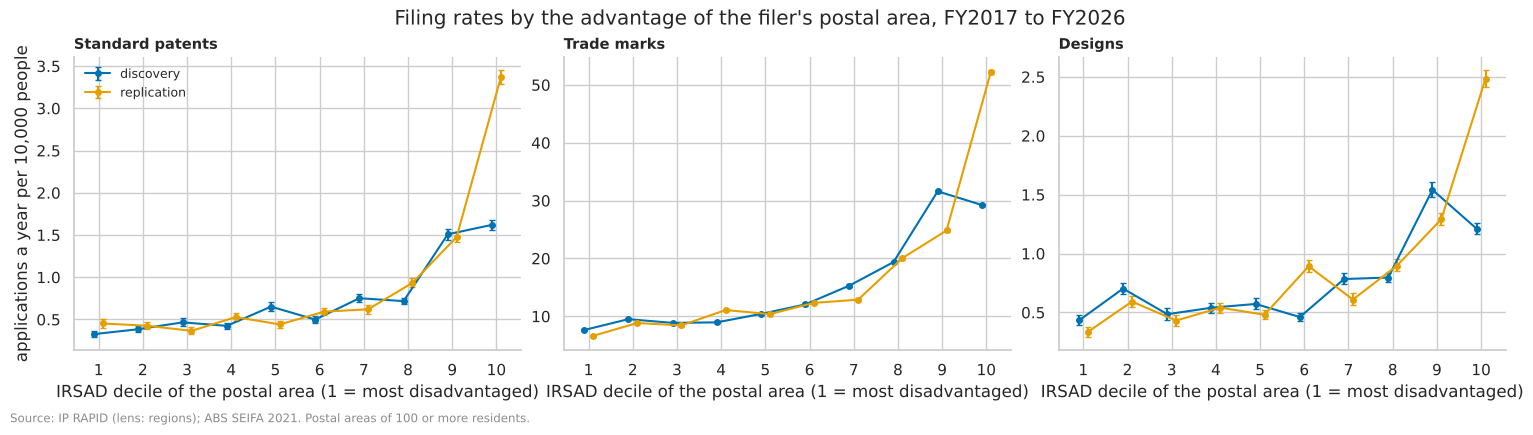

In [38]:
# The gradient as rates by IRSAD decile (pooled: the decile's applications over its residents, a year per 10,000
# people), with Poisson intervals, in each half
dec = areas.groupby(["irsad_decile", "half"])[["patents_standard", "trade_marks", "designs", "persons"]].sum()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (count, name) in zip(
    axes,
    (("patents_standard", "Standard patents"), ("trade_marks", "Trade marks"), ("designs", "Designs")),
    strict=True,
):
    for i, half in enumerate(("discovery", "replication")):
        d = dec.xs(half, level="half")
        lo, hi = uni.poisson_interval(d[count])
        k = 1000 / d.persons
        ax.errorbar(
            d.index + (i - 0.5) * 0.2,
            d[count] * k,
            yerr=[(d[count] - lo) * k, (hi - d[count]) * k],
            fmt="o-",
            color=style.PALETTE[i],
            ms=4,
            capsize=2,
            label=half,
        )
    ax.set_title(name, fontsize=10.5)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("IRSAD decile of the postal area (1 = most disadvantaged)")
axes[0].set_ylabel("applications a year per 10,000 people")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Filing rates by the advantage of the filer's postal area, FY2017 to FY2026")
style.source(fig, "IP RAPID (lens: regions); ABS SEIFA 2021. Postal areas of 100 or more residents.")
(1000 * dec[["patents_standard", "trade_marks", "designs"]].div(dec.persons, axis=0)).round(2).unstack("half")

#### Observations
**B29 (observational). Filing rises steeply with advantage and falls with remoteness; both hold when read together,
in both halves and pooled into SA3s.** Negative binomial rate ratios, per standard deviation of the IRSAD score
(discovery; replication; SA3s):
- **Standard patents:** 1.717 (1.597 to 1.845); 1.857 (1.717 to 2.008); 1.884 (1.728 to 2.055). **Trade marks:** 1.648;
  1.707; 1.477. **Designs:** 1.504; 1.639; 1.672. **Provisionals:** 1.582; 1.823; 1.771.
- **Remoteness, against major cities** (standard patents): inner regional areas file at 0.259 (0.252) of the cities'
  rate, very remote areas at 0.173 (0.06); trade marks 0.369 (0.338) and 0.201 (0.158).
- **Together:** with remoteness in the model, the IRSAD ratio for standard patents falls to 1.442 (1.326 to 1.567) and
  1.49 (1.357 to 1.635), and inner regional areas still file at 0.382 (0.38) of the cities' rate at the same
  advantage; trade marks 1.392 and 1.406, designs 1.199 and 1.266. Each accounts for part of the other, and both stay.
- **The shape is not a straight line:** pooled rates of standard patents are 0.33 to 0.75 a year per 10,000 people
  across deciles 1 to 8 (0.37 to 0.93 in the other half), then 1.51 to 1.62 in deciles 9 and 10 (1.48 to 3.37). Most
  of the gradient is in the most advantaged fifth of areas; trade marks rise more steadily (7.63 to 29.24; 6.62 to
  52.18). The top decile differs most between the halves (1.62 against 3.37 for standard patents) because a few
  city-centre postcodes with many filers and few residents (Sydney's 2000, U53) fall in one half: pooled rates there
  are fragile, and the model's ratio is the steadier reading.
- The spread is large (alpha 1.354 and 1.65 for standard patents), as U53 found, which is why a negative binomial is
  used. Candidate third factors: business density and mix (3.4), education (B28), and where firms register (U47).

### 3.3 Is the gradient one firm's? Area counts beside the firms behind them

**From:** U52. **Informs:** Q2. In many areas one firm files most of the patents (Aristocrat in 2113, CSIRO in 2601).
The model of 3.2 is fitted again on standard patents with each area's largest filer taken out (a filer is its ABN;
filings with no ABN count as separate filers, so the largest filer is understated where ABNs are missing).

In [39]:
top = sql("""
    WITH f AS (
        SELECT founder_postcode AS poa_code, coalesce(filer_abn, application_number) AS filer, count(*) AS n
        FROM {lens/rights}
        WHERE patent_type = 'standard' AND filing_fy BETWEEN 2017 AND 2026 AND founding_australian
          AND founder_postcode IS NOT NULL
        GROUP BY ALL)
    SELECT poa_code, sum(n) AS total, max(n) AS largest FROM f GROUP BY 1
""")
a2 = areas.merge(top, on="poa_code", how="left").fillna({"total": 0, "largest": 0})
a2["without_largest"] = (a2.total - a2.largest).astype(int)
a2["total"] = a2.total.astype(int)
print(
    "Areas:",
    len(a2),
    "; their patents:",
    int(a2.total.sum()),
    "; held by each area's largest filer:",
    f"{100 * a2.largest.sum() / a2.total.sum():.1f}%",
)
rows = []
for half, d in a2.groupby("half"):
    for count in ("total", "without_largest"):
        rows.append(nb_ratio(d, count).assign(measure=count, sample=half))
pd.concat(rows).set_index(["measure", "sample"])[["rate ratio", "low", "high", "areas", "converged"]].round(3)

Areas: 2528 ; their patents: 24879 ; held by each area's largest filer: 29.2%


,,rate ratio,low,high,areas,converged
measure,sample,,,,,
total,discovery,1.717,1.597,1.845,1317,True
without_largest,discovery,1.897,1.74,2.067,1317,True
total,replication,1.857,1.717,2.008,1211,True
without_largest,replication,1.961,1.794,2.143,1211,True


#### Observations
**B30 (observational). The advantage gradient is not one firm's: it is as strong with each area's largest filer
taken out.** Each area's largest filer holds 29.2% of the 24,879 Australian standard patents placed in 2,528 areas.
Without it, the rate ratio per standard deviation of IRSAD is 1.897 (1.74 to 2.067) against 1.717 with it, and 1.961
(1.794 to 2.143) against 1.857 in the other half. Single large filers (U52) add noise to areas' counts, not the
gradient.

### 3.4 Business mix: which industries' businesses an area holds, against its filing

**From:** U56, U59. **Informs:** Q2. CABEE's businesses by ANZSIC division (June 2025, by employment size, all sizes),
as shares of the area's businesses, against the area's applications by organisations per 1,000 businesses, in each
half. Areas with 100 or more businesses.

In [40]:
mix = sql("""
    SELECT poa_code, split_part(indicator, '|', 2) AS division, any_value(label) AS label, sum(value) AS businesses
    FROM {lens/region_indicators}
    WHERE source = 'cabee' AND period = 'June 2025' AND indicator LIKE 'employment|%|Total'
      AND split_part(indicator, '|', 2) <> 'X'
    GROUP BY ALL
""")
names = mix.groupby("division").label.first().str.replace("Businesses: ", "").str.replace(", Total", "")
share = mix.pivot(index="poa_code", columns="division", values="businesses")
tot = share.sum(axis=1)
share = share[tot >= 100].div(tot[tot >= 100], axis=0)
out = {}
for half in ("discovery", "replication"):
    frame = bi.screen_sample("regions", half, keyed=True)
    for rate in ("patents_standard_per_1k_businesses", "trade_marks_per_1k_businesses"):
        y = frame[rate].dropna()
        s = share.reindex(y.index).dropna(how="all")
        out[(rate, half)] = s.corrwith(y.reindex(s.index), method="spearman")
mixr = pd.DataFrame(out).rename(index=names)
mixr.columns = [f"{glab(a)[:40]}... ({b})" for a, b in mixr.columns]
mixr.sort_values(mixr.columns[0]).round(3)

,Standard patent applications by organisa... (discovery),Trade mark applications by organisations... (discovery),Standard patent applications by organisa... (replication),Trade mark applications by organisations... (replication)
division,,,,
"Transport, Postal and Warehousing",-0.397,-0.015,-0.302,-0.07
Construction,-0.373,0.025,-0.382,0.051
Administrative and Support Services,-0.276,0.335,-0.201,0.373
Public Administration and Safety,-0.238,0.226,-0.097,0.233
Other Services,-0.161,0.006,-0.237,-0.034
"Agriculture, Forestry and Fishing",-0.055,-0.622,-0.083,-0.655
Accommodation and Food Services,-0.05,0.215,0.043,0.257
"Electricity, Gas, Water and Waste Services",-0.025,0.018,0.029,-0.051
Mining,0.106,-0.156,0.163,-0.116


#### Observations
**B31 (observational). Where more of an area's businesses are in finance, property and professional services, it
files more per business; where more are in construction and transport, less; manufacturing's share makes no
difference.** Spearman's rho across areas, discovery half (replication):
- **Standard patents by organisations per 1,000 businesses:** financial and insurance services 0.441 (0.38), rental,
  hiring and real estate 0.439 (0.375), professional, scientific and technical services 0.378 (0.361), wholesale
  trade 0.335 (0.336), information media 0.324 (0.319); construction -0.373 (-0.382), transport -0.397 (-0.302).
  Manufacturing 0.119 (-0.021): no consistent link.
- **Trade marks per 1,000 businesses:** financial services 0.66 (0.696), professional services 0.649 (0.71),
  information media 0.551 (0.611), health care 0.556 (0.525), education 0.54 (0.573); agriculture -0.622 (-0.655).
- Patents are filed by manufacturers (U75), so manufacturing's flat link says that patenting places are not
  manufacturing places: a firm's head office, where its ABN is registered (U47), sits among the services of the city
  centres. The business mix of a place is a third factor for B29, and a caution for any regional reading of IP.

### 3.5 Summary of the places lens

| # | Pair | What was found | Strength | Holds in the other half? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B27 | Every pair of the lens | IP measures move together, and with education and occupation (IEO) most | observational | yes (rho 0.961) | Yes: Q2 |
| B28 | 6,406 attached indicators × IP rates | 24,792 of 38,217 pairs are leads, on one gradient of advantage, education and business density | observational | yes | Yes, reduced to components |
| B29 | Advantage and remoteness × filing | 1.7 to 1.9 times per standard deviation of IRSAD; remote areas far lower; both hold together | observational | yes, and in SA3s | Yes: Q2, Q4 |
| B30 | Largest filer × the gradient | The gradient holds without each area's largest filer | observational | yes | Rule: the gradient is not one firm's |
| B31 | Business mix × filing | Finance, property and professional services up; construction and transport down; manufacturing flat | observational | yes | Yes, with U47 |

**Candidate third factors named most often:** business density and mix, education, and where firms register rather
than work. All of these are associations between places.

## 4. Lens: Australia and other countries (one row per country, year and indicator)

**Rules carried from Stage 1:** WIPO by country from 1995, former states never added to their successors (U64);
counts across countries become ratios to people or GDP (U66); projections are left out (U72); a GII rank is context,
its indicators the evidence (U69). Series that trend together over decades correlate whatever their link (ADR 0006),
so pairs are read **across countries within a period**, and over time only as **changes**.

**The two samples:** each indicator averaged over 2016 to 2020 (discovery) and over 2006 to 2010 (replication), for
every country of a million people or more. Counts are per million people; money flows (royalties, high-technology
exports) per person; shares of GDP and the like as they are (`screens.yaml`).

### 4.0 The screen: every pair of indicators across countries

Countries: {'discovery': 160, 'replication': 159}


verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,319,22,40,46,8,0,188


Distinct leads that involve an IP measure or royalties: 134 of 188


,pair,measure,strength,95% interval,replication,size,versions,candidate third factors,rho
0,Patent applications filed worldwide by residents (all offices) × Patent grants receive...,spearman,0.966,0.944 to 0.977,0.976,strong,2,"Patent applications, residents, Business Enterprise Expenditure on R&D (BERD), % of GD...",0.966
1,"Charges for the use of intellectual property, payments (BoP, current U × GDP per capit...",spearman,0.936,0.909 to 0.952,0.917,strong,1,"Charges for the use of intellectual property, receipts (BoP, current U, Patent applica...",0.936
2,"Business Enterprise Expenditure on R&D (BERD), % of GDP (OECD MSTI) × Patent applicati...",spearman,0.93,0.857 to 0.960,0.913,strong,6,"Gross Domestic Expenditure on R&D (GERD), % of GDP (OECD MSTI), Patent grants received...",0.93
3,"Charges for the use of intellectual property, payments (BoP, current U × Charges for t...",spearman,0.921,0.879 to 0.950,0.853,strong,1,"GDP per capita, PPP (constant 2021 international $), Trade mark applications by reside...",0.921
4,"Business Enterprise Expenditure on R&D (BERD), % of GDP (OECD MSTI) × Patent grants re...",spearman,0.917,0.845 to 0.953,0.895,strong,3,"Patent applications filed worldwide by residents (all offices), Gross Domestic Expendi...",0.917
...,...,...,...,...,...,...,...,...,...
129,"Trademark applications, resident, by count × Manufacturing, value added (% of GDP)",spearman,0.221,0.053 to 0.367,0.255,small,2,"High-technology exports (current US$), Technicians in R&D (per million people), Resear...",0.221
130,"Research and development expenditure (% of GDP) × Trademark applications, nonresident,...",spearman,0.218,0.029 to 0.416,0.292,small,1,"GDP per capita, PPP (constant 2021 international $), Trade mark applications by reside...",0.218
131,"Manufacturing, value added (% of GDP) × Patent grants received worldwide by residents ...",spearman,0.217,0.089 to 0.338,0.226,small,1,"High-technology exports (current US$), Technicians in R&D (per million people), Resear...",0.217
132,"Charges for the use of intellectual property, receipts (BoP, current U × Foreign direc...",spearman,0.206,0.042 to 0.389,0.26,small,1,"Gross Domestic Expenditure on R&D (GERD), % of GDP (OECD MSTI), Business Enterprise Ex...",0.206


Patent applications, residents                            Trademark applications, resident, by cou                           
                                                                                            2016-2020 2006-2010          verdict                                2016-2020 2006-2010          verdict
Patent applications filed worldwide by residents (all offices)                                  0.938     0.953  by construction                                     0.84     0.812             lead
Patent grants received worldwide by residents (all offices)                                      0.92     0.941             lead                                     0.81     0.739             lead
Gross Domestic Expenditure on R&D (GERD), % of GDP (OECD MSTI)                                  0.847     0.821             lead                                      0.4     0.318   not replicated
Business Enterprise Expenditure on R&D (BERD), % of GDP (OECD MSTI)                             0.844     0.827             lead                                    0.373     0.292   not replicated
Researchers in R&D (per million people)                                                         0.837     0.896             lead                                    0.701     0.793             lead
Scientific and technical journal articles                                                       0.817     0.798             lead                                    0.784     0.803             lead
Technicians in R&D (per million people)                                                         0.801     0.825             lead                                     0.76     0.838             lead
Research and development expenditure (% of GDP)                                                 0.793     0.799             lead                                    0.643     0.647             lead
Industrial design applications by residents, counted in designs (all o                          0.789     0.765             lead                                    0.771     0.796             lead
Charges for the use of intellectual property, receipts (BoP, current U                          0.782     0.811             lead                                    0.769     0.754             lead
Trade mark applications by residents, counted in classes (all offices)                           0.78     0.681             lead                                    0.958     0.959  by construction
Trademark applications, resident, by count                                                      0.777     0.715             lead                                      NaN       NaN              NaN
GDP per capita, PPP (constant 2021 international $)                                             0.769     0.747             lead                                    0.797     0.868             lead
Charges for the use of intellectual property, payments (BoP, current U                          0.765     0.778             lead                                    0.825     0.809             lead
High-technology exports (current US$)                                                           0.755     0.758             lead                                    0.723      0.75             lead
Industrial design applications, resident, by count                                               0.74     0.752             lead                                    0.737     0.748             lead
School enrollment, tertiary (% gross)                                                           0.726     0.737             lead                                    0.804     0.788             lead
OECD member                                                                                      0.62     0.604             lead                                    0.598     0.656             lead
Industrial design applications, nonresident, by count                                           0.613     0.584             lead   

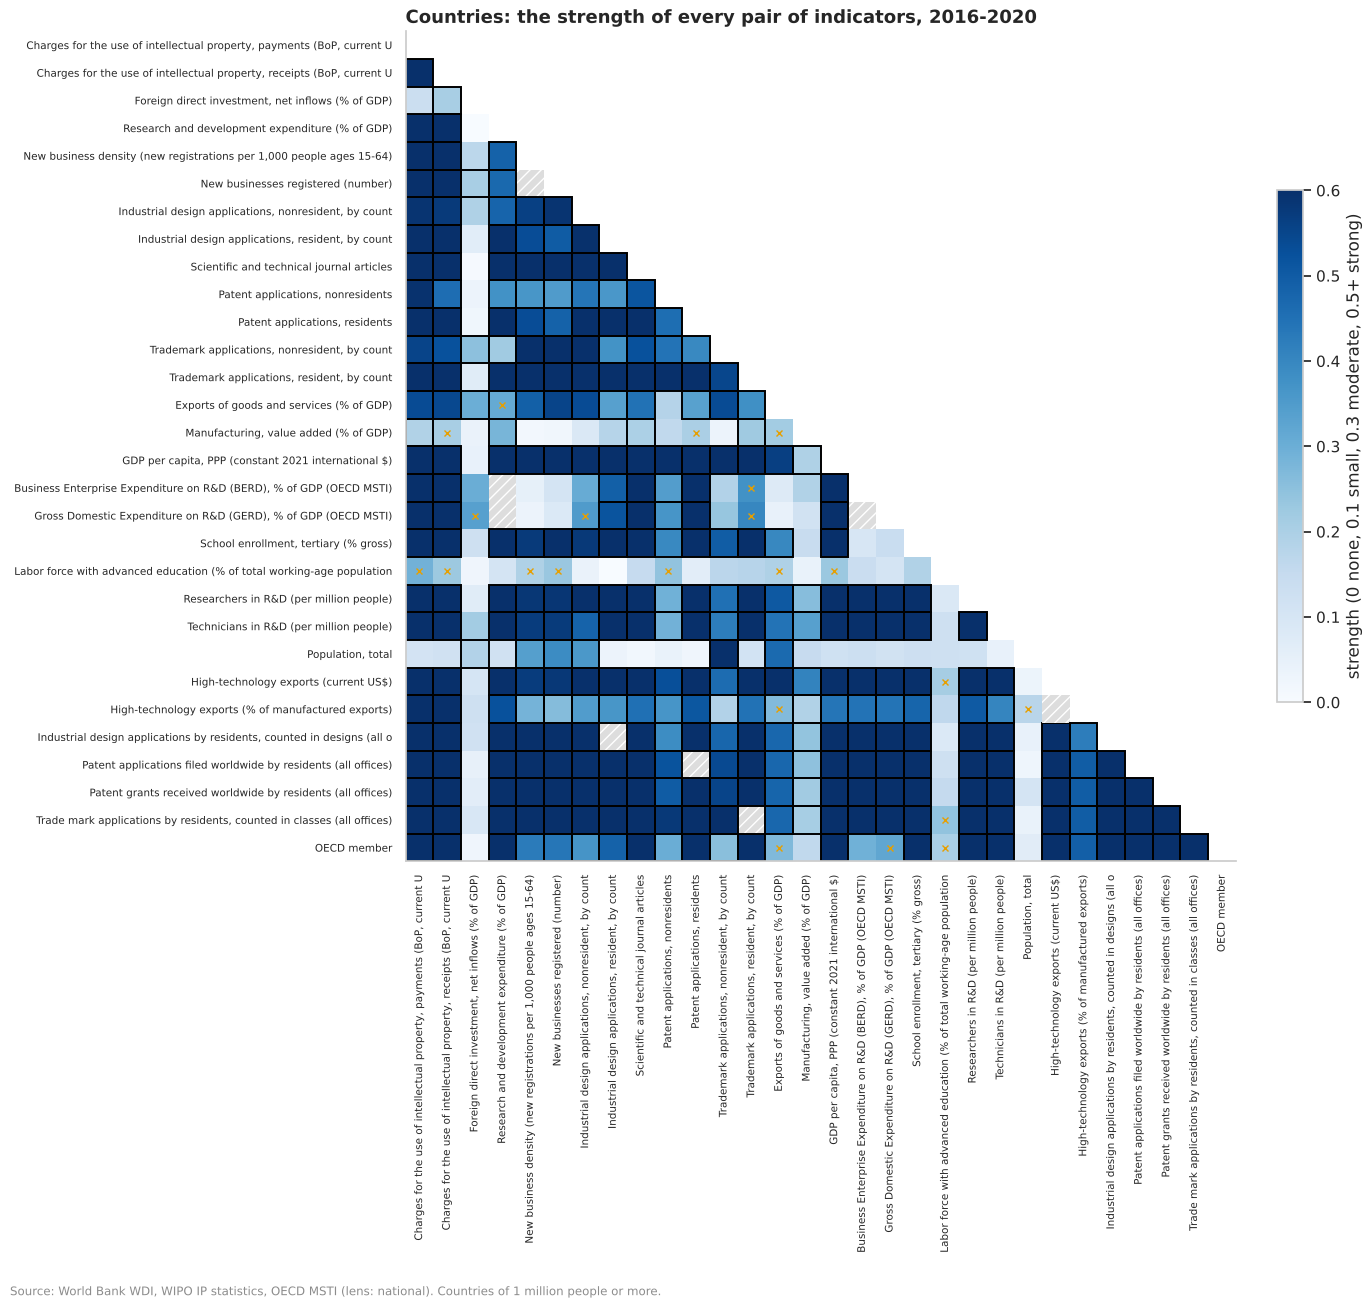

In [41]:
NAT = bi.screens()["national"]
NAT_GROUPS = NAT["groups"]
names = (
    sql("SELECT indicator, any_value(indicator_name) AS name FROM {lens/national} GROUP BY 1")
    .set_index("indicator")
    .name
)


def nlab(c):
    return "OECD member" if c == "oecd" else f"{names.get(c, c)[:70]}"


def national_wide(period):
    # one row per country of a million people or more: each indicator's mean over the period, as a ratio to people
    long = sql(f"""
        WITH v AS (SELECT iso3, indicator, avg(value) AS value FROM {{lens/national}}
                   WHERE entity = 'country' AND {period} AND value IS NOT NULL GROUP BY ALL)
        SELECT v.*, p.value AS people, n.oecd
        FROM v JOIN (SELECT iso3, value FROM v WHERE indicator = 'SP.POP.TOTL') p USING (iso3)
             JOIN (SELECT iso3, bool_or(oecd) AS oecd FROM {{lens/national}} GROUP BY 1) n USING (iso3)
        WHERE p.value >= 1000000
    """)
    how = {k: v for k, v in NAT["indicators"].items() if isinstance(v, str)}
    long = long[long.indicator.isin(how)]
    scale = long.indicator.map(how).map({"per_million_people": 1e6, "per_person": 1.0, "as_is": None})
    long["value"] = np.where(scale.notna(), long.value / long.people * scale.fillna(1), long.value)
    wide = long.pivot(index="iso3", columns="indicator", values="value")
    wide["oecd"] = long.groupby("iso3").oecd.first()
    return wide


nat = {p: national_wide(NAT[p]) for p in ("discovery", "replication")}
nkinds = {c: "number" for c in nat["discovery"].columns if c != "oecd"} | {"oecd": "category"}
nprep = {p: bi.prepare(w, nkinds) for p, w in nat.items()}
nres = {p: bi.screen(nprep[p], groups=NAT_GROUPS, min_n=20) for p in nprep}
nm = bi.replicate(nres["discovery"], nres["replication"])
nat_leads = bi.distinct_leads(nm, NAT_GROUPS)
print("Countries:", {p: len(w) for p, w in nat.items()})
display(bi.verdict_counts(nm).to_frame("pairs").T.assign(**{"distinct leads": len(nat_leads)}))
fig = bi.strength_map(
    nm, list(nkinds), label=nlab, title="Countries: the strength of every pair of indicators, 2016-2020"
)
style.source(
    fig, "World Bank WDI, WIPO IP statistics, OECD MSTI (lens: national). Countries of 1 million people or more."
)
IP_CODES = [
    "IP.PAT.RESD",
    "IP.PAT.NRES",
    "IP.TMK.RSCT",
    "IP.TMK.NRCT",
    "IP.IDS.RSCT",
    "IP.IDS.NRCT",
    "WIPO.PAT.APP",
    "WIPO.PAT.GRANT",
    "WIPO.TM.CLASS",
    "WIPO.DES.COUNT",
    "BM.GSR.ROYL.CD",
    "BX.GSR.ROYL.CD",
]
ip_nat = nat_leads[nat_leads["variable 1"].isin(IP_CODES) | nat_leads["variable 2"].isin(IP_CODES)]
print(f"Distinct leads that involve an IP measure or royalties: {len(ip_nat)} of {len(nat_leads)}")
nat_table = bi.leads_table(ip_nat, nprep["discovery"], nres["discovery"], label=nlab)
with pd.option_context("display.max_rows", 120, "display.width", 250):
    display(nat_table.assign(rho=ip_nat.rho.round(3).to_numpy()).drop(columns="direction").round(3))
# the same screen, read for residents' patents and trade marks per person: each indicator's rho in both periods
focus = {}
for code in ("IP.PAT.RESD", "IP.TMK.RSCT"):
    d = nm[(nm["variable 1"] == code) | (nm["variable 2"] == code)].copy()
    d.index = np.where(d["variable 1"] == code, d["variable 2"], d["variable 1"])
    focus[(nlab(code)[:40], "2016-2020")] = d.rho.where(d.rho.notna(), d.strength)
    focus[(nlab(code)[:40], "2006-2010")] = d["rho (replication)"].where(d.rho.notna(), d["strength (replication)"])
    focus[(nlab(code)[:40], "verdict")] = d.verdict
focus = pd.DataFrame(focus)
focus.index = [nlab(c) for c in focus.index]
with pd.option_context("display.max_rows", 40, "display.width", 250):
    display(focus.sort_values(focus.columns[0], ascending=False).round(3))

#### Observations
**B32 (observational). Across countries, IP filing moves with R&D, research and income, as one development gradient;
it holds over a decade.** 160 countries of a million people or more in 2016 to 2020 and 159 in 2006 to 2010; 319 pairs
are leads (188 distinct, 134 of them involving an IP measure or royalties), 22 hold in one period only.
- **Residents' patent applications per million people** go with business R&D as a share of GDP (rho 0.844; 0.827 in
  2006 to 2010), researchers per million people (0.837; 0.896), journal articles (0.817; 0.798), royalty receipts per
  person (0.782; 0.811), GDP per person (0.769; 0.747) and high-technology exports per person (0.755; 0.758).
- **Residents' trade marks per million people** go with GDP per person (0.797; 0.868), tertiary enrolment (0.804;
  0.788) and new business density (0.621; 0.734), and much less with R&D (business R&D 0.373; 0.292, marked not
  replicated: business R&D is measured for OECD members only, and with so few countries 0.292 does not pass the
  correction): trade marks follow commerce, patents follow research.
- **Nothing about IP is unrelated to development**, which is why these are leads for Stage 3's components and partial
  correlations, not drivers. Manufacturing's share of GDP goes only weakly with residents' patenting (0.201; 0.189).

### 4.1 Where Australia sits among OECD members, as ratios to people and GDP

**From:** U63 to U66. **Informs:** Q1, Q4. Australia's value, the OECD median and Australia's rank among the members
with a value, for each indicator, in both periods. A rank of 1 is the highest.

In [42]:
rows = []
for p, w in nat.items():
    o = w[w.oecd.fillna(False).astype(bool)]
    for c in nkinds:
        if c == "oecd" or "AUS" not in o.index or pd.isna(o.at["AUS", c]):
            continue
        col = o[c].dropna()
        rows.append(
            {
                "indicator": nlab(c),
                "period": p,
                "Australia": o.at["AUS", c],
                "OECD median": col.median(),
                "rank": int((col > o.at["AUS", c]).sum() + 1),
                "of": len(col),
            }
        )
pos = pd.DataFrame(rows)
pos["period"] = pos.period.map({"discovery": "2016-2020", "replication": "2006-2010"})
pos["rank (of)"] = pos["rank"].astype(str) + " of " + pos["of"].astype(str)
with pd.option_context("display.max_rows", 80, "display.width", 250, "display.float_format", "{:,.3g}".format):
    display(pos.set_index(["indicator", "period"])[["Australia", "OECD median", "rank (of)"]].unstack("period"))

Australia           OECD median           rank (of)          
period                                                                 2006-2010 2016-2020   2006-2010 2016-2020 2006-2010 2016-2020
indicator                                                                                                                           
Business Enterprise Expenditure on R&D (BERD), % of GDP (OECD MSTI)         1.27     0.928       0.842         1  13 of 35  20 of 36
Charges for the use of intellectual property, payments (BoP, current U       135       201         117       159  14 of 35  10 of 36
Charges for the use of intellectual property, receipts (BoP, current U      36.4      76.3        63.8       124  21 of 33  20 of 36
Exports of goods and services (% of GDP)                                    20.5        22        40.1      38.1  33 of 36  33 of 36
Foreign direct investment, net inflows (% of GDP)                           3.94       3.1        4.01      2.64  19 of 36  14 of 36
GDP per capita, PPP (constant 2021 international $)                      5.2e+04  5.73e+04    4.18e+04   4.6e+04  13 of 36  11 of 36
Gross Domestic Expenditure on R&D (GERD), % of GDP (OECD MSTI)              2.13      1.79        1.58      1.78  11 of 35  18 of 36
High-technology exports (% of manufactured exports)                         15.8      19.9        15.9      15.8  20 of 36   9 of 36
High-technology exports (current US$)                                        197       220         767       835  29 of 36  30 of 36
Industrial design applications by residents, counted in designs (all o       194       205         174       245  17 of 36  23 of 36
Industrial design applications, nonresident, by count                        147       198          39      45.4   5 of 31   5 of 34
Industrial design applications, resident, by count                           135       116        88.6      70.6  11 of 31  11 of 34
Labor force with advanced education (% of total working-age population      82.8      79.9        79.7      78.5   8 of 33  14 of 36
Manufacturing, value added (% of GDP)                                        8.8      5.62          15      13.1  34 of 36  36 of 36
New business density (new registrations per 1,000 people ages 15-64)        10.3      14.5         3.8      3.86   3 of 30   4 of 35
New businesses registered (number)                                      6.95e+03  9.52e+03    2.59e+03   2.6e+03   3 of 30   4 of 35
Patent applications filed worldwide by residents (all offices)               537       460         567       505  19 of 36  19 of 36
Patent applications, nonresidents                                       1.08e+03  1.07e+03          32      27.1   2 of 35   2 of 36
Patent applications, residents                                               125       103         143       111  19 of 35  20 of 36
Patent grants received worldwide by residents (all offices)                  217       222         212       271  17 of 36  20 of 36
Population, total                                                       2.13e+07  2.49e+07    1.06e+07  1.07e+07  14 of 36  14 of 36
Research and development expenditure (% of GDP)                             2.32      1.85        1.49       1.8  11 of 36  17 of 36
Researchers in R&D (per million people)                                 4.41e+03       NaN    3.31e+03       NaN   8 of 34       NaN
School enrollment, tertiary (% gross)                                        NaN       111         NaN      74.3       NaN   3 of 36
Scientific and technical journal articles                               1.76e+03  2.25e+03    1.02e+03  1.33e+03   4 of 36   4 of 36
Technicians in R&D (per million people)                                 1.08e+03       NaN         891       NaN  13 of 28       NaN
Trade mark applications by residents, counted in classes (all offices)  4.06e+03  5.06e+03    2.16e+03  3.34e+03   9 of 36   7 of 36
Trademark applications, nonresident, by count                           1.82e+03 

#### Observations
**B33 (descriptive). Australia among OECD members: top for business entry, trade marks and research articles, middle
for patents, near the bottom for manufacturing and exports; business R&D fell from 13th to 20th.** Rank among members
with a value (2006 to 2010, then 2016 to 2020):
- **Patents by residents per million people:** 125, then 103 (OECD median 143, then 111): 19th of 35, then 20th of
  36. **Patent applications from non-residents:** 1,080 then 1,070 per million, 2nd both times.
- **Trade marks by residents:** 3,090 then 3,320 per million, 3rd of 29 then 6th of 32. **New business density:**
  3rd of 30, then 4th of 35. **Journal articles:** 4th of 36 both times.
- **Business R&D:** 1.27% of GDP (13th of 35), then 0.928% (20th of 36, the median 1%). **GERD:** 2.13% (11th), then
  1.79% (18th).
- **Royalties:** receipts $36.4 then $76.3 a person (21st of 33, then 20th of 36); payments $135 then $201 (14th, then
  10th).
- **Manufacturing:** 8.8% then 5.62% of GDP, 34th then 36th of 36; **exports** 33rd of 36 both times;
  **high-technology exports** $197 and $220 a person, 29th and 30th.

### 4.2 Invention against R&D: does Australia patent what its business R&D would suggest?

**From:** U65, U66. **Informs:** Q1, Q4. Across OECD members, residents' patent applications per million people
against business R&D as a share of GDP (both on log scales), with a straight line fitted to the logs. Australia's gap
from the line, with a 95% prediction interval, says whether it files more or less than members with its R&D. Then
the same as **changes**: how each member's patenting and business R&D moved from 2006-2010 to 2016-2020.

,members,spearman rho,slope (log-log),Australia: patents per million,predicted from its BERD,95% prediction interval,Australia as a share of predicted (%)
period,,,,,,,
discovery,36,0.853,1.151,103.3,98.46,17 to 580,104.9
replication,34,0.795,1.106,125,226.3,41 to 1262,55.22


Members with both periods: 34; Spearman rho of the changes: 0.165
Australia: {'patents (log change)': -0.083, 'BERD (change, points of GDP)': -0.34} ; members whose patenting fell: 23


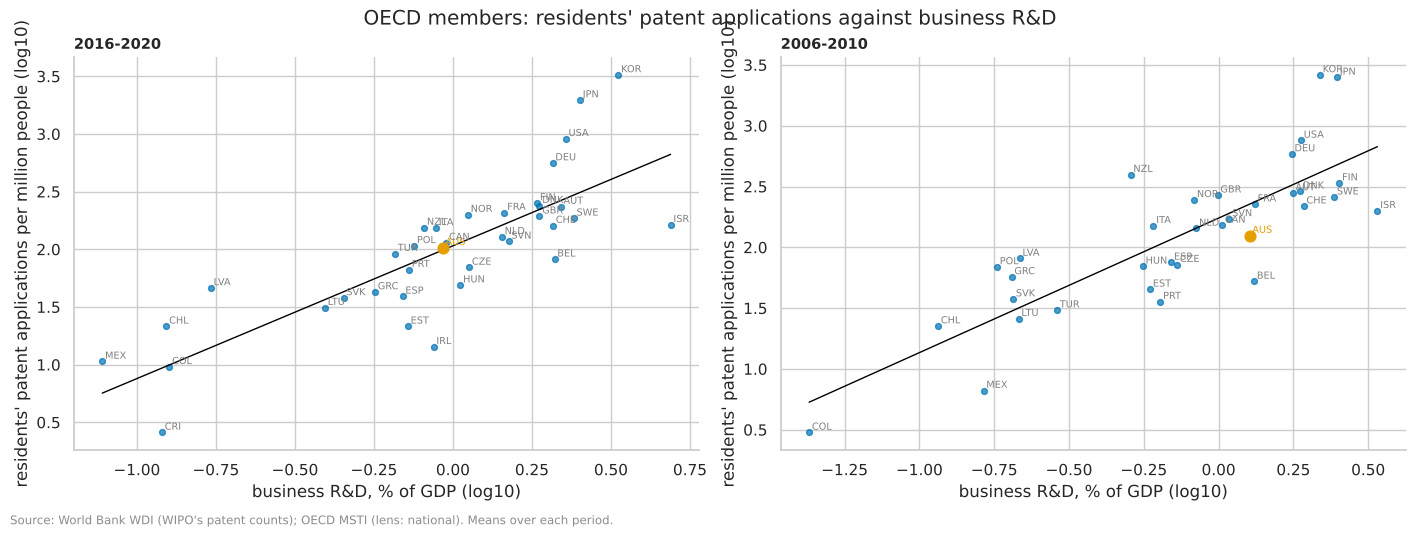

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
out = []
for ax, (p, w) in zip(axes, nat.items(), strict=True):
    o = w[w.oecd.fillna(False).astype(bool)][["IP.PAT.RESD", "OECD.MSTI.B"]].dropna()
    o = o[(o > 0).all(axis=1)]
    x, y = np.log10(o["OECD.MSTI.B"]), np.log10(o["IP.PAT.RESD"])
    fit = sm.OLS(y, sm.add_constant(x)).fit()
    pred = fit.get_prediction(sm.add_constant(x).loc[["AUS"]]).summary_frame(alpha=0.05)
    lo, hi = 10 ** pred["obs_ci_lower"].iloc[0], 10 ** pred["obs_ci_upper"].iloc[0]
    rho = o["OECD.MSTI.B"].corr(o["IP.PAT.RESD"], method="spearman")
    out.append(
        {
            "period": p,
            "members": len(o),
            "spearman rho": rho,
            "slope (log-log)": fit.params.iloc[1],
            "Australia: patents per million": o.at["AUS", "IP.PAT.RESD"],
            "predicted from its BERD": 10 ** pred["mean"].iloc[0],
            "95% prediction interval": f"{lo:.0f} to {hi:.0f}",
            "Australia as a share of predicted (%)": 100 * 10 ** (y["AUS"] - pred["mean"].iloc[0]),
        }
    )
    ax.scatter(x, y, s=18, color=style.MAIN, alpha=0.7)
    ax.scatter(x["AUS"], y["AUS"], s=60, color=style.ACCENT, zorder=3)
    for c in o.index:
        ax.annotate(
            c,
            (x[c], y[c]),
            fontsize=7,
            xytext=(2, 2),
            textcoords="offset points",
            color=style.ACCENT if c == "AUS" else "grey",
        )
    grid = np.linspace(x.min(), x.max(), 50)
    ax.plot(grid, fit.params.iloc[0] + fit.params.iloc[1] * grid, color="black", lw=1)
    ax.set_xlabel("business R&D, % of GDP (log10)")
    ax.set_ylabel("residents' patent applications per million people (log10)")
    ax.set_title({"discovery": "2016-2020", "replication": "2006-2010"}[p], fontsize=10.5)
fig.suptitle("OECD members: residents' patent applications against business R&D")
style.source(fig, "World Bank WDI (WIPO's patent counts); OECD MSTI (lens: national). Means over each period.")
display(pd.DataFrame(out).set_index("period").round(3))

# Changes from 2006-2010 to 2016-2020, across members with both periods
a, b = nat["replication"], nat["discovery"]
both = b.index.intersection(a.index)
both = [c for c in both if bool(b.at[c, "oecd"])]
ch = (
    pd.DataFrame(
        {
            "patents (log change)": np.log10(b.loc[both, "IP.PAT.RESD"] / a.loc[both, "IP.PAT.RESD"]),
            "BERD (change, points of GDP)": b.loc[both, "OECD.MSTI.B"] - a.loc[both, "OECD.MSTI.B"],
        }
    )
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)
print(
    f"Members with both periods: {len(ch)}; Spearman rho of the changes:",
    round(ch.iloc[:, 0].corr(ch.iloc[:, 1], method="spearman"), 3),
)
print("Australia:", ch.loc["AUS"].round(3).to_dict(), "; members whose patenting fell:", int((ch.iloc[:, 0] < 0).sum()))

#### Observations
**B34 (observational). Across OECD members, residents' patenting rises with business R&D almost one for one; Australia
filed about what its R&D predicts in 2016 to 2020, about half in 2006 to 2010; but changes in R&D barely go with
changes in patenting.**
- **The levels:** Spearman rho 0.853 over 36 members (0.795 over 34 earlier); on log scales the slope is 1.151 (1.106),
  so a member with twice the business R&D share files a little more than twice the patents per person.
- **Australia:** 103.3 patent applications per million people in 2016 to 2020, against 98.46 predicted from its
  business R&D (104.9% of predicted; 95% prediction interval 17 to 580); 125 against 226.3 in 2006 to 2010 (55.22%;
  41 to 1,262). The prediction intervals are wide, so Australia is within the members' range in both periods: its
  change in position came from falling R&D (B33), not rising patenting.
- **The changes:** across 34 members, the change in patenting from 2006-2010 to 2016-2020 goes with the change in
  business R&D at a Spearman rho of only 0.165; 23 members' residents filed less. Australia's patenting fell (a log
  change of -0.083) as its business R&D fell by 0.34 points of GDP.
- **So** the strong link is between countries' levels, which share a long history; within a decade the two do not
  move together. A lead for Q4: raising R&D would not, on this evidence, raise patenting quickly.

### 4.3 The attachments: every cross-country indicator against residents' patenting

**From:** U68 to U71. **Informs:** Q1. The cross-country attachments in `national_indicators` (the GII 2026's
indicator values; the OECD's R&D statistics, industry and innovation goals, venture capital and current well-being),
each against residents' patent applications per million people. The OECD's are averaged over the two periods as above;
the GII is one edition, so its replication is the other half of the economies (by a hash of the country code), a
weaker test. The OECD's patent tables are counts of patents themselves, and its business demography tables are cells
by industry and size, so neither is screened here; the Australian-only sources (the ABS, BCARR, Measuring What
Matters, Closing the Gap) have no other country to compare with, and are read over time in section 5.

In [44]:
import warnings

from scipy import stats

warnings.filterwarnings("ignore", message="An input array is constant")
pat = {p: nat[p]["IP.PAT.RESD"] for p in nat}
att, metas = [], []
for p, cond in (("discovery", "year BETWEEN 2016 AND 2020"), ("replication", "year BETWEEN 2006 AND 2010")):
    long = sql(
        f"""
        SELECT iso3, dataset, indicator, any_value(label) AS label, avg(value) AS value
        FROM {{lens/national_indicators}}
        WHERE source = 'oecd'
          AND dataset IN ('msti', 'sdg_09_industry_innovation', 'venture_capital', 'wellbeing_current')
          AND {cond} AND value IS NOT NULL AND coalesce(status, '') NOT ILIKE '%projection%'
        GROUP BY ALL
    """,
        max_rows=None,
    )
    wide = long.pivot_table(index="iso3", columns="indicator", values="value")
    y = pat[p].reindex(wide.index)
    ok = y.notna()
    rho = wide[ok].corrwith(y[ok], method="spearman")
    n = wide[ok].notna().sum()
    att.append(pd.DataFrame({"indicator": rho.index, "rho": rho.to_numpy(), "n": n.to_numpy(), "sample": p}))
    metas.append(long.groupby("indicator")[["dataset", "label"]].first())
# the GII: one edition, halves of the economies
gii = sql(
    """
    SELECT iso3, indicator, any_value(label) AS label, avg(value) AS value FROM {lens/national_indicators}
    WHERE source = 'gii' AND unit = 'as named (the value WIPO screened)' AND value IS NOT NULL GROUP BY ALL
""",
    max_rows=None,
)
gw = gii.pivot_table(index="iso3", columns="indicator", values="value")
gy = nat["discovery"]["IP.PAT.RESD"].reindex(gw.index)
half = pd.Series(pd.util.hash_pandas_object(pd.Series(gw.index + "stage2"), index=False).to_numpy() % 2, index=gw.index)
for h, name in ((0, "discovery"), (1, "replication")):
    idx = gw.index[(half == h).to_numpy() & gy.notna().to_numpy()]
    rho = gw.loc[idx].corrwith(gy[idx], method="spearman")
    att.append(
        pd.DataFrame(
            {"indicator": rho.index, "rho": rho.to_numpy(), "n": gw.loc[idx].notna().sum().to_numpy(), "sample": name}
        )
    )
meta = pd.concat([*metas, gii.groupby("indicator").label.first().to_frame().assign(dataset="gii")])
meta = meta[~meta.index.duplicated()]
att = pd.concat(att)
att = att[att.n >= 15]
t = att.rho * np.sqrt((att.n - 2) / (1 - att.rho.clip(-0.999999, 0.999999) ** 2))
att["p"] = 2 * stats.t.sf(t.abs(), att.n - 2)
w = att.pivot_table(index="indicator", columns="sample", values=["rho", "p", "n"])
w.columns = [f"{a} ({b})" for a, b in w.columns]
w = w.dropna(subset=["rho (discovery)"]).join(meta)
w["q"] = bi.fdr(w["p (discovery)"])
fwd = (w["rho (discovery)"].abs() >= 0.1) & (w.q < 0.05)
w["q (replication)"] = np.nan
w.loc[fwd, "q (replication)"] = bi.fdr(w.loc[fwd, "p (replication)"])
# counts of patents themselves (the GII's patents by origin, the OECD's triadic and PCT patents) are the same measure
w["same measure"] = w.label.fillna("").str.contains("atent")
fwd = fwd & ~w["same measure"]
w["lead"] = (
    fwd
    & (w["rho (replication)"].abs() >= 0.1)
    & (w["q (replication)"] < 0.05)
    & (np.sign(w["rho (discovery)"]) == np.sign(w["rho (replication)"]))
)
print(
    f"Indicators measured: {len(w):,}; counts of patents (not screened): {int(w['same measure'].sum())};",
    f"leads: {int(w.lead.sum()):,}",
)
display(w.groupby("dataset").agg(indicators=("lead", "size"), patents=("same measure", "sum"), leads=("lead", "sum")))
cols = ["dataset", "label", "rho (discovery)", "rho (replication)", "n (discovery)"]
with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    for ds in ("gii", "msti", "wellbeing_current", "venture_capital", "sdg_09_industry_innovation"):
        d = w[w.lead & (w.dataset == ds)]
        if len(d):
            print(f"\n{ds}: strongest leads, both ways")
            d = pd.concat([d.nlargest(6, "rho (discovery)"), d.nsmallest(4, "rho (discovery)")])
            display(d[~d.index.duplicated()].sort_values("rho (discovery)", ascending=False)[cols].round(3))

Indicators measured: 485; counts of patents (not screened): 8; leads: 225


,indicators,patents,leads
dataset,,,
gii,79,3,64
msti,145,5,83
sdg_09_industry_innovation,22,0,6
venture_capital,8,0,6
wellbeing_current,231,0,66



gii: strongest leads, both ways


,dataset,label,rho (discovery),rho (replication),n (discovery)
indicator,,,,,
GII.IN.2.3.1.value,gii,"Researchers, FTE/mn pop.: value",0.856,0.871,46
GII.IN.5.1.1.value,gii,"Knowledge-intensive employment, %: value",0.814,0.864,51
GII.OUT.7.3.1.value,gii,Top-level domains (TLDs)/th pop. 15–69: value,0.804,0.841,57
GII.OUT.6.1.5.value,gii,Citable documents H-index: value,0.795,0.763,57
GII.IN.5.1.4.value,gii,"GERD performed by business, % GDP: value",0.785,0.874,47
GII.OUT.6.3.2.value,gii,Production and export complexity: value,0.783,0.852,56
GII.IN.1.1.1.value,gii,Operational stability for businesses*: value,-0.479,-0.613,57
GII.IN.3.2.2.value,gii,Aviation import dwell time: value,-0.576,-0.716,50
GII.IN.4.3.2.value,gii,Domestic industry diversification: value,-0.599,-0.586,48



msti: strongest leads, both ways


...

,dataset,label,rho (discovery),rho (replication),n (discovery)
indicator,,,,,
OECD.WELLBEING_CURRENT.1_1.USD_PPP_PS._T._T._T.HSL_1.2023,wellbeing_current,"Households and NPISHs net adjusted disposable income per capita, US dollars per person...",0.695,0.566,33
OECD.WELLBEING_CURRENT.10_2.PT_POP_Y_GE15_SUB._T._T.ISCED11_5T8.HSL_10,wellbeing_current,"Feeling safe at night, Percentage of population aged 15 years or over in the same subg...",0.693,0.701,45
OECD.WELLBEING_CURRENT.5_1.Y._T.M._T.HSL_5,wellbeing_current,"Life expectancy at birth, Years, Total, Male, Total, Health",0.656,0.666,45
OECD.WELLBEING_CURRENT.5_1.Y._T._T._T.HSL_5,wellbeing_current,"Life expectancy at birth, Years, Total, Total, Total, Health",0.655,0.68,45
OECD.WELLBEING_CURRENT.5_1.Y._T.F._T.HSL_5,wellbeing_current,"Life expectancy at birth, Years, Total, Female, Total, Health",0.64,0.703,45
OECD.WELLBEING_CURRENT.10_2.PT_POP_Y_GE15_SUB._T.M._T.HSL_10,wellbeing_current,"Feeling safe at night, Percentage of population aged 15 years or over in the same subg...",0.622,0.693,45
OECD.WELLBEING_CURRENT.11_3.PT_POP_Y_GE15_SUB.OLD._T._T.HSL_11,wellbeing_current,"Feelings of physical pain, Percentage of population aged 15 years or over in the same ...",-0.623,-0.495,45
OECD.WELLBEING_CURRENT.2_4.PT_POP_Y15T24_SUB._T.F._T.HSL_2,wellbeing_current,"Youth not in employment, education or training, Percentage of population aged 15-24 ye...",-0.636,-0.528,41
OECD.WELLBEING_CURRENT.10_2_DEP.PT_POP_Y_GE15_SUB._T._T.ISCED11_5T8.HSL_10,wellbeing_current,"Not feeling safe at night, Percentage of population aged 15 years or over in the same ...",-0.645,-0.68,45



venture_capital: strongest leads, both ways


,dataset,label,rho (discovery),rho (replication),n (discovery)
indicator,,,,,
OECD.VENTURE_CAPITAL.VC_INV_MKT.LATER.USD_EXC.USD,venture_capital,"Venture capital investments (market statistics), Later stage venture, US dollars, exch...",0.642,0.673,31
OECD.VENTURE_CAPITAL.VC_INV_MKT.START.USD_EXC.USD,venture_capital,"Venture capital investments (market statistics), Start-up and other early stage, US do...",0.61,0.699,31
OECD.VENTURE_CAPITAL.VC_INV_MKT._T.USD_EXC.USD,venture_capital,"Venture capital investments (market statistics), Total, US dollars, exchange rate conv...",0.59,0.662,36
OECD.VENTURE_CAPITAL.VC_INV_MKT.LATER.PT_B1GQ._Z,venture_capital,"Venture capital investments (market statistics), Later stage venture, Percentage of GDP",0.539,0.545,31
OECD.VENTURE_CAPITAL.VC_INV_MKT.SEED.USD_EXC.USD,venture_capital,"Venture capital investments (market statistics), Seed, US dollars, exchange rate conve...",0.497,0.703,31
OECD.VENTURE_CAPITAL.VC_INV_MKT.START.PT_B1GQ._Z,venture_capital,"Venture capital investments (market statistics), Start-up and other early stage, Perce...",0.413,0.531,31



sdg_09_industry_innovation: strongest leads, both ways


,dataset,label,rho (discovery),rho (replication),n (discovery)
indicator,,,,,
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_5.C090501.9_5_1_GB_XPD_RSDV._T._T._T._T._T.PT_B1GQ.UNSD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sustainable industrializ...",0.863,0.807,36
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_5.C090502.9_5_2_GB_POP_SCIERD._T._T._T._T._T.10P6HB.UNSD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sustainable industrializ...",0.753,0.805,34
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_2.C090201.9_2_1_NV_IND_MANFPC._T._T._T._T._T.USD.UNSD.Q.2015,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sustainable industrializ...",0.715,0.83,36
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_C.C090C01.9_C_1_OECD._T._T._T._T._T.100HB.OECD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sustainable industrializ...",0.612,0.755,36
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_B.C090B01.9_B_1_NV_IND_TECH._T._T._T._T._T.PT_VA.UNSD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sustainable industrializ...",0.571,0.557,35
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_4.C090401.9_4_1_EN_ATM_CO2._T._T._T._T._T.T.UNSD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sustainable industrializ...",0.399,0.342,36


#### Observations
**B35 (observational). Of the cross-country attachments, about half go with residents' patenting, again along
development: research workforce, knowledge-intensive jobs and business-funded R&D lead, and women's share of
researchers goes the other way.** 485 indicators measured (8 of them counts of patents, not screened); 225 leads: 64 of
79 GII indicator values, 83 of 145 OECD R&D statistics, 66 of 231 well-being indicators, 6 of 8 venture capital
series and 6 of 22 industry and innovation goals.
- **GII 2026** (halves of the economies): researchers per million people 0.856 (0.871), knowledge-intensive employment
  0.814 (0.864), business-performed R&D 0.785 (0.874); the youth share of the population -0.743 (-0.79).
- **OECD R&D statistics:** GERD financed by business, as a share of GDP, 0.841 (0.81); business R&D in the computer,
  electronic and optical industry 0.806 (0.755). Women's share of researchers -0.647 (-0.65), and the higher-education
  sector's share of researchers -0.616 (-0.536): where research is done more in business, patenting is higher, and
  business research employs fewer women, so this is a third-factor pattern to test, not a gender finding.
- **Venture capital:** later-stage venture investment 0.642 (0.673), start-up and early stage 0.61 (0.699).
- **Well-being:** household disposable income 0.695 (0.566); difficulty making ends meet -0.748 (-0.764).

### 4.4 Summary of the national lens

| # | Pair | What was found | Strength | Holds in the other period? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B32 | Every pair of indicators | IP moves with R&D, research and income: one development gradient; trade marks with commerce | observational | yes | Yes, as components |
| B33 | Australia among OECD members | Patents middling, trade marks and new businesses near the top; business R&D 13th to 20th; manufacturing last | descriptive | both shown | Context for Q1, Q4 |
| B34 | Business R&D × patenting | Levels almost one for one; changes barely (rho 0.165); Australia near its prediction now | observational | levels yes, changes weak | Yes: Q4 |
| B35 | Cross-country attachments × patenting | Research workforce, knowledge jobs, business-funded R&D, venture capital | observational | yes (GII by halves) | Yes, as components |

**Candidate third factors named most often:** income (GDP per person), the size of business R&D, and a country's
research history. Country pairs are few (36 OECD members), so intervals are wide.

## 5. Lens: Australia over time (one row per month)

**Rules carried from Stage 1:** compare changes, or months around events, never levels: two series that rise over
decades correlate whatever their link (ADR 0006); months against the same month a year earlier; series with a median
under 10 a month by quarter or year (U24); pauses pooled with their backlogs, rushes studied (U29); money deflated by
the CPI (U30).

**The two samples:** the quarters from July 1991 to June 2008 (discovery) and from July 2008 to the last complete
quarter (replication). Each series is a quarter's total against the same quarter a year earlier (the change in its
logarithm, so +0.1 is about 10% more), which removes seasons and long trends; a quarter avoids the noise of single
months and the pauses of U29.

### 5.0 The screen: every pair of series, as changes

Quarters: {'discovery': 68, 'replication': 72}


verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,1,1,178,198,0,28,1


,pair,measure,strength,95% interval,replication,size,versions,candidate third factors,rho
0,Trade marks registered (events) × Trade mark oppositions and non-use removal requests ...,spearman,0.658,0.498 to 0.786,0.588,strong,1,"Patents expired (events), Patents ceased (events), Design applications of unknown origin",0.658


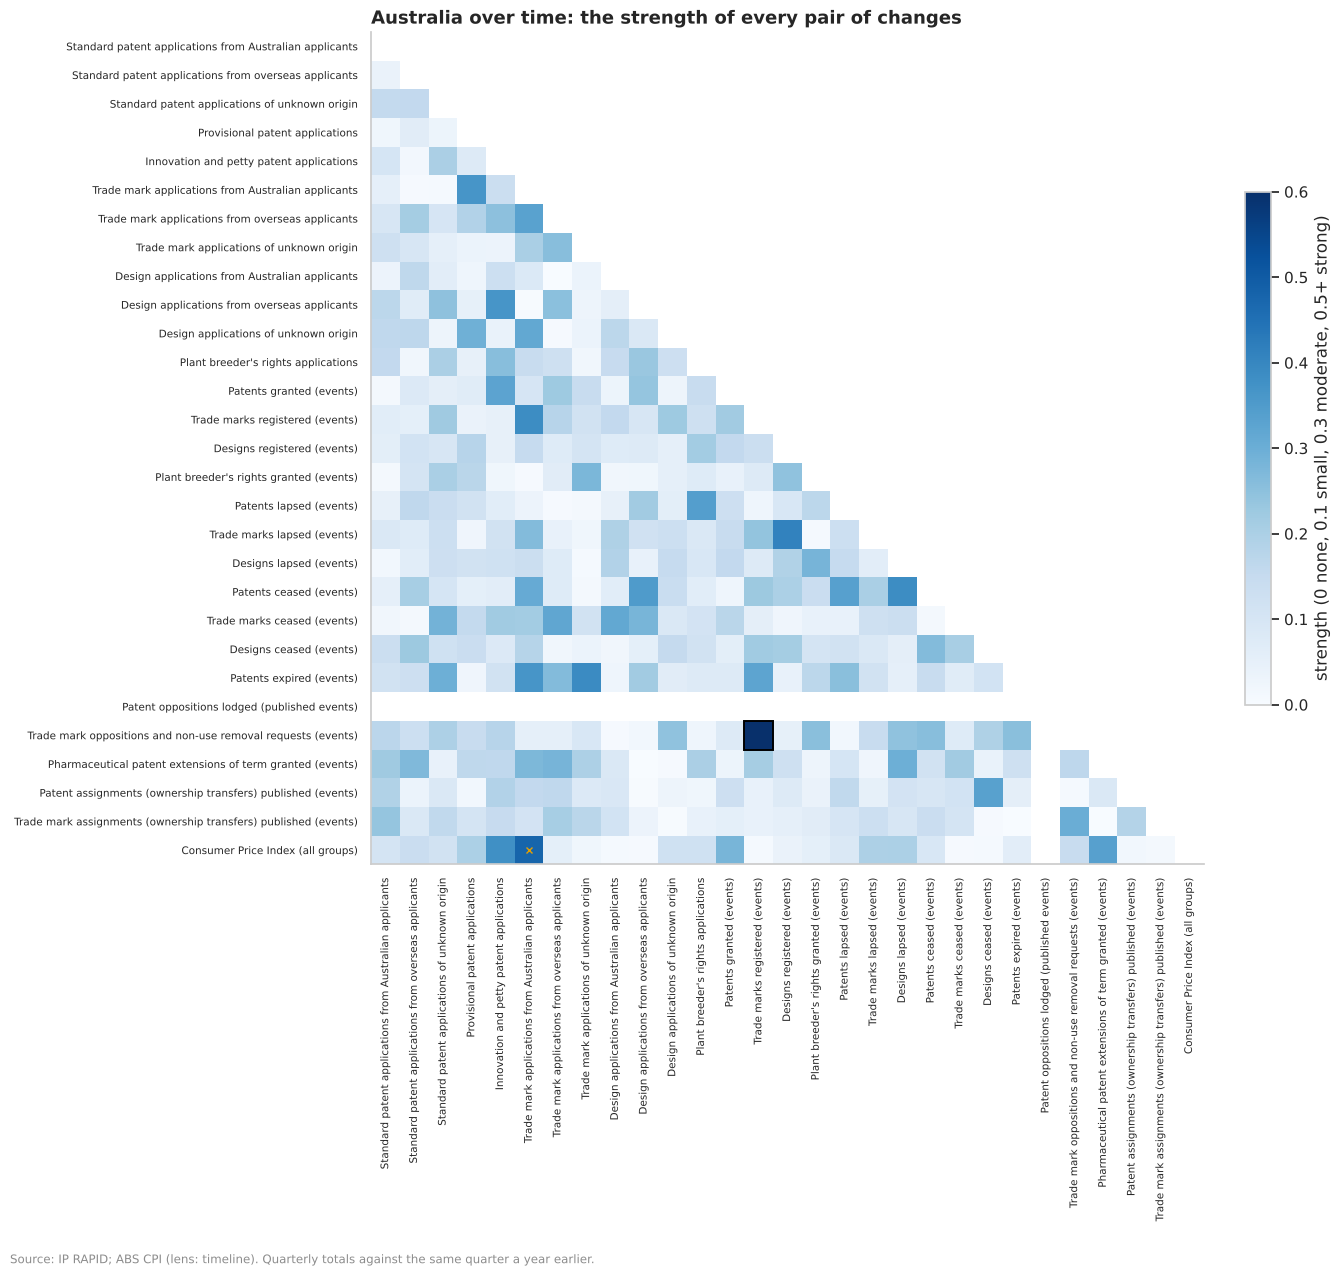

In [45]:
timeline = sql("SELECT * FROM {lens/timeline} ORDER BY month")
TL = bi.screens()["timeline"]
series = [c for c, k in TL["columns"].items() if k == "number"]
q = timeline.assign(quarter=pd.PeriodIndex(timeline.month, freq="Q")).groupby("quarter")
counts = q[[c for c in series if c != "cpi"]].sum(min_count=3).where(q.month.count() == 3)
counts["cpi"] = q.cpi.last()
change = np.log(counts + 1).diff(4)
change = change.loc[pd.Period("1991Q3") : pd.Period("2026Q2")]
halves = {"discovery": change.loc[: pd.Period("2008Q2")], "replication": change.loc[pd.Period("2008Q3") :]}
tkinds = {c: "number" for c in series}
tprep = {p: bi.prepare(d, tkinds) for p, d in halves.items()}
tres = {p: bi.screen(tprep[p], groups=TL.get("groups", {}), min_n=20) for p in tprep}
tm = bi.replicate(tres["discovery"], tres["replication"])
tl_leads = bi.distinct_leads(tm, TL.get("groups", {}))


def tlab(c):
    return bi.screen_label("timeline", c)


print("Quarters:", {p: len(d) for p, d in halves.items()})
display(bi.verdict_counts(tm).to_frame("pairs").T.assign(**{"distinct leads": len(tl_leads)}))
fig = bi.strength_map(tm, series, label=tlab, title="Australia over time: the strength of every pair of changes")
style.source(fig, "IP RAPID; ABS CPI (lens: timeline). Quarterly totals against the same quarter a year earlier.")
tl_table = bi.leads_table(tl_leads, tprep["discovery"], tres["discovery"], label=tlab)
with pd.option_context("display.max_rows", 120, "display.width", 250):
    display(tl_table.assign(rho=tl_leads.rho.round(3).to_numpy()).drop(columns="direction").round(3))

#### Observations
**B36 (observational). As changes, the monthly series hardly move together: one pair holds in both periods, and it is
the trade mark process itself.** 68 quarters in the discovery period and 72 in the replication: 1 lead, 1 pair
that holds in one period only, 178 negligible, 198 below the correction, 28 measured in too few quarters.
- **The one lead:** trade mark registrations and trade mark oppositions (rho 0.658, interval 0.498 to 0.786; 0.588):
  more marks reaching the end of examination means more to oppose and more to register in the same quarters.
- **What does not move together:** Australians' and overseas applicants' filings, as changes (5.3); filings and the
  CPI; filings and the events that follow them a year or more later. Each series' changes are driven by its own
  events (rushes, pauses, rule changes), not a common cycle, which is why Stage 1's 17 policy changes are read one by
  one (5.1).

### 5.1 Before and after each policy change, against placebo dates

**From:** U28. **Informs:** Q4, Q5. Stage 1 named eight candidates: two rushes before a change, four steps after one,
and two pauses at a new Act's commencement. For each, two measures of the target series: the **spike** (the month of
the change against the average month of the year before) and the **step** (the average month of the year after
against the year before), both as logarithms. The same measures are then taken at every **placebo date**: each month
from five years before to five years after the change, leaving out the two years either side of it. The share of
placebo months with a spike or step at least as large (either way) says how unusual the change's month is for that
series; it allows for trends and seasons, since the placebos have them too.

In [46]:
CANDIDATES = {
    "raising-the-bar": ["patents_standard_au", "patents_standard_overseas"],
    "innovation-patent-closed": ["patents_second_tier"],
    "patent-term-20-years": ["patents_expired"],
    "pharma-extension-of-term": ["patent_extensions_of_term"],
    "innovation-patent-introduced": ["patents_second_tier"],
    "designs-act-2003": ["designs_overseas", "designs_au", "designs_registered"],
    "trade-marks-act-1995": ["trade_marks_registered", "trade_marks_au"],
    "patents-act-1990": ["patents_granted"],
}
t = timeline.set_index("month")
marked = timeline.loc[timeline.policy_events.notna(), ["month", "policy_events"]]
when = {e: m for m, names in marked.itertuples(index=False) for e in names.split(", ")}


def spike_step(y, i):
    before, after = y.iloc[i - 12 : i].mean(), y.iloc[i + 1 : i + 13].mean()
    return np.log((y.iloc[i] + 1) / (before + 1)), np.log((after + 1) / (before + 1))


rows = []
for event, cols in CANDIDATES.items():
    i0 = t.index.get_loc(when[event])
    for c in cols:
        y = t[c].astype(float)
        s0, st0 = spike_step(y, i0)
        placebo = [
            spike_step(y, i)
            for i in range(i0 - 60, i0 + 61)
            if abs(i - i0) > 24 and 12 <= i < len(y) - 13 and y.iloc[i - 12 : i + 13].notna().all()
        ]
        ps = np.array(placebo)
        rows.append(
            {
                "change": event,
                "month": f"{when[event]:%Y-%m}",
                "series": c,
                "placebo months": len(ps),
                "spike (log)": s0,
                "placebos as large (%)": 100 * np.mean(np.abs(ps[:, 0]) >= abs(s0)) if len(ps) else np.nan,
                "step (log)": st0,
                "placebo steps as large (%)": 100 * np.mean(np.abs(ps[:, 1]) >= abs(st0)) if len(ps) else np.nan,
            }
        )
pd.DataFrame(rows).set_index(["change", "series"]).round(3)

month  placebo months  spike (log)  placebos as large (%)  step (log)  placebo steps as large (%)
change                       series                                                                                                                        
raising-the-bar              patents_standard_au        2013-04              72        1.476                      0      -0.413                           0
                             patents_standard_overseas  2013-04              72        0.977                      0      -0.079                       15.28
innovation-patent-closed     patents_second_tier        2021-08              60        1.459                      0       -3.17                           0
patent-term-20-years         patents_expired            1995-07              36       -0.851                  22.22      -3.937                           0
pharma-extension-of-term     patent_extensions_of_term  1999-01              72        -0.08                  98.61       2.419                           0
innovation-patent-introduced patents_second_tier        2001-05              72        0.853                      0       0.531                           0
designs-act-2003             designs_overseas           2004-06              72        0.455                  4.167       0.292                           0
                             designs_au                 2004-06              72         0.28                  23.61       0.063                       29.17
                             designs_registered         2004-06              72       -0.484                  16.67       0.218                       38.89
trade-marks-act-1995         trade_marks_registered     1996-01              72       -7.205                      0       0.284                       16.67
                             trade_marks_au             1996-01              72       -0.712                      0      -0.254                       11.11
patents-act-1990             patents_granted            1991-04              72         0.19                  33.33       0.046                       93.06

#### Observations
**B37 (observational). The two rushes, three of the four steps and both of the 1995 pauses are far outside anything
seen at placebo dates; the Designs Act's effect on Australians and the 1991 pause are not.** For each change, the
share of placebo months (up to 72, from five years either side) with a spike or step at least as large:
- **Rushes:** Raising the Bar (April 2013), Australians' standard patents a spike of 1.476 in logs (4.39 times
  the usual month, U28) and overseas applicants' 0.977, with 0% of placebo months as large; Australians' step after it
  -0.413 (0%), overseas -0.079 (15.28%). The innovation patent's closure (August 2021): a spike of 1.459 and a step of
  -3.17, both 0%.
- **Steps:** the 20-year term (July 1995), patent expiries -3.937 (0% of 36); the extension of term regime (January
  1999) 2.419 (0%); the innovation patent's introduction (May 2001), second-tier applications 0.531 (0%); the Designs
  Act 2003, overseas applicants' designs 0.292 (0%). Australians' designs (0.063, 29.17%) and design registrations
  (0.218, 38.89%) did not step beyond the ordinary.
- **Pauses:** the Trade Marks Act 1995 (January 1996): registrations a spike of -7.205 and Australians' applications
  -0.712, both 0%. The Patents Act 1990 (April 1991): patent grants 0.19 (33.33%), a step of 0.046 (93.06%): the pause
  U28 saw came in June 1991, two months after commencement, so the commencement month itself is ordinary.
- **For Q5:** these six changes give clean breaks for the natural experiments the research goal asks for after Stage
  3, each beside series it should not have moved. The fee changes, IP Australia's most direct lever, are still not in
  the data (R3, OQ2).

### 5.2 The provisional rise: how often provisionals are followed up

**From:** U8. **Informs:** Q4. Provisional applications from Australian filers doubled in FY2026 (U8), and no change
in the policy events coincides with it (the latest, the designs grace period, is March 2022). If the extra
provisionals were placeholders that will not be pursued, fewer of them would be followed by an Australian complete
application within 12 months (one that claims the provisional: IP RAPID's links). The 12 months are complete for
provisionals filed to FY2025. A follow-up through the PCT reaches Australia only at national phase entry, about 30
months later, so it is not counted here. Beside it: the share of Australian filers' standard patents that claim an
Australian application at all, since U90 found priority claims may be recorded late.

provisionals              followed within 12 months (%)                     low                    high             
founder_type   individual organisation                    individual organisation individual organisation individual organisation
filing_fy                                                                                                                        
2018                 1876         2938                          13.7        16.98      12.22        15.67      15.33        18.39
2019                 1753         2939                         13.46        17.66      11.94        16.32      15.14        19.08
2020                 1720         2921                         12.73        17.08      11.24        15.76      14.39        18.49
2021                 1594         2780                         18.76        20.68      16.92        19.22      20.75        22.23
2022                 1381         2503                         12.24        12.23      10.61           11      14.07        13.57
2023                 1420         2559                         14.15        10.63      12.44         9.49      16.06        11.88
2024                 1306         2514                         12.25        12.05      10.58        10.84      14.14        13.38
2025                 1891         2804                          6.66         9.49       5.62         8.46       7.88        10.63

,standard patents claiming an Australian application (%)
filing_fy,
2018,56.36
2019,57.84
2020,59.62
2021,60.61
2022,55.31
2023,56.19
2024,53.53
2025,49.15
2026,40.48


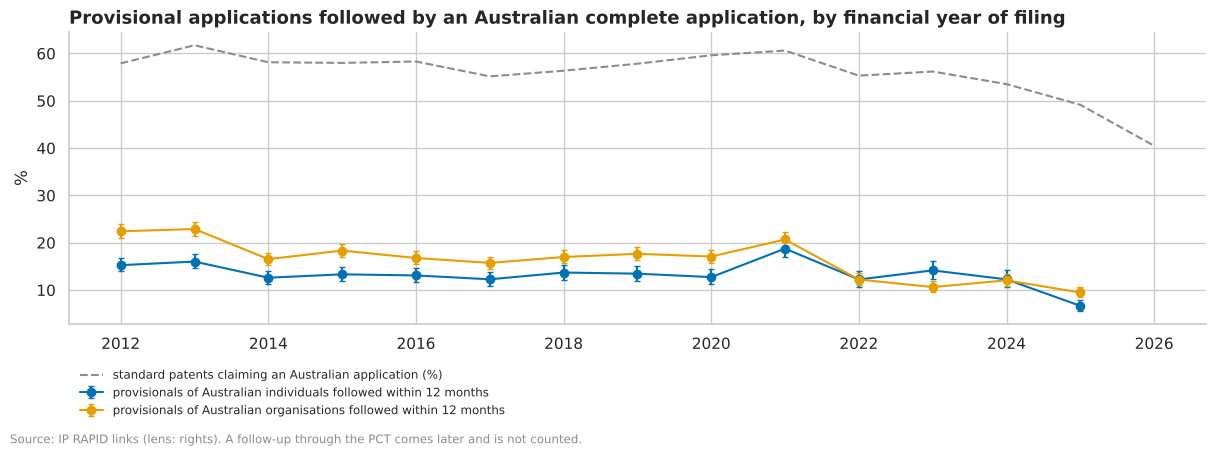

In [47]:
follow = (
    sql("""
    WITH p AS (SELECT application_number, application_date, filing_fy, founder_type FROM {lens/rights}
               WHERE patent_type = 'provisional' AND filing_fy BETWEEN 2012 AND 2025 AND founding_australian
                 AND founder_type IS NOT NULL),
    c AS (SELECT l.linked_application_number AS provisional, min(r.application_date) AS claimed
          FROM {iprapid/links} l JOIN {lens/rights} r
               ON r.application_number = l.application_number AND r.ip_right_type = 'patent'
          WHERE l.link_type IN ('associated_provisional', 'convention', 'complete_from_a_provisional',
                                'innovation_from_a_provisional')
          GROUP BY 1)
    SELECT filing_fy, founder_type, count(*) AS provisionals,
           count(*) FILTER (c.claimed IS NOT NULL AND date_diff('day', p.application_date, c.claimed) <= 380)
               AS followed_12m
    FROM p LEFT JOIN c ON c.provisional = p.application_number GROUP BY ALL
""")
    .set_index(["founder_type", "filing_fy"])
    .sort_index()
)
follow["followed within 12 months (%)"] = 100 * follow.followed_12m / follow.provisionals
lo, hi = bi.wilson(follow.followed_12m, follow.provisionals)
follow["low"], follow["high"] = 100 * lo, 100 * hi
claims = sql("""
    SELECT filing_fy, 100 * avg(australian_priority::int) AS "standard patents claiming an Australian application (%)"
    FROM {lens/rights} WHERE patent_type = 'standard' AND founding_australian AND filing_fy BETWEEN 2012 AND 2026
    GROUP BY 1 ORDER BY 1
""").set_index("filing_fy")
fig, ax = plt.subplots(figsize=(12, 4.2))
for i, (ft, d) in enumerate(follow.groupby(level=0)):
    d = d.droplevel(0)
    ax.errorbar(
        d.index,
        d["followed within 12 months (%)"],
        yerr=[d["followed within 12 months (%)"] - d.low, d.high - d["followed within 12 months (%)"]],
        fmt="o-",
        color=style.PALETTE[i],
        capsize=2,
        label=f"provisionals of Australian {ft}s followed within 12 months",
    )
ax.plot(claims.index, claims.iloc[:, 0], color=style.MUTED, ls="--", label=claims.columns[0])
ax.set_ylabel("%")
ax.legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=1)
ax.set_title("Provisional applications followed by an Australian complete application, by financial year of filing")
style.source(fig, "IP RAPID links (lens: rights). A follow-up through the PCT comes later and is not counted.")
display(follow[["provisionals", "followed within 12 months (%)", "low", "high"]].round(2).unstack(0).loc[2018:])
claims.loc[2018:].round(2)

#### Observations
**B38 (observational). Provisionals filed in FY2025 were followed up less often within 12 months, individuals' by
about half; but priority claims in general are falling in the latest years, so late recording cannot be ruled out.**
- **Followed by an Australian complete application within 12 months:** Australian individuals' provisionals 6.66%
  in FY2025 (interval 5.62% to 7.88%, 1,891 provisionals), against 12.24% to 18.76% in FY2018 to FY2024;
  organisations' 9.49% (8.46% to 10.63%), against 10.63% to 20.68%.
- **But the claims themselves are thinning:** Australian filers' standard patents that claim an Australian
  application were 55.31% to 60.61% in FY2018 to FY2023, then 53.53% (FY2024), 49.15% (FY2025) and 40.48% (FY2026),
  the same pattern U90 read as a rise in direct filing.
- **Reading:** if claims are recorded late, both measures fall for the latest years whatever applicants did. The
  individuals' fall is the larger (from 12.25% in FY2024 to 6.66%, against 12.05% to 9.49% for organisations), which
  fits the surge of U8 being concentrated in individuals' provisionals that are not pursued, but this is a lead, not a
  finding. **It adds a question for IP Australia:** whether priority claims and associated provisionals are recorded
  in IP RAPID when an application is filed or only later (beside OQ5 and U90's lead).

### 5.3 Australian against overseas applicants, and the annual series for Australia alone

**From:** U25, U66, and the Australia-only attachments of `national_indicators` (section 4.3). **Informs:** Q1, Q2.
First, whether Australian and overseas applications move together from year to year (from the screen above). Then
every annual series held for Australia alone (the ABS's business and R&D statistics, BCARR, Measuring What Matters,
Closing the Gap, and Australia's own rows of the national lens), as year-on-year changes, against the change in
Australians' standard patent and trade mark applications in the same financial year. These series are short (most
have under 20 years), so they are screened over all their years together, without a second period: any lead from
them is single-sample and is labelled so.

In [48]:
from scipy import stats as _s

own = tm[tm["variable 1"].str.endswith(("_au", "_overseas")) & tm["variable 2"].str.endswith(("_au", "_overseas"))]
own = own[own.apply(lambda r: r["variable 1"].rsplit("_", 1)[0] == r["variable 2"].rsplit("_", 1)[0], axis=1)]
display(own[["variable 1", "variable 2", "rho", "rho (replication)", "verdict"]].round(3))

fy = timeline.groupby("fy")[["patents_standard_au", "trade_marks_au"]].sum(min_count=12)
fy_change = np.log(fy).diff()
au = sql(
    """
    SELECT source || ': ' || coalesce(dataset, '') AS dataset, indicator, any_value(label) AS label, year,
           avg(value) AS value
    FROM {lens/national_indicators}
    WHERE iso3 = 'AUS' AND source IN ('abs', 'bcarr', 'mwm', 'ctg') AND value IS NOT NULL AND year IS NOT NULL
      AND coalesce(status, '') NOT ILIKE '%traject%' AND coalesce(status, '') NOT ILIKE '%project%'
    GROUP BY ALL
    UNION ALL
    SELECT 'national lens', indicator, any_value(indicator_name), year, avg(value)
    FROM {lens/national} WHERE iso3 = 'AUS' AND value IS NOT NULL GROUP BY ALL
""",
    max_rows=None,
)
w = au.pivot_table(index="year", columns="indicator", values="value")
w = w[[c for c in w if w[c].notna().sum() >= 8]]
wc = w.pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
out = []
for target in fy_change:
    y = fy_change[target].reindex(wc.index)
    ok = y.notna()
    rho = wc[ok].corrwith(y[ok], method="spearman")
    n = wc[ok].notna().sum()
    out.append(pd.DataFrame({"indicator": rho.index, "target": target, "rho": rho.to_numpy(), "n": n.to_numpy()}))
out = pd.concat(out).dropna()
out = out[out.n >= 8]
tt = out.rho * np.sqrt((out.n - 2) / (1 - out.rho.clip(-0.999999, 0.999999) ** 2))
out["p"] = 2 * _s.t.sf(tt.abs(), out.n - 2)
out["q"] = bi.fdr(out.p)
meta = au.groupby("indicator")[["dataset", "label"]].first()
out = out.join(meta, on="indicator")
print(
    f"Australian annual series with 8 or more years of changes: {w.shape[1]}; pairs: {len(out)};",
    f"q below 0.05: {int((out.q < 0.05).sum())}; |rho| of 0.5 or more: {int((out.rho.abs() >= 0.5).sum())}",
)
with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    display(out.sort_values("p").head(12)[["target", "dataset", "label", "rho", "n", "q"]].round(3))

,variable 1,variable 2,rho,rho (replication),verdict
15,trade_marks_au,trade_marks_overseas,0.332,0.137,not significant
260,designs_au,designs_overseas,0.059,0.041,negligible
302,patents_standard_au,patents_standard_overseas,-0.038,0.45,negligible


/home/user/Aus-GII-Breakdown/.venv/lib/python3.13/site-packages/pandas/core/arrays/masked.py:788: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs2, **kwargs)


Australian annual series with 8 or more years of changes: 336; pairs: 568; q below 0.05: 4; |rho| of 0.5 or more: 54


,target,dataset,label,rho,n,q
232,patents_standard_au,national lens,"Patent applications, residents",0.636,44,0.002
233,trade_marks_au,national lens,"Trademark applications, nonresident, by count",0.785,20,0.012
335,trade_marks_au,national lens,"Trade mark applications by residents, counted in classes (all offices)",0.744,20,0.032
234,trade_marks_au,national lens,"Trademark applications, resident, by count",0.734,20,0.033
238,trade_marks_au,mwm: healthy/access-health-services,"Access to health services, Wait times, Waited longer than felt acceptable fo...",-0.891,10,0.059
4,trade_marks_au,bcarr: 2008-09 to 2022-23,Advertising and promotion: Output (2008-09 to 2022-23 release),-0.798,14,0.059
58,trade_marks_au,bcarr: 2008-09 to 2022-23,Museums and galleries: Output (2008-09 to 2022-23 release),-0.789,14,0.064
320,trade_marks_au,national lens,Exports of goods and services (% of GDP),-0.484,41,0.096
265,trade_marks_au,mwm: sustainable/fiscal-sustainability,"Fiscal sustainability, Progress, All Australia general government sector net...",0.842,10,0.14
87,trade_marks_au,bcarr: 2015-16 to 2024-25,Advertising and promotion: Output (2015-16 to 2024-25 release),-0.867,9,0.142


#### Observations
**B39 (observational). Australians' and overseas applicants' filings do not move together from quarter to quarter, and
no annual series for Australia alone moves with Australians' filing once the number of series is allowed for.**
- **Australian against overseas, quarterly changes:** trade marks rho 0.332 then 0.137 (below the correction in the
  second period), designs 0.059 and 0.041, standard patents -0.038 then 0.45. Their drivers differ (overseas filings
  follow the PCT's 30-month delay and foreign cycles, U6).
- **Annual series for Australia alone:** 336 series with 8 or more years of changes, 568 pairs with Australians'
  standard patent or trade mark applications. Only 4 pass the correction, and all four are other counts of the same
  filings (the World Bank's residents' patent applications, rho 0.636 over 44 years; residents' and non-residents'
  trade marks, 0.734 to 0.785 over 20 years). 54 pairs reach a rho of 0.5 or more, but on short series (the
  strongest shown have 9 to 14 years), which the correction does not let through.
- **So** the Australian-only sources add context (what Measuring What Matters or BCARR say about the economy), not
  year-to-year signals about filing; their use is in Stage 3's designs, not in pairs.

### 5.4 Official fee changes against placebo dates (added after Stage 2; ADR 0031)

**From:** U108 to U111, B37. **Informs:** Q4, Q5. Every date a right's key fees changed (`frl_fees`, the timeline's
`fee_changes`), with the change in the official fees to obtain that right (the month after against the month
before). **Filing:** the right's application series, measured as in 5.1 but with the **rush** taken over the month
before the change and the month of it (a filer avoiding a rise files early). **Renewal:** the rights that ceased
early (usually an unpaid renewal fee) around each change in the fee to keep them, comparing months 7 to 18 after the
change with the year before, since a renewal falls due on an anniversary and can be paid up to six months late. Each
measure is set against every placebo month from five years either side, leaving out the two years around the change.

In [49]:
from scipy import stats

# Each date a right's fees changed (frl_fees/fee_changes, in the timeline's fee_changes column), the change in the
# cost of obtaining that right (the month after against the month before, in dollars of the day), and its filing
# series: the month before the change and the month of it against the year before (a rush), and the year after
# against the year before (a step), both in logs, beside the same measures at every placebo month from five years
# either side (leaving out the two years around the change), as in 5.1.
COST = {
    "patent": ("fee_patent_to_grant", ["patents_standard_au", "patents_standard_overseas"]),
    "trade_mark": ("fee_tm_to_register", ["trade_marks_au", "trade_marks_overseas"]),
    "design": ("fee_design_filing", ["designs_au", "designs_overseas"]),
    "pbr": ("fee_pbr_to_grant", ["pbr_applications"]),
}
t = timeline.set_index("month")


def rush_step(y, i):
    before, after = y.iloc[i - 13 : i - 1].mean(), y.iloc[i + 1 : i + 13].mean()
    rush = np.log((y.iloc[i - 1 : i + 1].mean() + 1) / (before + 1))
    return rush, np.log((after + 1) / (before + 1))


def against_placebos(y, i0, measure, lo=60, gap=24, ahead=13):
    m0 = measure(y, i0)
    ps = np.array(
        [
            measure(y, i)
            for i in range(i0 - lo, i0 + lo + 1)
            if abs(i - i0) > gap and 13 <= i < len(y) - ahead and y.iloc[i - 13 : i + ahead].notna().all()
        ]
    )
    shares = [100 * np.mean(np.abs(ps[:, k]) >= abs(m0[k])) if len(ps) else np.nan for k in range(len(m0))]
    return m0, shares, len(ps)


rows = []
for month, rights in t.fee_changes.dropna().items():
    i0 = t.index.get_loc(month)
    for right in rights.split(", "):
        cost, series = COST[right]
        before, after = t[cost].iloc[i0 - 1], t[cost].iloc[i0 + 1]
        for c in series:
            y = t[c].astype(float)
            if y.iloc[max(i0 - 13, 0) : i0 + 13].isna().any() or i0 + 13 > len(y):
                continue
            (rush, step), (p_rush, p_step), n = against_placebos(y, i0, rush_step)
            rows.append(
                {
                    "month": f"{month:%Y-%m}",
                    "right": right,
                    "cost before": before,
                    "cost after": after,
                    "cost change (%)": 100 * (after / before - 1),
                    "series": c,
                    "placebos": n,
                    "rush (log)": rush,
                    "placebos as large (%)": p_rush,
                    "step (log)": step,
                    "placebo steps as large (%)": p_step,
                }
            )
filing = pd.DataFrame(rows)
print(
    f"{filing.month.nunique()} months with a fee change and a filing series around them; "
    f"{len(filing)} change and series pairs"
)
money = ["cost before", "cost after"]
with pd.option_context("display.max_rows", 100):
    display(filing.set_index(["month", "right", "series"]).round(3).astype({c: "Int64" for c in money}))

22 months with a fee change and a filing series around them; 70 change and series pairs


cost before  cost after  cost change (%)  placebos  rush (log)  placebos as large (%)  step (log)  \
month   right      series                                                                                                                         
1988-07 design     designs_au                          65          75            15.38        36      -0.149                     50      -0.136   
                   designs_overseas                    65          75            15.38        36       0.018                  88.89       0.013   
1989-07 design     designs_au                          75          80            6.667        41      -0.095                  60.98      -0.013   
                   designs_overseas                    75          80            6.667        41       0.005                  95.12       0.049   
1991-05 design     designs_au                          80          85             6.25        63      -0.014                  93.65      -0.025   
                   designs_overseas                    80          85             6.25        63       -0.28                  15.87      -0.201   
        trade_mark trade_marks_au                     360         395            9.722        72        0.14                  31.94       0.183   
                   trade_marks_overseas               360         395            9.722        72       0.127                  16.67      -0.026   
1992-07 design     designs_au                          85          90            5.882        72      -0.037                  80.56       0.068   
                   designs_overseas                    85          90            5.882        72       0.002                    100       0.045   
        patent     patents_standard_au                780         805            3.205        72       0.089                   37.5       0.068   
                   patents_standard_overseas          780         805            3.205        72       0.035                  80.56      -0.057   
        trade_mark trade_marks_au                     395         410            3.797        72       0.195                   12.5       0.158   
                   trade_marks_overseas               395         410            3.797        72        0.02                  90.28       0.032   
1993-07 design     designs_au                          90          90                0        72       0.015                  93.06       0.033   
                   designs_overseas                    90          90                0        72       0.178                  33.33       0.153   
        patent     patents_standard_au                805         845            4.969        72       0.025                  79.17      -0.005   
                   patents_standard_overseas          805         845            4.969        72      -0.051                  55.56       0.003   
        trade_mark trade_marks_au                     410         410                0        72       0.166                  18.06       0.186   
                   trade_marks_overseas               410         410                0        72       0.123                  23.61       0.121   
1994-10 patent     patents_standard_au                845         980            15.98        72       -0.01                  93.06       0.019   
                   patents_standard_overseas          845         980            15.98        72       0.045                  59.72       0.054   
1995-01 pbr        pbr_applications                  2050        2000           -2.439        72       0.148                  69.44       0.131   
1996-01 trade_mark trade_marks_au                     410         560            36.59        72      -0.315                  2.778      -0.251   
                   trade_marks_overseas               410         560            36.59        72      -0.229                  1.389      -0.139   
1997-12 trade_mark trade_marks_au                     560         450        

18 changes of 10% or more, 34 pairs; rises 12, cuts 6
     unusual rush       unusual step      
              sum count          sum count
rise                                      
cut             1    12            1    12
rise            3    22            2    22


Spearman's rho, cost change against step, 34 pairs: -0.306 (95% interval -0.646 to 0.080)


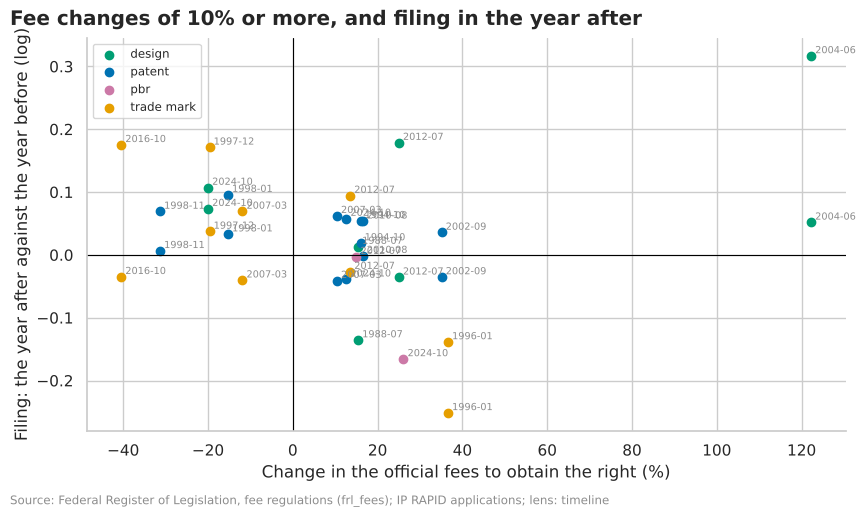

In [50]:
# The larger changes only (the cost of obtaining the right moved by 10% or more): how often the filing series rushed
# or stepped beyond 95% of its placebo months, and whether rises and cuts point the way a price would
big = filing[filing["cost change (%)"].abs() >= 10].copy()
big["unusual rush"] = big["placebos as large (%)"] <= 5
big["unusual step"] = big["placebo steps as large (%)"] <= 5
big["rise"] = big["cost change (%)"] > 0
changed = big.drop_duplicates(["month", "right"])
print(
    f"{len(changed)} changes of 10% or more, {len(big)} pairs; rises {changed.rise.sum()}, cuts {(~changed.rise).sum()}"
)
print(
    big.groupby("rise")[["unusual rush", "unusual step"]]
    .agg(["sum", "count"])
    .rename(index={True: "rise", False: "cut"})
)
# Across the larger changes: the size of the cost change against the step (rank correlation, with a bootstrap
# interval over changes)
r0 = stats.spearmanr(big["cost change (%)"], big["step (log)"]).statistic
rng = np.random.default_rng(31)
pairs = big[["cost change (%)", "step (log)"]].to_numpy()
boot = [stats.spearmanr(*pairs[rng.integers(0, len(pairs), len(pairs))].T).statistic for _ in range(2000)]
lo, hi = np.nanpercentile(boot, [2.5, 97.5])
print(f"Spearman's rho, cost change against step, {len(big)} pairs: {r0:.3f} (95% interval {lo:.3f} to {hi:.3f})")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for right, g in big.groupby("right"):
    ax.scatter(g["cost change (%)"], g["step (log)"], color=style.RIGHTS[right], label=right.replace("_", " "), s=36)
for month, x, y in big[["month", "cost change (%)", "step (log)"]].itertuples(index=False):
    ax.annotate(month, (x, y), fontsize=7, color=style.MUTED, xytext=(3, 2), textcoords="offset points")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in the official fees to obtain the right (%)")
ax.set_ylabel("Filing: the year after against the year before (log)")
ax.legend(fontsize=8.5)
fig.suptitle("Fee changes of 10% or more, and filing in the year after", x=0, ha="left", fontweight="bold")
style.source(fig, "Federal Register of Legislation, fee regulations (frl_fees); IP RAPID applications; lens: timeline")

In [51]:
# Renewal: rights that ended early (ceased, usually for an unpaid renewal fee) around each change in the fee to keep
# them. A renewal falls due on an anniversary and can be paid up to six months late, so the step compares months 7
# to 18 after the change with the 12 months before it; the month of the change and the next six are left out.
KEEP = {
    "patent": ("fee_patent_renewals", "patents_ceased"),
    "trade_mark": ("fee_tm_renewal", "trade_marks_ceased"),
    "design": ("fee_design_renewal", "designs_ceased"),
}


def lagged_step(y, i):
    before, after = y.iloc[i - 12 : i].mean(), y.iloc[i + 7 : i + 19].mean()
    return (np.log((after + 1) / (before + 1)),)


rows = []
for right, (fee, ceased) in KEEP.items():
    f, y = t[fee], t[ceased].astype(float)
    for i0 in np.flatnonzero((f.shift(-1) != f) & f.notna() & f.shift(-1).notna()):
        i0 += 1  # the first month at the new level
        before, after = f.iloc[i0 - 1], f.iloc[i0]
        if y.iloc[i0 - 12 : i0 + 19].isna().any() or i0 + 19 > len(y):
            continue
        (step,), (share,), n = against_placebos(y, i0, lagged_step, ahead=19)
        rows.append(
            {
                "month": f"{t.index[i0]:%Y-%m}",
                "right": right,
                "renewal fee before": before,
                "after": after,
                "change (%)": 100 * (after / before - 1),
                "series": ceased,
                "placebos": n,
                "ceased, months 7-18 after against the year before (log)": step,
                "placebo steps as large (%)": share,
            }
        )
renewal = pd.DataFrame(rows)
renewal.set_index(["month", "right"]).round(3).astype({"renewal fee before": "Int64", "after": "Int64"})

,,renewal fee before,after,change (%),series,placebos,"ceased, months 7-18 after against the year before (log)",placebo steps as large (%)
month,right,,,,,,,
1998-11,patent,6995,6740,-3.645,patents_ceased,41,-0.016,100
2002-09,patent,6740,7830,16.17,patents_ceased,72,0.353,0
2007-03,patent,7830,7750,-1.022,patents_ceased,72,-0.062,81.94
2010-08,patent,7750,8600,10.97,patents_ceased,72,-0.236,6.944
2012-07,patent,8600,9900,15.12,patents_ceased,72,0.069,66.67
2016-11,patent,9900,10800,9.091,patents_ceased,72,0.073,66.67
2020-10,patent,10800,15425,42.82,patents_ceased,64,0.114,31.25
2024-10,patent,15425,16550,7.293,patents_ceased,36,-0.147,75
1991-05,trade_mark,435,470,8.046,trade_marks_ceased,51,0.025,72.55


#### Observations
**B47 (observational). Changes in the fees to obtain a right rarely moved filing beyond what placebo months show;
the clearest breaks are new Acts, not prices.**
- 22 months with a fee change have a filing series around them (70 pairs of change and series). 18 changed the fees
  to obtain a right by 10% or more (12 rises, 6 cuts; 34 pairs).
- Of those 34, filing rushed beyond 95% of its placebo months 4 times (3 of 22 pairs after rises, 1 of 12 after
  cuts) and stepped 3 times (2 and 1), against about 1.7 of each expected by chance at that threshold.
- The breaks are new Acts: the Trade Marks Act 1995 (January 1996, the cost of a trade mark up 36.59%), Australians'
  applications -0.315 in logs (2.778% of placebos as large) and overseas applicants' -0.229 (1.389%), the pause of
  B37; the Designs Act 2003 (June 2004, a design's filing fee up 122.2%), overseas applicants' designs rose (a rush of
  0.369 and a step of 0.317, 0%).
- The breaks that point the way a price would: overseas applicants' standard patents after the 15.31% cut of January
  1998 (a rush of 0.147, 2.778%; a step of 0.096, 5.556%), and their trade marks after the 40.48% cut of October 2016
  (a step of 0.175, 2.778%); Australians' trade marks did not move then (-0.035, 63.89%).
- Windows can hold other changes: July 2012's patent step for Australians (0.26, 0%) includes the rush before Raising
  the Bar (April 2013, B37), and October 2020's (0.178, 1.429%), with no change to the fees to obtain a patent,
  the rush before the innovation patent closed (August 2021).

**B48 (observational). Across the larger changes, bigger rises go with smaller steps in filing, but the interval
includes none.** Spearman's rho between the change in the fees to obtain a right and the step that follows: -0.306
over 34 pairs (95% bootstrap interval -0.646 to 0.080). The direction is a price's; the size cannot be told from no
association with 18 changes, several of them confounded with Acts.

**B49 (observational). Patent cessations rose beyond every placebo month after the September 2002 rise in renewal
fees; no other change in the fees to keep a right, up or down, moved cessations beyond the ordinary.**
- Patents: September 2002 (the full term's renewals up 16.17%), cessations in months 7 to 18 up 0.353 in logs (0% of
  72 placebos as large). The others did not, including October 2020's rise of 42.82% (0.114, 31.25%) and July
  2012's of 15.12% (0.069, 66.67%); August 2010's rise of 10.97% came before a fall (-0.236, 6.944%).
- Trade marks: the 40% cut of November 1998 (0.068, 58.33%) and the 33.33% rise of November 2016 (0.113, 44.44%)
  show nothing beyond the ordinary. July 1992 and July 1993 (rises of 4.255% and 2.041%) did (0.148 and 0.283, 0%),
  while cessations were climbing in the series' first years (it starts in 1987).
- Designs: no change beyond the ordinary (36.11% to 66.67% of placebos as large), including July 2004, when the
  2003 Act's renewal replaced the first extension (a different step: $55 to $275).
- **For Q4 and Q5:** at the national level, fee changes have been a weak lever on how many rights are filed or kept,
  apart from the 2002 renewal rise; the sharper test is each right's renewal at the anniversary a fee changed
  (the rights lens, B8 and B10), for Stage 3.

### 5.5 The dollar and the cash rate against filing (RBA; added after Stage 2, gap B1)

**From:** U113. **Informs:** Q4, Q5. As 5.0: each quarter's change on the same quarter a year earlier (logs for counts
and the dollar, points for the cash rate), in the two periods.

In [52]:
# The dollar and the cash rate against filing (gap B1): each quarter's change on the same quarter a year earlier, as
# in 5.0 (logs for counts and the dollar, points for the cash rate), 1991Q3 to 2008Q2 against 2008Q3 on. A dearer
# Australian dollar makes filing here dearer for overseas applicants paid in other currencies.
q = timeline.set_index("month")
quarter = q.index.to_period("Q")
counts = [
    "patents_standard_overseas",
    "trade_marks_overseas",
    "designs_overseas",
    "patents_standard_au",
    "trade_marks_au",
]
qs = q[counts].groupby(quarter).sum(min_count=3)
fx = q[["aud_usd", "aud_twi", "cash_rate_interbank"]].groupby(quarter).mean()
yoy = pd.concat(
    [np.log(qs + 1).diff(4), np.log(fx[["aud_usd", "aud_twi"]]).diff(4), fx[["cash_rate_interbank"]].diff(4)], axis=1
)
periods = {"1991Q3 to 2008Q2": ("1991Q3", "2008Q2"), "2008Q3 on": ("2008Q3", "2026Q2")}
rows = []
for x in ["aud_twi", "aud_usd", "cash_rate_interbank"]:
    for y in counts:
        r = {"pair": f"{x} × {y}"}
        for name, (a, b) in periods.items():
            d = yoy.loc[a:b, [x, y]].dropna()
            r[f"{name}: quarters"] = len(d)
            r[f"{name}: rho"] = bi.association(d[x].to_numpy(), d[y].to_numpy(), "number", "number", min_n=30)["rho"]
        rows.append(r)
pd.DataFrame(rows).set_index("pair").round(3)

,1991Q3 to 2008Q2: quarters,1991Q3 to 2008Q2: rho,2008Q3 on: quarters,2008Q3 on: rho
pair,,,,
aud_twi × patents_standard_overseas,68,-0.107,72,0.252
aud_twi × trade_marks_overseas,68,0.031,72,0.133
aud_twi × designs_overseas,68,0.199,72,0.201
aud_twi × patents_standard_au,68,-0.026,72,-0.049
aud_twi × trade_marks_au,68,-0.136,72,0.106
aud_usd × patents_standard_overseas,68,-0.213,72,0.259
aud_usd × trade_marks_overseas,68,0.173,72,0.242
aud_usd × designs_overseas,68,0.187,72,0.198
aud_usd × patents_standard_au,68,-0.041,72,0.017


#### Observations
**B52 (observational). The dollar's value does not go consistently with filing from overseas; Australian interest
rates and overseas filing rise together in booms.** Year-on-year changes by quarter, 68 quarters (1991Q3 to 2008Q2)
and 72 (2008Q3 on):
- The dollar in US dollars against overseas applicants' standard patents: -0.213, then 0.259: the sign flips between
  periods. Against overseas designs it is positive in both (0.187 and 0.198): a dearer dollar goes with more, not
  fewer, which is a shared cycle, not a price.
- The cash rate against overseas applicants' trade marks: 0.416 and 0.201; against their designs 0.194 and 0.342.
- Australians' filing barely moves with either (-0.165 to 0.231 over the ten pairs).
- **For Stage 3:** the business cycle, here in the cash rate, is a third factor for any before-and-after comparison
  (B37, B47); the exchange rate is not a usable price signal at this resolution.

### 5.6 Summary of the timeline lens

| # | Pair | What was found | Strength | Holds in the other period? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B36 | Every pair of series, as changes | One lead (trade mark registrations × oppositions); no common cycle | observational | yes | No |
| B37 | Policy changes × target series, against placebos | Two rushes, three steps, the 1995 pauses well outside placebos | observational | placebo test | Yes: Q5, natural experiments |
| B38 | Provisional cohort × follow-up | FY2025 followed up less, individuals most; recording may lag | observational | latest years only | Yes: Q4, with a question for IP Australia |
| B39 | Australian × overseas filing; Australia-only series × filing | No common movement; Australia-only series give context only | observational | yes | Context |
| B47 | Fee changes × filing, against placebos (added after Stage 2) | Rarely beyond placebos; the clear breaks are the 1995 and 2003 Acts; two cuts with rises from overseas | observational | placebo test | Yes: Q4, Q5 |
| B48 | Size of fee change × filing step | rho -0.306 (-0.646 to 0.080), 34 pairs | observational | interval only | Context |
| B49 | Renewal fee changes × cessations, against placebos | Only patents after September 2002 (+0.353, 0%) | observational | placebo test | Yes: Q4, renewal by anniversary in Stage 3 |
| B52 | The dollar and the cash rate × filing (added after Stage 2) | No consistent sign for the dollar; cash rate with overseas filing (0.416, 0.201): a cycle | observational | sign flips for the dollar | Context: the cycle as a third factor |

## 6. Lens: Industries (one row per ANZSIC division and financial year)

**Rules carried from Stage 1:** industry IP counts are expected counts through the ALP crosswalks, near certain for
divisions; patents reach only goods-producing industries, because the crosswalk excludes services (U75); trade marks
by industry from FY2003; `TOTAL` is never added to the divisions (U74, U75).

**Few units.** There are 19 divisions, so a pair needs a rho of about 0.5 to stand out from chance, and more to
survive a correction; every interval here is wide. Divisions are compared as ratios to their businesses (CABEE's
count at the start of the year), in FY2024 (the business R&D survey's year) and again in FY2025 (`screens.yaml`).

### 6.0 The screen: every pair across divisions

In [53]:
IND = bi.screens()["industries"]


def industry_frame(fy):
    d = sql(f"""
        SELECT i.division, any_value(i.division_name) AS name, any_value(i.businesses_start) AS businesses,
               1000 * any_value(i.patents_standard) / any_value(i.businesses_start) AS patents_per_1k_businesses,
               1000 * any_value(i.patents_standard_au) / any_value(i.businesses_start) AS patents_au_per_1k_businesses,
               any_value(i.patents_standard_au) / nullif(any_value(i.patents_standard), 0) AS patents_au_share,
               1000 * any_value(i.trade_marks) / any_value(i.businesses_start) AS trade_marks_per_1k_businesses,
               1000 * any_value(i.trade_marks_au) / any_value(i.businesses_start) AS trade_marks_au_per_1k_businesses,
               any_value(i.trade_marks_au) / nullif(any_value(i.trade_marks), 0) AS trade_marks_au_share,
               any_value(i.business_entry_rate) AS business_entry_rate,
               any_value(i.business_exit_rate) AS business_exit_rate,
               any_value(b.berd) / any_value(i.businesses_start) AS berd_per_business,
               100 * (any_value(i.wpi_index) / any_value(w.wpi_index) - 1) AS wages_growth,
               any_value(c.creative_gva) / any_value(i.businesses_start) AS creative_gva_per_business
        FROM {{lens/industries}} i
             LEFT JOIN {{lens/industries}} b ON b.division = i.division AND b.fy = 2024
             LEFT JOIN {{lens/industries}} w ON w.division = i.division AND w.fy = i.fy - 5
             LEFT JOIN {{lens/industries}} c ON c.division = i.division AND c.fy = least(i.fy, 2025)
        WHERE i.fy = {fy} GROUP BY 1 ORDER BY 1
    """)
    return d.set_index("division")


ind = {"discovery": industry_frame(2024), "replication": industry_frame(2025)}
ikinds = {c: "number" for c in IND["ratios"]} | {"business_entry_rate": "number", "business_exit_rate": "number"}
iprep = {p: bi.prepare(d, ikinds) for p, d in ind.items()}
ires = {p: bi.screen(iprep[p], groups=IND["groups"], min_n=12) for p in iprep}
imm = bi.replicate(ires["discovery"], ires["replication"])
ind_leads = bi.distinct_leads(imm, IND["groups"])


def ilab(c):
    return IND["ratios"].get(c, c.replace("_", " "))


display(bi.verdict_counts(imm).to_frame("pairs").T.assign(**{"distinct leads": len(ind_leads)}))
show = imm[imm.verdict.isin(["lead", "not replicated", "not significant"])].copy()
show["pair"] = show["variable 1"].map(ilab) + " × " + show["variable 2"].map(ilab)
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    display(show[["pair", "n", "rho", "rho (replication)", "q", "verdict"]].round(3))

verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,8,0,5,27,5,21,4


,pair,n,rho,rho (replication),q,verdict
3,"trade mark applications per 1,000 businesses × business R&D (FY2024) per business, $'000",19,0.709,0.682,0.027,lead
4,"businesses at the start of the year × trade mark applications per 1,000 businesses",19,-0.675,-0.674,0.028,lead
5,"Australian applicants' share of trade mark applications × business R&D (FY2024) per business, $'000",19,-0.644,-0.623,0.028,lead
6,"businesses at the start of the year × business R&D (FY2024) per business, $'000",19,-0.623,-0.602,0.028,lead
7,"businesses at the start of the year × Australian applicants' trade mark applications per 1,000 businesses",19,-0.616,-0.6,0.028,lead
8,"Australian applicants' standard patent applications per 1,000 businesses × Australian applicants' share of trade mar...",19,-0.613,-0.576,0.028,lead
9,"standard patent applications (expected) per 1,000 businesses × Australian applicants' share of trade mark applications",19,-0.613,-0.576,0.028,lead
10,"Australian applicants' trade mark applications per 1,000 businesses × business R&D (FY2024) per business, $'000",19,0.609,0.582,0.028,lead
12,"business R&D (FY2024) per business, $'000 × business entry rate",19,-0.498,-0.577,0.134,not significant
13,"Australian applicants' standard patent applications per 1,000 businesses × business R&D (FY2024) per business, $'000",19,0.465,0.467,0.153,not significant


#### Observations
**B40 (observational). Across divisions, trade marks per business go with business R&D per business, and divisions of
many small businesses file less per business; patents' pairs do not pass, held back by the crosswalk's zeros.** 19
divisions, FY2024 then FY2025 (business R&D fixed at FY2024): 8 leads (4 distinct), 27 pairs below the correction.
- **Trade marks per 1,000 businesses** rise with business R&D per business (rho 0.709; 0.682) and fall with the
  number of businesses in the division (-0.675; -0.674): divisions of many small traders (construction, agriculture,
  property) file few marks per business.
- **Where R&D is high, more trade marks come from overseas:** the Australian share of a division's trade marks falls
  with its business R&D per business (-0.644; -0.623).
- **Standard patents per business against business R&D** reach 0.465 in both years, which 19 divisions cannot
  separate from chance after the correction.

### 6.1 IP per business by division, beside business R&D and the crosswalk's limits

**From:** U75, U77. **Informs:** Q2, Q3. Each division's applications per 1,000 businesses, the Australian share, and
business R&D per business (FY2024), with the rank correlations and 95% bootstrap intervals over the 19 divisions.

In [54]:
d = ind["discovery"]
cols = [
    "name",
    "businesses",
    "patents_per_1k_businesses",
    "patents_au_per_1k_businesses",
    "trade_marks_per_1k_businesses",
    "trade_marks_au_share",
    "berd_per_business",
]
display(d[cols].sort_values("patents_per_1k_businesses", ascending=False).round(3))
rows = []
for a, b in (
    ("berd_per_business", "patents_per_1k_businesses"),
    ("berd_per_business", "patents_au_per_1k_businesses"),
    ("berd_per_business", "trade_marks_au_per_1k_businesses"),
):
    x, y = d[a].to_numpy(float), d[b].to_numpy(float)
    ok = ~np.isnan(x) & ~np.isnan(y)
    rho = bi.association(x[ok], y[ok], "number", "number", min_n=10)["rho"]
    lo, hi = bi.strength_interval(pd.Series(x[ok]), pd.Series(y[ok]), "number", "number", reps=400)
    rows.append(
        {
            "pair": f"{ilab(a)} × {ilab(b)}",
            "divisions": int(ok.sum()),
            "rho": rho,
            "95% interval (strength)": f"{lo:.2f} to {hi:.2f}",
        }
    )
pd.DataFrame(rows).round(3)

,name,businesses,patents_per_1k_businesses,patents_au_per_1k_businesses,trade_marks_per_1k_businesses,trade_marks_au_share,berd_per_business
division,,,,,,,
C,Manufacturing,8.991e+04,314.6,23.65,530.4,0.484,56.13
D,"Electricity, Gas, Water and Waste Services","8,578",180.6,17.51,280.9,0.465,56.31
B,Mining,"8,448",38.27,3.495,18.92,0.506,144.3
O,Public Administration and Safety,"7,528",8.762,2.1,115.2,0.659,5.982
A,"Agriculture, Forestry and Fishing",1.747e+05,3.618,0.329,9.226,0.556,3.135
E,Construction,4.441e+05,0.734,0.105,4.274,0.772,0.633
S,Other Services,1.279e+05,0.221,0.017,17.01,0.806,1.893
M,"Professional, Scientific and Technical Services",3.36e+05,0.022,0.004,27.66,0.671,27.3
H,Accommodation and Food Services,1.102e+05,0,0,17.07,0.759,0.379


,pair,divisions,rho,95% interval (strength)
0,"business R&D (FY2024) per business, $'000 × standard patent applications (expected) pe...",19,0.465,0.04 to 0.77
1,"business R&D (FY2024) per business, $'000 × Australian applicants' standard patent app...",19,0.465,0.04 to 0.77
2,"business R&D (FY2024) per business, $'000 × Australian applicants' trade mark applicat...",19,0.609,0.23 to 0.87


#### Observations
**B41 (descriptive). Patents reach 8 of 19 divisions; within them, manufacturing and utilities file most per
business, and business R&D goes with patenting only loosely.** FY2024:
- **Standard patent applications per 1,000 businesses** (expected counts): manufacturing 314.6, electricity, gas,
  water and waste 180.6, mining 38.27, public administration 8.762, agriculture 3.618, construction 0.734, other services 0.221 and
  professional services 0.022; the other 11 divisions none, because the ALP crosswalk sends no patent class to
  services (U75). Australians'
  patents: manufacturing 23.65 and utilities 17.51 per 1,000 businesses.
- **Trade marks** reach every division: manufacturing 530.4 per 1,000 businesses, utilities 280.9, information media
  144, public administration 115.2, down to retail 1.705 and rental, hiring and real estate 1.687.
- **Business R&D per business** is highest in mining ($144,300), utilities ($56,310) and manufacturing ($56,130).
- **Rank correlations over the 19 divisions:** business R&D with standard patents per business rho 0.465 (strength
  interval 0.04 to 0.77); with Australians' trade marks 0.609 (0.23 to 0.87). The intervals are wide and patents' ties
  at 0 weigh on them, so the industries lens cannot say much about R&D and patenting until the crosswalk includes
  services (Stage 1's lead: ALP's version with services, free).

### 6.2 Innovation against IP: the business survey's innovation-active share

**From:** U79. **Informs:** Q2, Q3. The ABS's Business Characteristics Survey gives each division's share of
businesses with any innovation activity (implemented, abandoned or ongoing) for 2021 and 2023. Does a more innovative
division file more IP per business in the same year? The two survey years are the two samples.

In [55]:
inn = sql("""
    SELECT division, fy, value AS innovation_active FROM {lens/industry_indicators}
    WHERE indicator = 'BCS.BCS_INNACT.P_D_INNOVATOR_GV.9999.TOTAL.9999.0' AND division NOT IN ('TOTAL', 'X')
""")
ipr = sql("""
    SELECT division, fy, 1000 * trade_marks_au / businesses AS tm, 1000 * patents_standard_au / businesses AS pat
    FROM (SELECT i.*, coalesce(i.businesses_start, b.businesses_start) AS businesses
          FROM {lens/industries} i LEFT JOIN {lens/industries} b ON b.division = i.division AND b.fy = 2023)
    WHERE fy IN (2021, 2023)
""")
m2 = inn.merge(ipr, on=["division", "fy"]).sort_values(["fy", "division"])
rows = []
for fy, g in m2.groupby("fy"):
    for col, name in (
        ("tm", "Australian trade marks per 1,000 businesses"),
        ("pat", "Australian standard patents per 1,000 businesses"),
    ):
        rho = g.innovation_active.corr(g[col], method="spearman")
        lo, hi = bi.strength_interval(g.innovation_active, g[col], "number", "number", reps=400)
        rows.append(
            {
                "survey year": fy,
                "pair": f"innovation-active share × {name}",
                "divisions": len(g),
                "rho": rho,
                "95% interval (strength)": f"{lo:.2f} to {hi:.2f}",
            }
        )
display(pd.DataFrame(rows).round(3))
print(
    "Innovation-active share across divisions:",
    m2.groupby("fy").innovation_active.agg(["min", "median", "max"]).round(1).to_dict("index"),
)

,survey year,pair,divisions,rho,95% interval (strength)
0,2021,"innovation-active share × Australian trade marks per 1,000 businesses",17,0.33,0.03 to 0.78
1,2021,"innovation-active share × Australian standard patents per 1,000 businesses",17,-0.406,0.04 to 0.84
2,2023,"innovation-active share × Australian trade marks per 1,000 businesses",17,0.556,0.08 to 0.86
3,2023,"innovation-active share × Australian standard patents per 1,000 businesses",17,-0.104,0.01 to 0.60


Innovation-active share across divisions: {2021: {'min': 34.8, 'median': 55.7, 'max': 61.6}, 2023: {'min': 33.6, 'median': 48.9, 'max': 62.8}}


#### Observations
**B42 (observational). A division's share of innovating businesses does not consistently go with its filing.** The
share of businesses with any innovation activity ranges from 34.8% to 61.6% across divisions in 2021 and 33.6% to
62.8% in 2023. Against Australians' trade marks per 1,000 businesses: rho 0.33 (2021) and 0.556 (2023); against
Australians' standard patents: -0.406 and -0.104, over 17 divisions with intervals spanning almost the whole scale.
Innovating, as the survey asks it (new goods, services or processes), is common in every division, while filing is
concentrated in a few: the survey's innovation is not what IP measures, which matters for Q3. (Businesses at the
start of FY2023 stand in as the denominator for 2021, before CABEE's series begins.)

### 6.3 The attachments: every division-level indicator against Australians' filing

**From:** U79. **Informs:** Q2, Q3. Every indicator in `industry_indicators` given for each division for Australia as a
whole (the business surveys, BERD's tables, the WPI and BCARR; CABEE's cubes by class, state and area are not
division totals, and CABEE's own division counts are the lens's denominator), in its latest period, against
Australians' standard patents and trade marks per 1,000 businesses in FY2024. With 19 divisions and thousands of
indicators, this is a single sample: only very strong pairs can survive the correction, and none has a second sample.

In [56]:
import warnings

from scipy import stats as _st

warnings.filterwarnings("ignore", message="An input array is constant")
att = sql(
    """
    WITH latest AS (SELECT source, indicator, max(fy) AS fy FROM {lens/industry_indicators}
                    WHERE source IN ('bcs', 'berd', 'wpi', 'bcarr') AND division NOT IN ('TOTAL', 'X') GROUP BY ALL)
    SELECT r.source, r.indicator, any_value(r.label) AS label, r.division, avg(r.value) AS value
    FROM {lens/industry_indicators} r JOIN latest USING (source, indicator, fy)
    WHERE r.division NOT IN ('TOTAL', 'X') AND r.value IS NOT NULL
      AND (r.source <> 'bcs' OR r.indicator LIKE '%.0')
    GROUP BY ALL
""",
    max_rows=None,
)
wide = att.pivot_table(index="division", columns="indicator", values="value")
wide = wide[[c for c in wide if wide[c].notna().sum() >= 12]]
targets = ind["discovery"][["patents_au_per_1k_businesses", "trade_marks_au_per_1k_businesses"]]
res = []
for t in targets:
    y = targets[t].reindex(wide.index)
    rho = wide.corrwith(y, method="spearman")
    n = wide.notna().sum()
    res.append(pd.DataFrame({"indicator": rho.index, "target": t, "rho": rho.to_numpy(), "n": n.to_numpy()}))
res = pd.concat(res).dropna()
tt = res.rho * np.sqrt((res.n - 2) / (1 - res.rho.clip(-0.999999, 0.999999) ** 2))
res["p"] = 2 * _st.t.sf(tt.abs(), res.n - 2)
res["q"] = bi.fdr(res.p)
res = res.join(att.groupby("indicator")[["source", "label"]].first(), on="indicator")
print(
    f"Indicators with 12 or more divisions: {wide.shape[1]:,}; pairs: {len(res):,};",
    f"q below 0.05: {int((res.q < 0.05).sum())};",
    f"|rho| of 0.7 or more: {int((res.rho.abs() >= 0.7).sum())}",
)
display(
    res.groupby(["source", "target"]).agg(pairs=("rho", "size"), strong=("rho", lambda r: int((r.abs() >= 0.7).sum())))
)
with pd.option_context("display.max_colwidth", 100, "display.width", 250):
    display(res.sort_values("p").head(12)[["target", "source", "label", "rho", "n", "q"]].round(3))

Indicators with 12 or more divisions: 2,157; pairs: 4,270; q below 0.05: 1; |rho| of 0.7 or more: 19


pairs  strong
source target                                         
bcs    patents_au_per_1k_businesses       2123       8
       trade_marks_au_per_1k_businesses   2123      11
wpi    patents_au_per_1k_businesses         12       0
       trade_marks_au_per_1k_businesses     12       0

,target,source,label,rho,n,q
1980,trade_marks_au_per_1k_businesses,bcs,"Source of ideas - Within this business or another business owned by the same company, Total, All...",0.877,17,0.016
1407,trade_marks_au_per_1k_businesses,bcs,"Business entrepreneurship characteristics - Innovation strategy a part of business plan, Total, ...",0.839,17,0.055
1406,trade_marks_au_per_1k_businesses,bcs,"Business entrepreneurship characteristics - Innovation strategy a part of business plan, Total, ...",0.823,17,0.071
1033,patents_au_per_1k_businesses,bcs,"Productivity - Increased since last year, Total, Non Innovator, Australia",0.807,17,0.096
336,patents_au_per_1k_businesses,bcs,"Government financial assistance - Subsidies, 200 or more persons, Australia",-0.843,13,0.256
2036,trade_marks_au_per_1k_businesses,bcs,"Type - Methods of producing goods or providing services, 20-199 persons, All regions, Total, Aus...",0.748,17,0.395
2099,trade_marks_au_per_1k_businesses,bcs,"Ongoing innovation - methods for producing goods or providing services, Total, All regions, Tota...",0.726,17,0.437
1968,patents_au_per_1k_businesses,bcs,"Digitalisation factors important to innovation - Digital business strategy, Total, All regions, ...",-0.725,17,0.437
87,patents_au_per_1k_businesses,bcs,"Government regulations and compliance, 5-19 persons, Total, Australia",-0.724,17,0.437
244,patents_au_per_1k_businesses,bcs,"Collaborative arrangements - Joint production of goods or services, 200 or more persons, Total, ...",0.771,14,0.437


#### Observations
**B43 (observational). Of 2,157 division-level indicators, none goes with filing once the number of indicators is
allowed for, except one survey item.** 4,270 pairs over 12 to 19 divisions; 19 reach a rho of 0.7 or more, but only
one passes the correction: the share of businesses whose ideas for innovation come from within the business or its
group goes with Australians' trade marks per business (rho 0.877, 17 divisions, q 0.016). Business R&D's subdivision
tables and BCARR's creative industries cover fewer than 12 divisions, so only the business surveys and the WPI are
measured here. With 19 units this screen can only find very strong pairs; the industries lens's evidence is mostly
descriptive (B41).

### 6.4 The crosswalk with services (added after Stage 2; gap A2)

**From:** U114, B40, B41. **Informs:** Q2, Q3. The screen and B41's pairs again, with patents counted through ALP's
crosswalk including services (`patents_standard_with_services`) in place of the main measure; the main results above
are unchanged.

In [57]:
# The screen again, with patents through ALP's crosswalk including services in place of the main measure (gap A2):
# the same divisions, years, ratios and tests as 6.0


def industry_frame_services(fy):
    d = industry_frame(fy)
    s = sql(f"""
        SELECT division, any_value(businesses_start) AS b,
               any_value(patents_standard_with_services) AS p, any_value(patents_standard_au_with_services) AS pa
        FROM {{lens/industries}} WHERE fy = {fy} GROUP BY 1 ORDER BY 1
    """).set_index("division")
    d["patents_per_1k_businesses"] = 1000 * s.p / s.b
    d["patents_au_per_1k_businesses"] = 1000 * s.pa / s.b
    d["patents_au_share"] = s.pa / s.p.replace(0, np.nan)
    return d


ind_svc = {"discovery": industry_frame_services(2024), "replication": industry_frame_services(2025)}
iprep_svc = {p: bi.prepare(d, ikinds) for p, d in ind_svc.items()}
ires_svc = {p: bi.screen(iprep_svc[p], groups=IND["groups"], min_n=12) for p in iprep_svc}
imm_svc = bi.replicate(ires_svc["discovery"], ires_svc["replication"])
display(
    pd.DataFrame(
        {
            "without services (6.0)": bi.verdict_counts(imm),
            "with services": bi.verdict_counts(imm_svc),
        }
    )
    .fillna(0)
    .astype(int)
    .T.assign(
        **{
            "distinct leads": [len(ind_leads), len(bi.distinct_leads(imm_svc, IND["groups"]))],
        }
    )
)
pat = imm_svc[imm_svc["variable 1"].str.startswith("patents") | imm_svc["variable 2"].str.startswith("patents")].copy()
pat["pair"] = pat["variable 1"].map(ilab) + " × " + pat["variable 2"].map(ilab)
base = imm.set_index(["variable 1", "variable 2"])["rho"]
pat["rho without services"] = [
    base.get((a, b), np.nan) for a, b in zip(pat["variable 1"], pat["variable 2"], strict=True)
]
with pd.option_context("display.max_colwidth", 110, "display.width", 250):
    display(
        pat[pat.verdict != "by construction"][
            ["pair", "rho without services", "rho", "rho (replication)", "q", "verdict"]
        ]
        .sort_values("rho", key=abs, ascending=False)
        .round(3)
    )

verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
without services (6.0),8,0,5,27,5,21,4
with services,16,0,10,22,7,11,6


,pair,rho without services,rho,rho (replication),q,verdict
2,"Australian applicants' standard patent applications per 1,000 businesses × business R&D (FY2024) per busin...",0.465,0.761,0.742,0.003,lead
3,"Australian applicants' standard patent applications per 1,000 businesses × trade mark applications per 1,0...",0.428,0.758,0.735,0.003,lead
4,"standard patent applications (expected) per 1,000 businesses × trade mark applications per 1,000 businesses",0.428,0.746,0.74,0.003,lead
6,"Australian applicants' standard patent applications per 1,000 businesses × Australian applicants' share of...",-0.613,-0.74,-0.746,0.003,lead
7,"standard patent applications (expected) per 1,000 businesses × business R&D (FY2024) per business, $'000",0.465,0.739,0.749,0.003,lead
9,"standard patent applications (expected) per 1,000 businesses × Australian applicants' share of trade mark ...",-0.613,-0.702,-0.7,0.006,lead
10,"Australian applicants' standard patent applications per 1,000 businesses × Australian applicants' trade ma...",0.336,0.684,0.667,0.007,lead
11,"standard patent applications (expected) per 1,000 businesses × Australian applicants' trade mark applicati...",0.336,0.684,0.684,0.007,lead
13,"businesses at the start of the year × Australian applicants' standard patent applications per 1,000 busine...",-0.23,-0.651,-0.658,0.011,lead
15,"businesses at the start of the year × standard patent applications (expected) per 1,000 businesses",-0.23,-0.639,-0.653,0.012,lead


In [58]:
# B41 again: patents per 1,000 businesses by division with both crosswalks, and business R&D against them
d, s = ind["discovery"], ind_svc["discovery"]
both = pd.DataFrame(
    {
        "name": d["name"],
        "patents per 1k businesses: without services": d["patents_per_1k_businesses"],
        "with services": s["patents_per_1k_businesses"],
        "Australians' per 1k: without services": d["patents_au_per_1k_businesses"],
        "with services ": s["patents_au_per_1k_businesses"],
        "business R&D per business ($'000)": d["berd_per_business"],
    }
).sort_values("with services", ascending=False)
display(both.round(3))
rows = []
for label, frame in (("without services", d), ("with services", s)):
    for b in ("patents_per_1k_businesses", "patents_au_per_1k_businesses"):
        x, y = frame["berd_per_business"].to_numpy(float), frame[b].to_numpy(float)
        ok = ~np.isnan(x) & ~np.isnan(y)
        rho = bi.association(x[ok], y[ok], "number", "number", min_n=10)["rho"]
        lo, hi = bi.strength_interval(pd.Series(x[ok]), pd.Series(y[ok]), "number", "number", reps=400)
        rows.append(
            {
                "crosswalk": label,
                "pair": f"business R&D per business × {ilab(b)}",
                "divisions with any": int((frame[b] > 0).sum()),
                "rho": rho,
                "95% interval (strength)": f"{lo:.2f} to {hi:.2f}",
            }
        )
pd.DataFrame(rows).round(3)

,name,patents per 1k businesses: without services,with services,Australians' per 1k: without services,with services,business R&D per business ($'000)
division,,,,,,
C,Manufacturing,314.6,280.5,23.65,20.48,56.13
D,"Electricity, Gas, Water and Waste Services",180.6,176.4,17.51,17.13,56.31
J,Information Media and Telecommunications,0,46.55,0,2.593,36.93
B,Mining,38.27,38.26,3.495,3.493,144.3
O,Public Administration and Safety,8.762,11.07,2.1,2.218,5.982
R,Arts and Recreation Services,0,5.442,0,1.261,4.046
Q,Health Care and Social Assistance,0,4.56,0,0.237,1.395
F,Wholesale Trade,0,4.372,0,0.752,14.55
A,"Agriculture, Forestry and Fishing",3.618,3.615,0.329,0.329,3.135


,crosswalk,pair,divisions with any,rho,95% interval (strength)
0,without services,"business R&D per business × standard patent applications (expected) per 1,000 businesses",8,0.465,0.04 to 0.77
1,without services,"business R&D per business × Australian applicants' standard patent applications per 1,...",8,0.465,0.04 to 0.77
2,with services,"business R&D per business × standard patent applications (expected) per 1,000 businesses",19,0.739,0.38 to 0.89
3,with services,"business R&D per business × Australian applicants' standard patent applications per 1,...",19,0.761,0.40 to 0.90


#### Observations
**B53 (observational). With the crosswalk that includes services, patents' pairs pass the screen: patents per
business follow business R&D per business across divisions (rho 0.739).** The screen of 6.0 again, the patent ratios
through ALP's crosswalk with services: 16 leads (6 distinct), against 8 (4) without.
- Standard patents per 1,000 businesses with business R&D per business: 0.739 (FY2025: 0.749); Australians' patents
  0.761 (0.742). Without services both were 0.465.
- Patents per business with trade marks per business: 0.746 (0.74); with the number of businesses in the division
  -0.639 (-0.653): divisions of many small businesses file few patents per business, as they do trade marks (B40).

**B54 (descriptive). B41 again: through the crosswalk with services, every division has patents, and the R&D pair's
interval no longer reaches near zero.** FY2024:
- Patents per 1,000 businesses: manufacturing 280.5 (314.6 without services), utilities 176.4, information media
  46.55 (none without), mining 38.26, public administration 11.07, arts and recreation 5.442, health care 4.56,
  wholesale trade 4.372, finance 1.297, professional services 0.43 (0.022 without).
- Business R&D per business with patents per business: rho 0.739 (strength interval 0.38 to 0.89) against 0.465 (0.04
  to 0.77) without services; Australians' 0.761 (0.40 to 0.90).
- **For Stage 3:** report the industries lens's patent pairs with both crosswalks, the recommended one as the main
  measure; the R&D signal (B40, B41) is stronger than Stage 2 could show.

### 6.5 Summary of the industries lens

| # | Pair | What was found | Strength | Holds in the other year? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B40 | Every pair across divisions | Trade marks per business with business R&D; small-business divisions file less | observational | yes (R&D fixed) | Yes, with the crosswalk caution |
| B41 | IP per business by division | Patents in 8 divisions; R&D goes with patenting loosely (0.465) | descriptive | single year | Data gap: services crosswalk |
| B42 | Innovation-active share × filing | No consistent link | observational | two survey years | Context for Q3 |
| B43 | 2,157 division indicators × filing | One survey item passes the correction | observational | single sample | No |

**The industries lens's limit:** 19 units, and patents that the crosswalk cannot place in services. Adding ALP's
crosswalk with services (free) is the step that would let this lens say more.
| B53 | The screen with the crosswalk with services (added after Stage 2) | 16 leads against 8; patents × business R&D 0.739 (0.749) | observational | yes | Yes: Q2, Q3 |
| B54 | B41 with both crosswalks | All 19 divisions; R&D × patents 0.739 (0.38 to 0.89) against 0.465 | descriptive | interval | Yes: both crosswalks in Stage 3 |

## 7. Lens: Research institutions (one row per institution and year)

**Rules carried from Stage 1:** works and citations are never added across institutions, nor a child's to its
parent's; a university's IP includes its commercialisation companies; patent citations are compared by cohorts of the
same age (U81, U82, U85). Whether someone in the sector should review the institutions link is still open (OQ11).

**The two samples:** each institution's counts summed over 2017 to 2023 (discovery) and 2010 to 2016 (replication),
as ratios to its research works, since every count grows with an institution's size (`screens.yaml`). Institutions
with fewer than 100 works in a period are left out of it.

### 7.0 The screen: every pair across institutions

Institutions: {'discovery': 112, 'replication': 111} ; by kind (discovery): {'university': 43, 'medical research institute': 42, 'public research agency': 11, 'other': 9, 'health service': 6, 'other research institute': 1}


verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,32,8,47,93,6,4,18


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors,rho
0,"ARC grants per 1,000 works × kind",rank_eta,0.898,0.830 to 0.959,0.794,strong,1,"ARC grants per 1,000 works: highest median for university (4.251), lowest for medical ...","works, government contracts per 1,000 works, share of standard patent applications fil...",NaN
1,"works × ARC grants per 1,000 works",spearman,0.803,0.726 to 0.863,0.826,strong,1,rises with,"kind, government contracts per 1,000 works, share of standard patent applications file...",0.803
2,works × kind,rank_eta,0.696,0.582 to 0.820,0.709,strong,1,"works: highest median for university (2.39e+04), lowest for medical research institute...","ARC grants per 1,000 works, government contracts per 1,000 works, share of standard pa...",NaN
3,"share of works cited by US patents × provisional applications per 1,000 works",spearman,0.583,0.452 to 0.744,0.488,strong,9,rises with,"citations from US patents per 1,000 works, patent families per 1,000 works, standard p...",0.583
4,"citations from US patents per 1,000 works × kind",rank_eta,0.573,0.409 to 0.711,0.694,strong,2,"citations from US patents per 1,000 works: highest median for medical research institu...","share of works cited by US patents, citations received per work, share of US patent ci...",NaN
5,citations received per work × share of works cited by US patents,spearman,0.529,0.376 to 0.675,0.518,strong,2,rises with,"citations from US patents per 1,000 works, kind, state",0.529
6,"government contracts per 1,000 works × kind",rank_eta,0.504,0.383 to 0.663,0.497,strong,1,"government contracts per 1,000 works: highest median for university (6.252), lowest fo...","ARC grants per 1,000 works, works, citations from US patents per 1,000 works",NaN
7,"ARC grants per 1,000 works × government contracts per 1,000 works",spearman,0.5,0.344 to 0.637,0.395,strong,1,rises with,"kind, works, share of standard patent applications filed with others",0.5
8,citations received per work × kind,rank_eta,0.474,0.351 to 0.655,0.642,moderate,1,"citations received per work: highest median for medical research institute (36.56), lo...","share of works cited by US patents, citations from US patents per 1,000 works, provisi...",NaN
9,established × kind,rank_eta,0.389,0.278 to 0.572,0.348,moderate,1,"established: highest median for medical research institute (1,986), lowest for univers...","works, ARC grants per 1,000 works, state",NaN


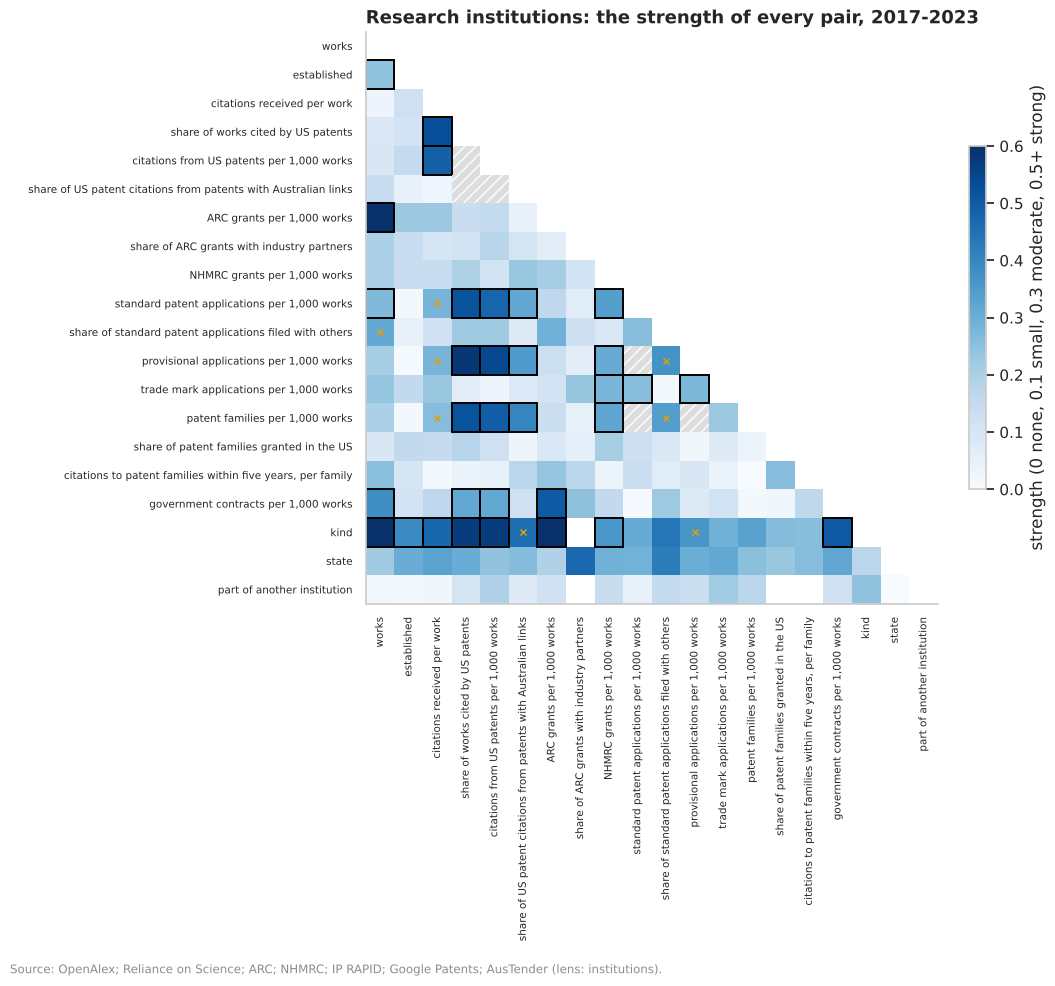

In [59]:
INS = bi.screens()["institutions"]


def institution_frame(a, b):
    d = sql(f"""
        SELECT ror, any_value(institution) AS institution, any_value(kind) AS kind, any_value(state) AS state,
               any_value(established) AS established, any_value(parent_ror) IS NOT NULL AS has_parent,
               sum(works) AS works, sum(citations) / sum(works) AS citations_per_work,
               sum(works_patent_cited) / sum(works) AS share_patent_cited,
               1000 * sum(patent_citations) / sum(works) AS patent_citations_per_kwork,
               sum(patent_citations_au) / nullif(sum(patent_citations), 0) AS au_share_of_patent_citations,
               1000 * sum(arc_grants) / sum(works) AS arc_grants_per_kwork,
               sum(arc_industry_grants) / nullif(sum(arc_grants), 0) AS arc_industry_share,
               1000 * sum(nhmrc_grants) / sum(works) AS nhmrc_grants_per_kwork,
               1000 * sum(patents_standard) / sum(works) AS patents_per_kwork,
               sum(patents_standard_shared) / nullif(sum(patents_standard), 0) AS shared_patent_share,
               1000 * sum(patents_provisional) / sum(works) AS provisionals_per_kwork,
               1000 * sum(trade_marks) / sum(works) AS trade_marks_per_kwork,
               1000 * sum(patent_families) / sum(works) AS families_per_kwork,
               sum(patent_families_us_granted) / nullif(sum(patent_families), 0) AS us_granted_share,
               sum(patent_family_citations_5y) / nullif(sum(patent_families), 0) AS family_citations_per_family,
               1000 * sum(contracts) / sum(works) AS contracts_per_kwork
        FROM {{lens/institutions}} WHERE year BETWEEN {a} AND {b} GROUP BY 1 HAVING sum(works) >= 100 ORDER BY 1
    """)
    return d.set_index("ror")


ins = {"discovery": institution_frame(2017, 2023), "replication": institution_frame(2010, 2016)}
nkind = {c: "number" for c in ["works", "established", *INS["ratios"]] if c != "has_parent"}
nkind |= {"kind": "category", "state": "category", "has_parent": "category"}
sprep = {p: bi.prepare(d, nkind, min_level=5) for p, d in ins.items()}
sres = {p: bi.screen(sprep[p], groups=INS["groups"], min_n=20) for p in sprep}
smm = bi.replicate(sres["discovery"], sres["replication"])
ins_leads = bi.distinct_leads(smm, INS["groups"])


def slab(c):
    return INS["ratios"].get(c, c.replace("_", " "))


print(
    "Institutions:",
    {p: len(d) for p, d in ins.items()},
    "; by kind (discovery):",
    ins["discovery"].kind.value_counts().to_dict(),
)
display(bi.verdict_counts(smm).to_frame("pairs").T.assign(**{"distinct leads": len(ins_leads)}))
fig = bi.strength_map(
    smm, list(nkind), label=slab, title="Research institutions: the strength of every pair, 2017-2023"
)
style.source(
    fig, "OpenAlex; Reliance on Science; ARC; NHMRC; IP RAPID; Google Patents; AusTender (lens: institutions)."
)
ins_table = bi.leads_table(ins_leads, sprep["discovery"], sres["discovery"], label=slab)
with pd.option_context("display.max_rows", 80, "display.width", 250):
    display(ins_table.assign(rho=ins_leads.rho.round(3).to_numpy()).round(3))

In [60]:
# The IP detail (institution_rights): how each right was matched and shared, in two halves of its rows
ir = bi.run_screen("institution_rights")
print("Rows in each half:", ir["n"])
display(
    ir["verdicts"][["variable 1", "variable 2", "measure", "strength", "strength (replication)", "verdict"]].round(3)
)
display(
    sql("""
    SELECT ip_right_type, count(*) AS rights, 100 * avg(shared::int) AS "filed with others (%)",
           100 * avg(shared_with_institution::int) AS "with another institution (%)",
           100 * avg((matched_by = 'abn')::int) AS "matched by ABN only (%)"
    FROM {lens/institution_rights} GROUP BY 1 ORDER BY 2 DESC
""")
    .set_index("ip_right_type")
    .round(2)
)

Rows in each half: (15917, 15611)


,variable 1,variable 2,measure,strength,strength (replication),verdict
0,shared,shared_with_institution,cramer_v,0.684,0.68,by construction
1,matched_by,country_unknown,cramer_v,0.201,0.182,lead
2,ip_right_type,shared,cramer_v,0.14,0.146,lead
3,ip_right_type,matched_by,cramer_v,0.118,0.118,lead
4,ip_right_type,country_unknown,cramer_v,0.108,0.1,not replicated
5,ip_right_type,shared_with_institution,cramer_v,0.083,0.096,negligible
6,matched_by,shared,cramer_v,0.039,0.04,negligible
7,country_unknown,shared,cramer_v,0.036,0.037,negligible
8,country_unknown,shared_with_institution,cramer_v,0.035,0.038,negligible
9,matched_by,shared_with_institution,cramer_v,0.016,0.026,negligible


,rights,filed with others (%),with another institution (%),matched by ABN only (%)
ip_right_type,,,,
patent,26668,21.41,10.98,0.23
trade_mark,4748,5.69,3.5,4.02
design,112,14.29,7.14,0


#### Observations
**B44 (observational). Across institutions, the kind of institution sorts most measures; research that patents cite
goes with the institution's own patenting.** 112 institutions with 100 or more works in 2017 to 2023 (43 universities,
42 medical research institutes, 11 public research agencies) and 111 in 2010 to 2016: 32 pairs are leads (18
distinct), 8 hold in one period only.
- **Kind:** universities win far more ARC grants per 1,000 works (a median 4.251) than medical research institutes
  (strength 0.898; 0.794 earlier); medical research institutes have the most citations from US patents per work
  (0.573; 0.694) and per work generally (0.474; 0.642).
- **Research and invention together:** the share of an institution's works cited by US patents rises with its own
  provisional applications per 1,000 works (rho 0.583; 0.488) and with the citations its works receive (0.529;
  0.518). NHMRC grants per work go with standard patents per work (0.338; 0.367).
- **Size:** larger institutions win more ARC grants per work (0.803; 0.826) and file somewhat more standard patents
  per work (0.269; 0.225).
- **The IP detail:** 21.41% of the institutions' patents are filed with others and 10.98% with another research
  institution, against 5.69% and 3.5% of their trade marks (type × filed with others, 0.14; 0.146). How a filer was
  matched goes with whether its country is known (0.201; 0.182), as the link's design expects (ADR 0021).

### 7.1 Research against IP, and industry partners against joint filing, among universities

**From:** U82 to U84. **Informs:** Q1, Q3. The 44 universities hold most of the institutions' works and IP, and are
alike enough to compare. Four pairs, each in both periods with a 95% bootstrap interval for its strength: size
(works) against patents per 1,000 works; citations per work against patents per 1,000 works; the share of ARC grants
with industry partners against the share of patents filed with others; and the share of works cited by US patents
against patents per 1,000 works. Then the same universities' **changes** between the periods.

In [61]:
PAIRS = [
    ("works", "patents_per_kwork"),
    ("citations_per_work", "patents_per_kwork"),
    ("arc_industry_share", "shared_patent_share"),
    ("share_patent_cited", "patents_per_kwork"),
    ("arc_grants_per_kwork", "patents_per_kwork"),
]
rows = []
for p, d in ins.items():
    u = d[d.kind == "university"]
    for a, b in PAIRS:
        x, y = u[a].astype(float), u[b].astype(float)
        ok = x.notna() & y.notna()
        rho = x[ok].corr(y[ok], method="spearman")
        lo, hi = bi.strength_interval(x[ok], y[ok], "number", "number", reps=400)
        rows.append(
            {
                "pair": f"{slab(a)} × {slab(b)}",
                "period": {"discovery": "2017-2023", "replication": "2010-2016"}[p],
                "universities": int(ok.sum()),
                "rho": rho,
                "95% interval (strength)": f"{lo:.2f} to {hi:.2f}",
            }
        )
display(pd.DataFrame(rows).set_index(["pair", "period"]).round(3).unstack("period"))
a, b = ins["replication"], ins["discovery"]
both = a.index.intersection(b.index)
both = [r for r in both if b.at[r, "kind"] == "university"]
ch = pd.DataFrame(
    {
        "works (log change)": np.log(b.loc[both, "works"] / a.loc[both, "works"]),
        "patents per 1,000 works (change)": b.loc[both, "patents_per_kwork"] - a.loc[both, "patents_per_kwork"],
        "industry share of ARC grants (change)": b.loc[both, "arc_industry_share"] - a.loc[both, "arc_industry_share"],
    }
).astype(float)
print(f"Universities in both periods: {len(ch)}")
display(ch.corr(method="spearman").round(3))
print(
    f"Median change in patents per 1,000 works: {ch.iloc[:, 1].median():.4f}; universities whose rate fell:",
    int((ch.iloc[:, 1] < 0).sum()),
    "; rose:",
    int((ch.iloc[:, 1] > 0).sum()),
)

universities                 rho           95% interval (strength)  \
period                                                                                        2010-2016 2017-2023 2010-2016 2017-2023               2010-2016   
pair                                                                                                                                                            
ARC grants per 1,000 works × standard patent applications per 1,000 works                            42        43     0.628     0.637            0.43 to 0.79   
citations received per work × standard patent applications per 1,000 works                           42        43     0.619     0.417            0.43 to 0.77   
share of ARC grants with industry partners × share of standard patent applications file...           33        36    -0.074     0.127            0.01 to 0.43   
share of works cited by US patents × standard patent applications per 1,000 works                    42        43     0.759     0.632            0.52 to 0.89   
works × standard patent applications per 1,000 works                                                 42        43     0.732     0.743            0.56 to 0.86   

                                                                                                          
period                                                                                         2017-2023  
pair                                                                                                      
ARC grants per 1,000 works × standard patent applications per 1,000 works                   0.41 to 0.80  
citations received per work × standard patent applications per 1,000 works                  0.11 to 0.69  
share of ARC grants with industry partners × share of standard patent applications file...  0.00 to 0.50  
share of works cited by US patents × standard patent applications per 1,000 works           0.38 to 0.81  
works × standard patent applications per 1,000 works                                        0.57 to 0.87

Universities in both periods: 42


,works (log change),"patents per 1,000 works (change)",industry share of ARC grants (change)
works (log change),1,0.111,-0.192
"patents per 1,000 works (change)",0.111,1,-0.221
industry share of ARC grants (change),-0.192,-0.221,1


Median change in patents per 1,000 works: 0.0000; universities whose rate fell: 17 ; rose: 19


#### Observations
**B45 (observational). Among universities, the larger ones, the more cited and those whose research patents draw on
file more patents per work; industry-partner grants do not go with joint filing.** Spearman's rho over 43
universities in 2017 to 2023 (42 in 2010 to 2016), with 95% intervals for the strength:
- **Size (works) against patents per 1,000 works:** 0.743 (0.57 to 0.87); 0.732 (0.56 to 0.86).
- **Share of works cited by US patents:** 0.632 (0.38 to 0.81); 0.759 (0.52 to 0.89).
- **ARC grants per 1,000 works:** 0.637 (0.41 to 0.80); 0.628 (0.43 to 0.79).
- **Citations per work:** 0.417 (0.11 to 0.69); 0.619 (0.43 to 0.77).
- **The share of ARC grants with industry partners against the share of patents filed with others:** 0.127 and
  -0.074 over 36 and 33 universities: no link. Universities that do more industry-partnered research do not file
  more of their patents jointly.
- **As changes** between the periods (42 universities), growth in works goes with the change in patents per work at
  only 0.111, and a rising industry share of ARC grants with a falling patent rate (-0.221): the levels' strong links
  are about which universities are research-intensive, not about what changes within them.
- Third factors: research intensity and medical schools (NHMRC, B44), and the commercialisation companies that file
  for the largest universities (U83).

### 7.2 Australian research cited by patents, against the Australian links of the patents that cite it

**From:** U85. **Informs:** Q1, Q4. For each institution, the share of its works cited by US patents and the share of
those citations that come from patents with an Australian applicant or inventor, beside its own patenting: is
research that Australian inventions use done by the institutions that patent most?

In [62]:
rows = []
for p, d in ins.items():
    d = d[d.works >= 1000]
    for a, b in (
        ("au_share_of_patent_citations", "patents_per_kwork"),
        ("au_share_of_patent_citations", "share_patent_cited"),
    ):
        x, y = d[a].astype(float), d[b].astype(float)
        ok = x.notna() & y.notna()
        rows.append(
            {
                "pair": f"{slab(a)} × {slab(b)}",
                "period": p,
                "institutions": int(ok.sum()),
                "rho": x[ok].corr(y[ok], method="spearman"),
            }
        )
    rows.append(
        {
            "pair": "median share of US patent citations from patents with Australian links (%)",
            "period": p,
            "institutions": int(d.au_share_of_patent_citations.notna().sum()),
            "rho": 100 * d.au_share_of_patent_citations.median(),
        }
    )
pd.DataFrame(rows).set_index(["pair", "period"]).round(3).unstack("period")

institutions                   rho            
period                                                                                        discovery replication discovery replication
pair                                                                                                                                     
median share of US patent citations from patents with Australian links (%)                           82          69     3.252       5.482
share of US patent citations from patents with Australian links × share of works cited ...           82          69     0.361       0.082
share of US patent citations from patents with Australian links × standard patent appli...           82          69     0.298       0.165

#### Observations
**B46 (observational). Few US patents citing Australian research have Australian links, and the share does not
consistently follow the institution's own patenting.** For institutions with 1,000 or more works, the median share of
their US patent citations that come from patents with an Australian applicant or inventor is 3.252% in 2017 to 2023
(82 institutions) and 5.482% in 2010 to 2016 (69). Against the institution's patents per 1,000 works: rho 0.298, then
0.165; against the share of its works cited by patents: 0.361, then 0.082. Australian research is used mostly by
inventions owned and made elsewhere (U85, U96), whichever Australian institutions patent most: a lead for Q1 (value
created here and captured abroad, as in B19) and Q4.

### 7.3 Summary of the institutions lens

| # | Pair | What was found | Strength | Holds in the other period? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B44 | Every pair across institutions | Kind sorts most measures; research that patents cite goes with own patenting | observational | yes | Kind as third factor |
| B45 | Universities' research × patenting | Size, patent-cited research and ARC success go with patents per work; industry grants do not go with joint filing; changes weak | observational | levels yes, changes weak | Yes: Q1, Q3 |
| B46 | Australian links of patents citing research | 3% to 5%; not tied to own patenting | observational | no (weak) | Yes: Q1, Q4 |

The institutions link has not yet been reviewed by someone in the sector (OQ11); these pairs rest on it.

## 8. Summary of Stage 2

Every lens and every companion table has been screened (ADR 0030; `screens.yaml` names every column), and each
planned pair of the Stage 1 summary has its sizes, intervals, second period or half, and third factors (B1 to B46).
The fuller account is `docs/stage-2-summary.md`.

**Signals carried to Stage 3** (all observational: associations, not effects):

| # | Signal | Lens | Question |
|---|---|---|---|
| B6, B10 | Filing alone goes with far fewer grants (standard patents about 36 points, Australian individuals) and fewer renewals (trade marks and designs) | rights | Q2, Q4 |
| B8, B11, B12 | Australian organisations keep patents longer than overseas ones, file them in fewer countries, and are cited less mostly because of that narrower reach | rights | Q1 |
| B13 | Expedited examination goes with longer lives for overseas organisations only; pooled, a composition effect | rights | Q1, Q4 |
| B16, B19, B26, B46 | Inventions and research made here are often owned or used abroad: one patent in seven made here is filed from overseas; the patents that move overseas are the wide, granted ones and young firms'; 3% to 5% of US patents citing Australian research have Australian links | rights, firms, institutions | Q1 |
| B17, B18 | Women among inventors vary by field (4.2% to 26.9%), and on provisionals more on organisations' than individuals' | rights | Q2 |
| B22 to B24 | Within R&D claimants and suppliers, filing goes with company form, age and cities; R&D spend only weakly with patenting; missing filers are young private companies; suppliers with IP win more and larger contracts | firms | Q2, Q3, Q4 |
| B27 to B31 | Places file along one gradient of advantage, education and business density, steep in the top fifth, not one firm's; business mix matters, manufacturing's share does not | regions | Q2, Q4 |
| B32 to B35 | Across countries IP follows R&D and income; Australia's business R&D fell from 13th to 20th in the OECD, its patenting near what that predicts; changes in R&D barely move patenting | national | Q1, Q4 |
| B37 | Six policy changes give clean breaks against placebo dates | timeline | Q5 |
| B47, B49 | Fee changes rarely moved filing or lapsing beyond placebo months; patent cessations after the 2002 renewal rise did (added after Stage 2) | timeline | Q4, Q5 |
| B38 | FY2025 provisionals followed up less, individuals most (or recorded late: OQ18) | timeline | Q4 |
| B50, B51 | Among employers of 100 or more, filing rises with size and is sorted by industry; R&D's weak link to patenting holds within size (added after Stage 2) | firms | Q2, Q3 |
| B53, B54 | With ALP's crosswalk including services, patents per business follow business R&D across divisions (0.739) (added after Stage 2) | industries | Q2, Q3 |
| B40, B45 | Trade marks per business follow business R&D across divisions; universities' patenting follows size, patent-cited research and ARC success, not industry-partnered grants | industries, institutions | Q2, Q3 |

**Recorded, not carried:** the mechanics of the system (B2), a record quirk now handled by the register's fill (B3),
leads that did not hold in a second period (B7, B14; organisations' lone-filing gap in B6), and screens with no lead
beyond the expected (B36, B39, B43).

**Third factors named most often, for Stage 3:** the filer (origin and type), family reach, the route of filing, the
technology field, selection at grant, firm size and industry (not in the data), business density and mix, education,
income, and the kind of institution.

**Data gaps Stage 2 adds:** firms' size and industry (B21 to B24; BLADE stays ruled out; filled for employers of 100
or more after Stage 2, B50 and B51), ALP's crosswalk with services (B41; filled after Stage 2, B53 and B54), whether priority claims are recorded late (OQ18), the fee history (R3, OQ2; filled after Stage 2, B47 to B49), and
whether Google Patents holds older Australian-only families fully (B11).